<div style="border-radius:22px; padding:34px 30px 28px; background:linear-gradient(120deg, #C00000 0%, #6e0000 100%); color:#ffffff">
<div style="font-size:11px; letter-spacing:.32em; color:#ffc9c9">M.I.A ROBOTICS · VIDEO ENGINEERING SESSION</div>
<div style="font-size:34px; font-weight:800; margin:10px 0 6px">ROV Video Streaming Lab</div>
<div style="font-size:15px; color:#ffe1e1">Every experiment from the talk, in the order of the slides. Drag, encode, look.</div>
</div>

This notebook goes with `presentation/MIA_Video_Streaming.pptx`. Each red banner names the slide it belongs to, so you can open the matching experiment while the slide is on the screen.

**How to use it**

1. Run everything once: **Kernel → Restart Kernel and Run All Cells**. It takes 10–20 minutes the first time (it encodes a lot of video). After that, results are cached in `work/` and it's quick.
2. Then play with the panels. Panels marked **live** update while you drag. Panels marked **press Encode** re-encode real video with your settings.
3. Every number here is measured on *this* computer or calculated from a formula you can read in the cell. Anything that is a model or an estimate says so.

The test clip is a synthetic underwater scene (a pipeline, haze, marine snow, sensor noise). To use your own footage, set `ROV_SOURCE` before starting Jupyter: `ROV_SOURCE=my_dive.mp4 jupyter lab`.

**Contents**

| Slide | Part | Experiment | How |
|---|---|---|---|
| 6 | Physics first | What does the water cost in bits? | press Encode |
| 9 | Camera choice | Will the USB bus take another camera? | live: changes as you drag |
| 13–14 | Counting bits | How big is raw video? | live: changes as you drag |
| 15 | Counting bits | One hour of video, in Egyptian pounds | live: changes as you drag |
| 16 | Activity 1 | Check your card | live: changes as you drag |
| 17 | Measured | Same clip, four codecs | press Encode |
| 18 | Words that get mixed up | What does one packet cost on the wire? | live: changes as you drag |
| 21–22 | Digital video fundamentals | Colour at half resolution: can you see it? | live: changes as you drag |
| 23–25 | Prediction | Find the block in the last frame | live: changes as you drag |
| 26 | Transform + quantize | Where the bits are thrown away | live: changes as you drag |
| 28 | Frame types | I, P and B frames, and the GOP | press Encode |
| 29 | Experiments 3 and 6 | Quality target or bitrate cap? | press Encode |
| 30 | Why streamers obsess over bits | What is 1 % of Netflix's bitrate worth? | live: changes as you drag |
| 32 | Choosing a codec | The fair comparison: whole rate–quality curves | runs once |
| 33 | Codec ≠ container | Pull the power during a recording | press Encode |
| 34–35 | MJPEG on the ROV | The resolution trap | press Encode |
| 38 | Experiment 4 | Encoder presets: CPU against bits | press Encode |
| 39 | Experiment 5 | Packet loss and the keyframe interval | press Encode |
| 40 | Experiment 6 | PSNR, SSIM, and your own eyes | live: changes as you drag |
| 40 | Activity 3 | The blind test | press Encode |
| 42 | Who does the work? | Is the hardware encoder really there? | runs once |
| 43–45 | Jetson Nano vs Raspberry Pi 5 | How many streams can the ROV computer encode? | runs once |
| 46 | Reliability lesson from 2023 | Read the throttle flags | live: changes as you drag |
| 47 | Getting bits to the browser | TCP or UDP when packets get lost? | live: changes as you drag |
| 48 | Experiment 9 estimate | Build your own latency budget | live: changes as you drag |
| 49 | Experiment 9 measured | How many frames does the encoder hold? | runs once |
| 50 | Experiment 8 | Eight cameras on one tether | live: changes as you drag |
| 51 | Camera selection | Share a shrinking tether | live: changes as you drag |
| 52 | Streaming for computer vision | What compression does to corners | press Encode |
| 54 · 72 | Where is the problem? | Latency drift: a queue that only grows | live: changes as you drag |
| 73 | Field guide | A frozen picture that looks live | live: changes as you drag |
| 57 | Measure latency three ways | Your glass-to-glass readings | live: changes as you drag |
| 61 | The checklist | Run the health check | runs once |
| 62 | A practical optimization strategy | Design the eight-camera system | live: changes as you drag |
| 62 | Engineering log | What this run measured | runs once |

## Setup

Run these three cells and move on. They load the tools, make the test clip, and build the control panels. You don't need to read them to do the experiments, but everything below calls them, so they're short and plain.

```bash
pip install -r requirements.txt     # numpy pandas matplotlib scipy jupyterlab ipywidgets av
```
FFmpeg 5 or newer must be on your `PATH` (with `libx264`; `libx265` and `libsvtav1` are optional).

In [1]:
import os, sys, json, time, shutil, subprocess, resource, re, math, platform, random
from pathlib import Path
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

FFMPEG, FFPROBE = shutil.which("ffmpeg"), shutil.which("ffprobe")
assert FFMPEG and FFPROBE, "FFmpeg/ffprobe not found on PATH — see the installation section."

WORK = Path("work"); WORK.mkdir(exist_ok=True)
CPU_CORES = os.cpu_count()

# ---- chart style: one consistent, colour-blind-checked palette -------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
CRITICAL = "#c62828"   # reserved for "over the limit" — never used as a series colour
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4.2), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e3e2de", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 7,
})
pd.set_option("display.precision", 2)

def run(cmd, check=True):
    """Run a command; return wall time, CPU time (user+sys of the child) and stderr."""
    r0 = resource.getrusage(resource.RUSAGE_CHILDREN); t0 = time.perf_counter()
    p = subprocess.run(cmd, capture_output=True, text=True)
    wall = time.perf_counter() - t0; r1 = resource.getrusage(resource.RUSAGE_CHILDREN)
    cpu = (r1.ru_utime - r0.ru_utime) + (r1.ru_stime - r0.ru_stime)
    if check and p.returncode != 0:
        raise RuntimeError(f"Command failed ({p.returncode}): {' '.join(map(str, cmd))}\n{p.stderr[-1500:]}")
    return {"wall_s": wall, "cpu_s": cpu, "rc": p.returncode, "stderr": p.stderr, "stdout": p.stdout}

def probe(path):
    out = run([FFPROBE, "-v", "error", "-show_streams", "-show_format", "-of", "json", str(path)])["stdout"]
    j = json.loads(out); v = next(s for s in j["streams"] if s["codec_type"] == "video")
    dur = float(j["format"].get("duration", v.get("duration", 0)) or 0)
    size = Path(path).stat().st_size
    return {"codec": v["codec_name"], "profile": v.get("profile"), "pix_fmt": v.get("pix_fmt"),
            "width": v["width"], "height": v["height"], "fps": float(Fraction(v["avg_frame_rate"])) if v["avg_frame_rate"] != "0/0" else None,
            "duration_s": dur, "size_bytes": size, "bitrate_mbps": size * 8 / dur / 1e6 if dur else None}

def packets(path):
    """Per-packet table: pts (s), size (bytes), keyframe flag."""
    out = run([FFPROBE, "-v", "error", "-select_streams", "v:0", "-show_entries", "packet=pts_time,size,flags,pos",
               "-of", "csv=p=0", str(path)])["stdout"]
    rows = []
    for line in out.strip().splitlines():
        parts = line.split(",")
        if len(parts) < 4 or parts[0] in ("", "N/A"): continue
        rows.append((float(parts[0]), int(parts[1]), int(parts[2]) if parts[2] not in ("", "N/A") else -1, "K" in parts[3]))
    return pd.DataFrame(rows, columns=["pts", "size", "pos", "key"]).sort_values("pts").reset_index(drop=True)

def frame_types(path):
    out = run([FFPROBE, "-v", "error", "-select_streams", "v:0", "-show_entries", "frame=pict_type,pkt_size",
               "-of", "json", str(path)])["stdout"]
    frames = json.loads(out).get("frames", [])
    return pd.DataFrame([(f.get("pict_type", "?"), int(f.get("pkt_size", 0))) for f in frames], columns=["type", "size"])

def quality(dist, ref, width=None, height=None, per_frame=False):
    """PSNR (dB, luma+chroma average) and SSIM (0..1) of `dist` against `ref`.
    The distorted video is scaled back to the reference size first, so substreams can be compared too."""
    info = probe(ref); w, h = width or info["width"], height or info["height"]
    plog, slog = WORK / "psnr.log", WORK / "ssim.log"
    # Timestamps are snapped to the reference frame grid (settb): containers such as MKV store ms-rounded
    # timestamps, and without this every third frame would be compared with the wrong reference frame.
    sync = f"setpts=PTS-STARTPTS,settb=1/{FPS}"
    graph = (f"[0:v]scale={w}:{h}:flags=bicubic,format=yuv420p,{sync},split[d1][d2];"
             f"[1:v]format=yuv420p,{sync},split[r1][r2];"
             f"[d1][r1]psnr=stats_file={plog}[o1];[d2][r2]ssim=stats_file={slog}[o2]")
    ref_in = SRC_IN if Path(ref) == SRC else ["-i", str(ref)]
    r = run([FFMPEG, "-hide_banner", "-i", str(dist), *ref_in, "-lavfi", graph,
             "-map", "[o1]", "-f", "null", "-", "-map", "[o2]", "-f", "null", "-"])
    psnr = float(re.search(r"PSNR .*average:([\d.]+|inf)", r["stderr"]).group(1).replace("inf", "99"))
    ssim = float(re.search(r"SSIM .*All:([\d.]+)", r["stderr"]).group(1))
    if not per_frame:
        return psnr, ssim
    pf = [min(float(m.group(1).replace("inf", "99")), 99) for m in re.finditer(r"psnr_avg:([\d.]+|inf)", plog.read_text())]
    return psnr, ssim, np.array(pf)

def mbps_fmt(x, _=None):
    return f"{x:,.0f}" if x >= 10 else (f"{x:.1f}" if x >= 1 else f"{x:.2f}")

ENCODERS = run([FFMPEG, "-hide_banner", "-encoders"])["stdout"]
FILTERS = run([FFMPEG, "-hide_banner", "-filters"])["stdout"]
HAS = {name: (f" {name} " in ENCODERS) for name in ["libx264", "libx265", "libsvtav1", "libaom-av1", "mjpeg",
                                                   "h264_nvenc", "h264_vaapi", "h264_qsv", "h264_v4l2m2m"]}
HAS["libvmaf"] = " libvmaf " in FILTERS
print(run([FFMPEG, "-hide_banner", "-version"])["stdout"].splitlines()[0])
print(f"Python {platform.python_version()} on {platform.machine()} · {CPU_CORES} CPU cores")
print("Available:", ", ".join(k for k, v in HAS.items() if v))
print("Missing:  ", ", ".join(k for k, v in HAS.items() if not v) or "—")

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
Python 3.13.18 on x86_64 · 2 CPU cores
Available: libx264, libx265, libsvtav1, libaom-av1, mjpeg, h264_nvenc, h264_vaapi, h264_qsv, h264_v4l2m2m
Missing:   libvmaf


{'codec': 'ffv1', 'profile': None, 'pix_fmt': 'yuv420p', 'width': 1280, 'height': 720, 'fps': 30.0, 'duration_s': 6.0, 'size_bytes': 60625302, 'bitrate_mbps': 80.833736}


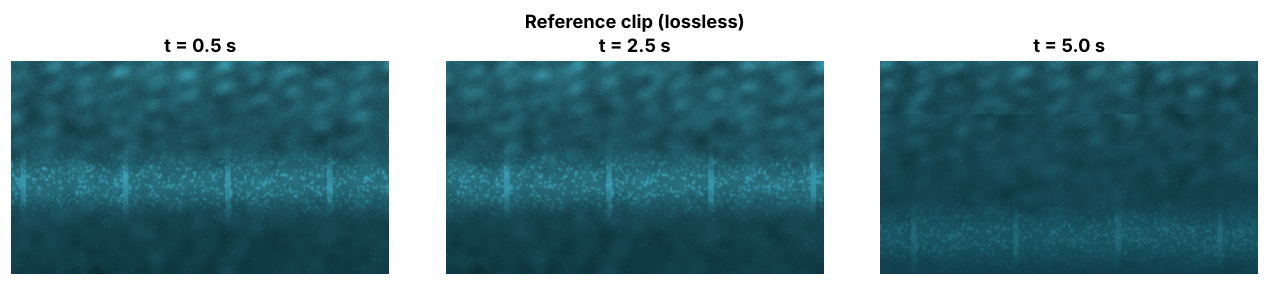

In [2]:
ROV_SOURCE = os.environ.get("ROV_SOURCE")   # e.g. "my_dive.mp4" — leave None for the synthetic clip
W, H, FPS, SECONDS = 1280, 720, 30, 6
N_FRAMES = FPS * SECONDS
SRC = WORK / "source.mkv"

def synth_underwater_clip(path, w=W, h=H, fps=FPS, n=N_FRAMES, seed=7):
    from scipy.ndimage import gaussian_filter
    rng = np.random.default_rng(seed)
    pan = 3                                             # pixels per frame of camera pan
    tex_w = w + 1200
    # Seabed / pipeline texture: low-frequency "rock" + high-frequency detail
    lo = gaussian_filter(rng.standard_normal((h, tex_w)), 18); lo /= np.abs(lo).max()
    hi = gaussian_filter(rng.standard_normal((h, tex_w)), 1.5); hi /= np.abs(hi).max()
    tex = 0.55 + 0.25 * lo + 0.12 * hi
    yy = np.arange(h)[:, None]
    pipe = np.exp(-((yy - 0.58 * h) / (0.11 * h)) ** 2)                # a horizontal pipeline
    seams = (np.sin(np.arange(tex_w) / 55.0) > 0.985).astype(float)    # weld seams
    tex = tex * (1 - 0.6 * pipe) + pipe * (0.75 + 0.15 * hi + 0.4 * seams[None, :])
    growth = gaussian_filter((rng.random((h, tex_w)) > 0.996).astype(float), 3) * 25
    tex = np.clip(tex + growth * pipe, 0, 1.4)
    depth = np.linspace(0, 1, h)[:, None]
    water = np.array([18, 92, 110]) / 255.0                            # blue-green water colour
    tint = np.array([0.35, 0.85, 0.95])                                # red absorbed first
    xs = np.arange(w)[None, :]
    p_n = 350; px = rng.uniform(0, w, p_n); py = rng.uniform(0, h, p_n)
    vx = rng.normal(0.4, 0.5, p_n); vy = rng.normal(-0.6, 0.4, p_n)
    cmd = [FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgb24",
           "-s", f"{w}x{h}", "-r", str(fps), "-i", "-", "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(path)]
    proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
    for i in range(n):
        t = i / fps
        if i < int(0.66 * n):                                          # camera 1: pan along the pipe
            view = tex[:, i * pan:i * pan + w]; turb = 0.35
        else:                                                          # camera 2: closer, darker view
            off = 600 + (i - int(0.66 * n)) * 2
            view = np.roll(tex[:, off:off + w], h // 4, axis=0) * 0.85; turb = 0.5
        caustic = (np.sin(xs / 37.0 + 2.1 * t) * np.sin(yy / 23.0 - 1.7 * t + xs / 90.0)) ** 2
        light = 0.75 + 0.35 * caustic * np.exp(-3 * depth)
        lum = view * light * (1.05 - 0.55 * depth)
        rgb = lum[..., None] * tint[None, None, :]
        haze = turb * (0.4 + 0.6 * depth)[..., None]                   # turbidity: fade to water colour
        rgb = rgb * (1 - haze) + water[None, None, :] * haze
        px += vx; py += vy; px %= w; py %= h                           # marine snow
        ix, iy = px.astype(int), py.astype(int)
        for dx, dy, a in ((0, 0, 0.5), (1, 0, 0.25), (0, 1, 0.25)):
            np.add.at(rgb, ((iy + dy) % h, (ix + dx) % w), a)
        rgb += rng.normal(0, 0.004, rgb.shape)                         # sensor noise (camera gain)
        proc.stdin.write((np.clip(rgb, 0, 1) * 255).astype(np.uint8).tobytes())
    proc.stdin.close(); proc.wait()

if not SRC.exists():
    if ROV_SOURCE:
        run([FFMPEG, "-y", "-hide_banner", "-i", ROV_SOURCE, "-t", str(SECONDS), "-vf",
             f"scale={W}:{H}:force_original_aspect_ratio=decrease,pad={W}:{H}:(ow-iw)/2:(oh-ih)/2,fps={FPS}",
             "-an", "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(SRC)])
    else:
        t0 = time.time(); tmp = WORK / "source_tmp.mkv"; synth_underwater_clip(tmp); tmp.rename(SRC)
        print(f"Synthetic clip generated in {time.time()-t0:.1f} s")

# Encoders read an uncompressed copy, so CPU measurements contain (almost) only encoding work.
SRC_RAW = WORK / "source.yuv"
if not SRC_RAW.exists():
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(SRC), "-f", "rawvideo", "-pix_fmt", "yuv420p", str(SRC_RAW)])
SRC_IN = ["-f", "rawvideo", "-pix_fmt", "yuv420p", "-s", f"{W}x{H}", "-r", str(FPS), "-i", str(SRC_RAW)]
info = probe(SRC); print(info)
# Show three frames from the clip
fig, axs = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, t in zip(axs, (0.5, 2.5, 5.0)):
    png = WORK / f"src_{t}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(t), "-i", str(SRC), "-frames:v", "1", str(png)])
    ax.imshow(plt.imread(png)); ax.set_title(f"t = {t} s"); ax.axis("off")
plt.suptitle("Reference clip (lossless)", fontweight="bold"); plt.tight_layout(); plt.show()

In [3]:
import hashlib
from IPython.display import HTML, Markdown, display

try:
    import ipywidgets as wdg
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False

display(HTML("<style>.jp-OutputArea-output img, .output_png img {display:block; margin:0 auto}"
             " .jp-RenderedHTMLCommon table {margin-left:auto; margin-right:auto}</style>"))

MIA_RED = "#C00000"
GOOD, BAD, GREY = "#2e7d32", "#c62828", "#8a8a8a"
BATCH = os.environ.get("NB_BATCH") == "1"   # set when the notebook is run unattended (build/run_nb.py)


def rate(mbps):
    """1493 -> '1.49 Gb/s', 8.2 -> '8.2 Mb/s', 0.42 -> '0.42 Mb/s'."""
    if mbps >= 1000:
        return f"{mbps / 1000:.2f} Gb/s"
    return f"{mbps:,.0f} Mb/s" if mbps >= 10 else (f"{mbps:.1f} Mb/s" if mbps >= 1 else f"{mbps:.2f} Mb/s")


def cards(items):
    """A row of number cards. items: (label, value, note) or (label, value, note, good) with good = True/False/None."""
    html = []
    for it in items:
        label, value, note = it[:3]; good = it[3] if len(it) > 3 else None
        colour = {True: GOOD, False: BAD, None: GREY}[good]
        html.append(f'<div style="min-width:130px; padding:12px 16px; margin:5px; border-radius:14px; background:#ffffff; '
                    f'border:1px solid #ececec; box-shadow:0 2px 10px rgba(0,0,0,.05); text-align:center; display:inline-block">'
                    f'<div style="font-size:10.5px; letter-spacing:.1em; text-transform:uppercase; color:#8a8a8a">{label}</div>'
                    f'<div style="font-size:22px; font-weight:750; color:#1d1d1f; margin-top:3px">{value}</div>'
                    f'<div style="font-size:11.5px; color:{colour}">{note or "&nbsp;"}</div></div>')
    display(HTML(f'<div style="text-align:center">{"".join(html)}</div>'))


def note(text):
    display(HTML(f'<p style="text-align:center; color:#52514e; margin:6px 0">{text}</p>'))


def delta(cur, ref, fmt, higher_is_better):
    """Text + colour flag for a change against a baseline."""
    d = cur - ref
    if abs(d) < 1e-9:
        return "same as baseline", None
    return f"{fmt(d)} vs baseline", (d > 0) == higher_is_better


def encode_cached(args, tag, vf=None, ext="mp4", pix_fmt="yuv420p"):
    """Encode the test clip with these FFmpeg arguments, measure it, and cache the result in work/."""
    key = hashlib.sha1(json.dumps([args, vf, ext, pix_fmt]).encode()).hexdigest()[:12]
    out = WORK / f"tune_{tag}_{key}.{ext}"; meta = out.with_suffix(".json")
    if out.exists() and meta.exists():
        return {**json.loads(meta.read_text()), "file": out}
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *(["-vf", vf] if vf else []), *args,
             "-pix_fmt", pix_fmt, "-an", str(out)])
    p = probe(out); psnr, ssim, pf = quality(out, SRC, per_frame=True)
    res = {"bitrate": p["bitrate_mbps"], "size": p["size_bytes"], "wall": r["wall_s"], "cpu": r["cpu_s"],
           "psnr": psnr, "ssim": ssim, "pf": [float(x) for x in pf]}
    meta.write_text(json.dumps(res))
    return {**res, "file": out}


def frame_png(path, t, tag):
    png = WORK / f"view_{tag}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(t), "-i", str(path), "-frames:v", "1", str(png)])
    return plt.imread(png)


def gray(img):
    """RGB(A) float image from frame_png -> luma 0..255."""
    return img[..., :3] @ np.array([0.299, 0.587, 0.114]) * 255.0


PANELS = {}


def panel(name, title, subtitle, spec, render, live=False):
    """A control panel.

    spec:   {argument: (kind, options, default, label)}
            kind = int | float -> options (min, max, step) · options | toggle | dropdown -> list · check · text
    render: function(**values) that shows the result for one setting.
    live:   redraw on every change (cheap maths). Otherwise the panel waits for the Encode button.
    """
    header = (f'<div style="text-align:center; border-radius:14px; padding:12px 16px; margin:8px 0; color:#ffffff; '
              f'background:linear-gradient(115deg, {MIA_RED} 0%, #7d0000 100%)">'
              f'<div style="font-size:10px; letter-spacing:.3em; color:#ffd0d0">{"LIVE" if live else "PRESS ENCODE"}</div>'
              f'<div style="font-size:18px; font-weight:700; margin-top:2px">{title}</div>'
              f'<div style="font-size:12.5px; color:#ffe6e6; margin-top:2px">{subtitle}</div></div>')
    defaults = {k: s[2] for k, s in spec.items()}
    if not HAS_WIDGETS:
        display(HTML(header)); print("ipywidgets is not installed: showing the default setting only.")
        render(**defaults); return
    ws, style = {}, {"description_width": "initial"}
    for k, (kind, opts, default, label) in spec.items():
        lay = wdg.Layout(width="310px")
        if kind == "int":
            ws[k] = wdg.IntSlider(value=default, min=opts[0], max=opts[1], step=opts[2], description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "float":
            ws[k] = wdg.FloatSlider(value=default, min=opts[0], max=opts[1], step=opts[2], description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "options":
            ws[k] = wdg.SelectionSlider(options=opts, value=default, description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "dropdown":
            ws[k] = wdg.Dropdown(options=opts, value=default, description=label, style=style, layout=lay)
        elif kind == "toggle":
            ws[k] = wdg.ToggleButtons(options=opts, value=default, description=label, style={**style, "button_width": "auto"})
        elif kind == "check":
            ws[k] = wdg.Checkbox(value=default, description=label, style=style, indent=False, layout=lay)
        elif kind == "text":
            ws[k] = wdg.Text(value=default, description=label, style=style, layout=wdg.Layout(width="640px"), continuous_update=False)
    out = wdg.Output(layout=wdg.Layout(width="100%"))
    status = wdg.HTML()
    button = wdg.Button(description="Encode", icon="play", button_style="danger", layout=wdg.Layout(width="160px"))

    def refresh(*_):
        t0 = time.perf_counter(); status.value = "<i>working…</i>"; button.disabled = True
        with out:
            out.clear_output(wait=True)
            try:
                render(**{k: w.value for k, w in ws.items()})
                status.value = f'<span style="color:{GREY}">updated in {time.perf_counter() - t0:.1f} s</span>'
            except Exception as exc:   # show the problem in the panel instead of breaking the widget
                print(f"This setting failed: {exc}"); status.value = f'<span style="color:{BAD}">failed</span>'
        button.disabled = False

    wide = [w for w in ws.values() if isinstance(w, (wdg.ToggleButtons, wdg.Text))]
    grid_items = [w for w in ws.values() if w not in wide]
    grid = wdg.GridBox(grid_items, layout=wdg.Layout(grid_template_columns="repeat(3, 320px)", justify_content="center", grid_gap="4px 10px"))
    rows = [wdg.HTML(header), *[wdg.HBox([w], layout=wdg.Layout(justify_content="center")) for w in wide], grid]
    if live:
        for w in ws.values():
            w.observe(refresh, names="value")
        rows.append(wdg.HBox([status], layout=wdg.Layout(justify_content="center")))
    else:
        button.on_click(refresh)
        rows.append(wdg.HBox([button, status], layout=wdg.Layout(justify_content="center", align_items="center", grid_gap="12px")))
    rows.append(out)
    display(wdg.VBox(rows, layout=wdg.Layout(border="1px solid #efefef", padding="0 8px 10px", width="100%")))
    PANELS[name] = {"widgets": ws, "button": button, "refresh": refresh, "out": out}
    if BATCH:   # unattended run: draw the default straight into the cell so the saved notebook shows a result
        status.value = f'<span style="color:{GREY}">default setting shown: run this cell to use the controls</span>'
        render(**defaults)
    else:
        refresh()


print("Panels ready" + ("" if HAS_WIDGETS else " (static mode: pip install ipywidgets for the controls)"))

Panels ready


<div style="border-radius:18px; padding:22px 26px; margin:40px 0 6px; background:#1d1d1f; color:#ffffff">
<div style="font-size:11px; letter-spacing:.3em; color:#ff8a8a">PART 01 · SLIDES 3–11</div>
<div style="font-size:26px; font-weight:800; margin-top:6px">Underwater video and our architecture</div>
<div style="font-size:14px; color:#c8c8c8; margin-top:4px">What the water does to the picture, and where our video gets compressed.</div>
</div>

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 6 · PHYSICS FIRST · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">What does the water cost in bits?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Murky, noisy water is the most expensive video there is.</div>
</div>

**Try it.** The panel films a small synthetic scene with the water settings you choose and encodes it with H.264 at the same quality (CRF 23). Push **sensor noise** up, or turn the **light** down (the camera raises its gain, so noise grows). The picture hardly changes. The bitrate does.

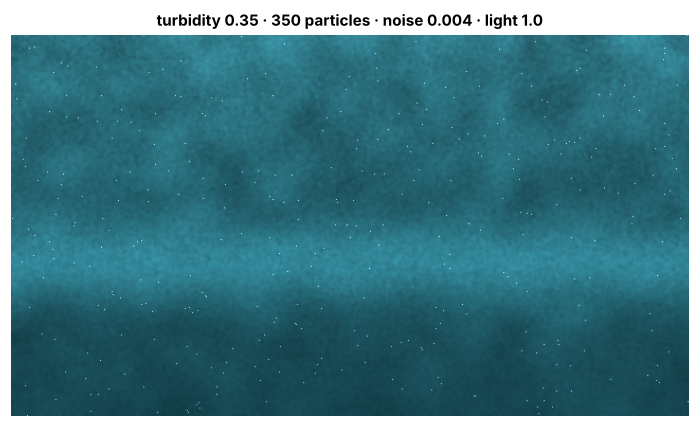

In [4]:
from scipy.ndimage import gaussian_filter

WW, WH, W_SECONDS = 640, 360, 2
_rng = np.random.default_rng(3)
_lo = gaussian_filter(_rng.standard_normal((WH, WW + 400)), 12); _lo /= np.abs(_lo).max()
_hi = gaussian_filter(_rng.standard_normal((WH, WW + 400)), 1.2); _hi /= np.abs(_hi).max()
_yy = np.arange(WH)[:, None]
_pipe = np.exp(-((_yy - 0.6 * WH) / (0.1 * WH)) ** 2)
SEABED = (0.55 + 0.25 * _lo + 0.12 * _hi) * (1 - 0.6 * _pipe) + _pipe * (0.75 + 0.15 * _hi)
WATER_RGB, RED_LOSS = np.array([18, 92, 110]) / 255, np.array([0.35, 0.85, 0.95])


def water_frames(turbidity, particles, noise, light, n, seed=1):
    """Frames of a camera panning over the seabed. The camera's gain makes up for low light, so noise grows as 1/light."""
    rng = np.random.default_rng(seed)
    depth = np.linspace(0, 1, WH)[:, None]
    px, py = rng.uniform(0, WW, particles), rng.uniform(0, WH, particles)
    vx, vy = rng.normal(0.4, 0.5, particles), rng.normal(-0.6, 0.4, particles)
    for i in range(n):
        lum = SEABED[:, 2 * i:2 * i + WW] * (1.05 - 0.55 * depth)
        rgb = lum[..., None] * RED_LOSS
        haze = (turbidity * (0.4 + 0.6 * depth))[..., None]
        rgb = rgb * (1 - haze) + WATER_RGB * haze
        if particles:
            px, py = (px + vx) % WW, (py + vy) % WH
            np.add.at(rgb, (py.astype(int), px.astype(int)), 0.5)
        if noise:
            rgb = rgb + rng.normal(0, noise / light, rgb.shape)
        yield (np.clip(rgb, 0, 1) * 255).astype(np.uint8)


def water_bitrate(turbidity, particles, noise, light):
    out = WORK / f"water_{turbidity:.2f}_{particles}_{noise}_{light}.mp4"
    if not out.exists():
        p = subprocess.Popen([FFMPEG, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgb24", "-s", f"{WW}x{WH}",
                              "-r", str(FPS), "-i", "-", "-c:v", "libx264", "-preset", "veryfast", "-crf", "23",
                              "-pix_fmt", "yuv420p", str(out)], stdin=subprocess.PIPE)
        for f in water_frames(turbidity, particles, noise, light, FPS * W_SECONDS):
            p.stdin.write(f.tobytes())
        p.stdin.close(); p.wait()
    return out.stat().st_size * 8 / W_SECONDS / 1e6


CLEAR_WATER = water_bitrate(0.35, 0, 0, 1.0)


def water_view(turbidity, particles, noise, light):
    mbps = water_bitrate(turbidity, particles, noise, light)
    frame = next(water_frames(turbidity, particles, noise, light, 1))
    cards([("bitrate at CRF 23", rate(mbps), "same quality target every time"),
           ("clear, still water", rate(CLEAR_WATER), "no particles, no noise"),
           ("cost of this water", f"{mbps / CLEAR_WATER:.1f}×", "more bits than clear water", mbps / CLEAR_WATER < 1.5)])
    plt.figure(figsize=(8, 4.5)); plt.imshow(frame); plt.axis("off")
    plt.title(f"turbidity {turbidity:.2f} · {particles} particles · noise {noise} · light {light}", fontsize=10); plt.show()


panel("water", "The price of murky water", "Same encoder, same quality target: only the water changes",
      {"turbidity": ("float", (0, 0.8, 0.05), 0.35, "turbidity (haze)"),
       "particles": ("int", (0, 1500, 50), 350, "marine snow particles"),
       "noise": ("options", [0, 0.002, 0.004, 0.008, 0.016, 0.03], 0.004, "sensor noise"),
       "light": ("options", [0.25, 0.5, 0.75, 1.0], 1.0, "light (1 = bright)")}, water_view)

**Look for**
- Noise and particles are new, random detail in every frame. The encoder can't predict them from the last frame, so it pays for them.
- Halving the light doubles the noise after the camera's gain. Good lights are a bandwidth saving.
- Haze on its own is cheap: it *removes* detail. It's bad for the pilot, not for the tether.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 9 · CAMERA CHOICE · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Will the USB bus take another camera?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">USB 2.0 is 480 Mb/s for the whole bus, and cameras book their share in advance.</div>
</div>

**Try it.** Add cameras until one won't start. Then switch the format from raw YUYV to MJPEG. Tick *camera books its maximum* to see why some cheap MJPEG cameras still fail.

This is a model of the bus budget, not a measurement: on the ROV, confirm with `lsusb -t` and `dmesg` (look for `No space left on device`).

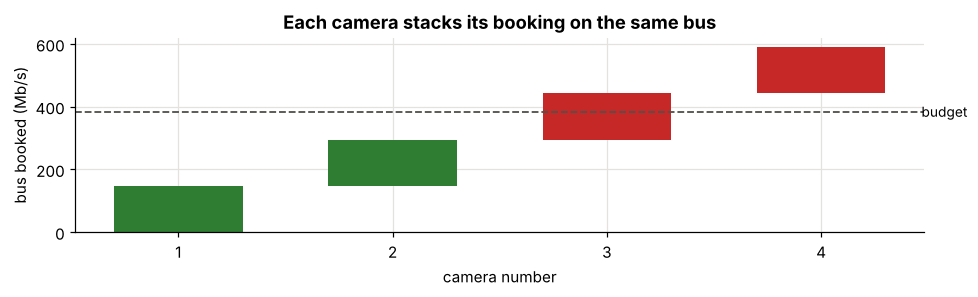

In [5]:
USB_BUDGET = {"USB 2.0": 0.8 * 480, "USB 3.0": 0.9 * 4000}   # periodic share; USB 3 after 8b/10b coding (approximate)
ISO_MAX_USB2 = 3 * 1024 * 8 * 8000 / 1e6                      # 196.6 Mb/s: the most one high-speed camera can book
CAM_RES = {"320×240": (320, 240), "640×480": (640, 480), "1280×720": (1280, 720), "1920×1080": (1920, 1080)}
MJPEG_BPP = 0.34                                               # measured at good quality (Activity 1, card B)


def usb_view(cams, fmt, res, fps, bus, books_max):
    w, h = CAM_RES[res]
    need = w * h * fps * (16 if fmt == "raw YUYV" else MJPEG_BPP) / 1e6
    booked = ISO_MAX_USB2 if (fmt == "MJPEG" and books_max and bus == "USB 2.0") else need
    budget = USB_BUDGET[bus]
    too_big = bus == "USB 2.0" and need > ISO_MAX_USB2
    fit = 0 if too_big else min(cams, int(budget // booked))
    cards([("one camera needs", rate(need), fmt),
           ("one camera books", rate(booked), "its share of the bus"),
           ("bus budget", rate(budget), f"{bus}, periodic share"),
           ("cameras that start", f"{fit} of {cams}", "camera too big for USB 2.0 on its own" if too_big else
            ("all fine" if fit == cams else f"camera {fit + 1} fails"), fit == cams)])
    used = np.cumsum([booked] * cams)
    plt.figure(figsize=(9, 2.8))
    plt.bar(range(1, cams + 1), [booked] * cams, bottom=used - booked,
            color=[GOOD if (u <= budget and not too_big) else BAD for u in used], width=0.6)
    plt.axhline(budget, color="#52514e", ls="--", lw=1.2); plt.text(cams + 0.45, budget, " budget", va="center", fontsize=9)
    plt.xlabel("camera number"); plt.ylabel("bus booked (Mb/s)"); plt.xticks(range(1, cams + 1))
    plt.title("Each camera stacks its booking on the same bus"); plt.tight_layout(); plt.show()


panel("usb", "USB bus budget", "Raw video eats the bus; MJPEG fits more cameras",
      {"fmt": ("toggle", ["raw YUYV", "MJPEG"], "raw YUYV", "format"),
       "bus": ("toggle", ["USB 2.0", "USB 3.0"], "USB 2.0", "bus"),
       "cams": ("int", (1, 8, 1), 4, "cameras on this bus"),
       "res": ("options", list(CAM_RES), "640×480", "resolution"),
       "fps": ("options", [5, 10, 15, 30], 30, "fps"),
       "books_max": ("check", None, False, "camera books its maximum (common with cheap MJPEG cameras)")}, usb_view, live=True)

**Look for**
- Raw 640×480 at 30 fps is 147 Mb/s per camera: two fit on one USB 2.0 bus, the third fails. That's slide 14 and Activity 1, card A.
- A USB 2.0 camera plugged into a USB 3.0 port still uses the USB 2.0 part of the controller. The USB 3.0 setting only helps with USB 3 cameras.
- The fix is rarely "lower the resolution": use MJPEG modes and spread cameras over separate controllers.

<div style="border-radius:18px; padding:22px 26px; margin:40px 0 6px; background:#1d1d1f; color:#ffffff">
<div style="font-size:11px; letter-spacing:.3em; color:#ff8a8a">PART 02 · SLIDES 12–18</div>
<div style="font-size:26px; font-weight:800; margin-top:6px">Bandwidth engineering</div>
<div style="font-size:14px; color:#c8c8c8; margin-top:4px">Count the bits before you plug anything in.</div>
</div>

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 13–14 · COUNTING BITS · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">How big is raw video?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">R = W × H × bits per pixel × frames per second</div>
</div>

$$R_{\text{raw}} = W \times H \times \text{bpp} \times f$$

Worked out for one 1080p camera in RGB: $1920 \times 1080 \times 24 \times 30 = 1.49$ Gb/s. That's one camera, already bigger than a gigabit link.

**Try it.** Pick a camera and a count. The chart compares the total with the links we actually have.

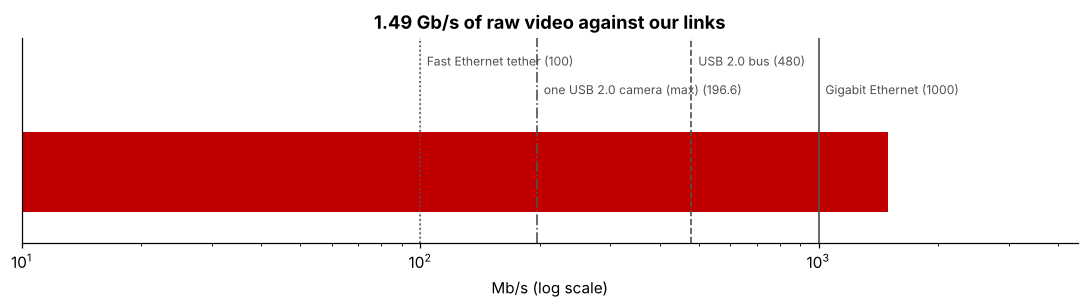

In [6]:
PIXEL_FORMATS = {"RGB24": 24, "YUYV 4:2:2": 16, "NV12 4:2:0": 12}
RESOLUTIONS = {"640×480": (640, 480), "1280×720": (1280, 720), "1920×1080": (1920, 1080), "3840×2160": (3840, 2160)}
LINKS = {"Fast Ethernet tether": 100, "one USB 2.0 camera (max)": 196.6, "USB 2.0 bus": 480, "Gigabit Ethernet": 1000}


def raw_mbps(w, h, fps, bpp):
    return w * h * bpp * fps / 1e6


def raw_view(res, fmt, fps, cams):
    w, h = RESOLUTIONS[res]; one = raw_mbps(w, h, fps, PIXEL_FORMATS[fmt]); total = one * cams
    cards([("one camera", rate(one), f"{res} {fmt} @ {fps}"),
           (f"{cams} cameras", rate(total), "uncompressed"),
           ("vs 100 Mb/s tether", f"{total / 100:,.1f}×", "fits" if total <= 100 else "does not fit", total <= 100),
           ("vs gigabit", f"{total / 1000:,.2f}×", "fits" if total <= 1000 else "does not fit", total <= 1000)])
    fig, ax = plt.subplots(figsize=(10, 2.9))
    ax.barh([0], [total], color=MIA_RED, height=0.45)
    for k, ((name, cap), ls) in enumerate(zip(LINKS.items(), (":", "-.", "--", "-"))):
        ax.axvline(cap, color="#52514e", ls=ls, lw=1.1)
        ax.text(cap * 1.04, 0.62 - 0.16 * (k % 2), f"{name} ({cap:g})", fontsize=8, color="#52514e", va="center")
    ax.set_xscale("log"); ax.set_xlim(10, max(total, 1000) * 3); ax.set_ylim(-0.4, 0.75); ax.set_yticks([])
    ax.set_xlabel("Mb/s (log scale)"); ax.set_title(f"{rate(total)} of raw video against our links"); plt.tight_layout(); plt.show()


panel("raw", "Raw bandwidth", "Uncompressed video against the links we own",
      {"fmt": ("toggle", list(PIXEL_FORMATS), "RGB24", "pixel format"),
       "res": ("options", list(RESOLUTIONS), "1920×1080", "resolution"),
       "fps": ("options", [10, 15, 25, 30, 60], 30, "fps"),
       "cams": ("int", (1, 8, 1), 1, "cameras")}, raw_view, live=True)

**Look for**
- Nothing raw above 640×480 fits a 100 Mb/s tether, and eight raw 1080p cameras need about 12 Gb/s. Compression isn't an option to tune; it's the whole system.
- The pixel format alone changes the size by 2×: RGB 24, YUYV 16, NV12 12 bits per pixel (slide 21 explains why).

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 15 · COUNTING BITS · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">One hour of video, in Egyptian pounds</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Compression makes video about 300× cheaper.</div>
</div>

**Try it.** Pick a stream and a price. Prices are the WE entry package from 1 Nov 2026: 100 GB for EGP 171 with VAT, about EGP 1.71 per GB. They change often: check te.eg and type the new price in.

In [7]:
STREAMS_EGP = {"Raw RGB 1080p30": 1493, "Raw 4:2:0 1080p30": 746, "MJPEG 720p30": 8.2,
               "H.264 HD streaming": 5, "Our pilot camera (H.264)": 2}


def egp_view(stream, hours, price_gb, package_gb, speed_MBps):
    mbps = STREAMS_EGP[stream]
    gb = mbps * hours * 3600 / 8 / 1000
    lasts_h = package_gb / (mbps * 3600 / 8 / 1000)
    download_h = gb * 1000 / speed_MBps / 3600
    lasts = f"{lasts_h * 60:.0f} minutes" if lasts_h < 1 else f"{lasts_h:,.0f} hours"
    took = f"{download_h * 60:.1f} minutes" if download_h < 1 else f"{download_h:,.1f} hours"
    cards([("data", f"{gb:,.2f} GB", f"{hours} h of {stream}"),
           ("cost", f"EGP {gb * price_gb:,.2f}", f"at EGP {price_gb}/GB", gb * price_gb < 50),
           (f"{package_gb} GB package lasts", lasts, "of this stream"),
           ("download time", took, f"at {speed_MBps} MB/s")])


panel("egp", "Video in Egyptian pounds", "The same hour, raw or compressed",
      {"stream": ("dropdown", list(STREAMS_EGP), "Raw RGB 1080p30", "stream"),
       "hours": ("int", (1, 24, 1), 1, "hours"),
       "price_gb": ("options", [1.0, 1.25, 1.5, 1.71, 2.0, 2.5], 1.71, "EGP per GB"),
       "package_gb": ("options", [100, 150, 200, 300], 100, "package (GB)"),
       "speed_MBps": ("options", [1.25, 3.75, 10, 12.5], 10, "download speed (MB/s)")}, egp_view, live=True)

**Look for**
- Raw: about EGP 1,150 for the hour, and the month's 100 GB lasts nine minutes. H.264 at 5 Mb/s: about EGP 3.85.
- A 30 Mb/s line (3.75 MB/s) would need about 50× more speed just to carry raw 1080p30 live.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 16 · ACTIVITY 1 · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Check your card</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Raw → compressed → overhead → 70 % budget → verdict → measurement</div>
</div>

Do the card on paper first. Then pick your card here and tick **show the working**.

In [8]:
A1_CARDS = {
    "A": ("8 USB cameras, raw YUYV 640×480 @ 30 fps, all on one USB 2.0 hub.",
          [("raw per camera", "640 × 480 × 16 × 30 = 147.5 Mb/s"), ("raw total", "8 × 147.5 = 1,180 Mb/s"),
           ("compressed", "none: raw video crosses the USB bus"), ("budget", "USB periodic share = 80 % of 480 = 384 Mb/s"),
           ("verdict", "OVER on the USB bus, not the tether: only 2 cameras fit"),
           ("measure", "lsusb -t (all on one bus?), start cameras one by one, dmesg: 'No space left on device'")]),
    "B": ("8 cameras, MJPEG 1280×720 @ 30 fps over HTTP, 100 Mb/s tether, MJPEG ≈ 0.34 bits per pixel.",
          [("raw per camera", "1280 × 720 × 16 × 30 = 442 Mb/s (YUYV)"), ("compressed", "0.34 × 1280 × 720 × 30 = 9.4 Mb/s each → 75.2 Mb/s"),
           ("on the wire", "+6 % for HTTP/TCP → about 79.7 Mb/s"), ("budget", "70 % of 100 = 70 Mb/s"),
           ("verdict", "TIGHT, effectively over: no room for keyframe peaks or control"),
           ("measure", "the real MJPEG bitrate: iftop, or record 30 s and divide size by time")]),
    "C": ("8 cameras, H.264 1920×1080 @ 30 fps at 4 Mb/s each, RTP/UDP, 100 Mb/s tether, all encoded by a Jetson Nano.",
          [("raw per camera", "1920 × 1080 × 12 × 30 = 746 Mb/s (4:2:0)"), ("compressed", "8 × 4 = 32 Mb/s"),
           ("on the wire", "+5 % for RTP/UDP → about 33.7 Mb/s = 48 %"), ("tether", "OK"),
           ("verdict", "the hidden bottleneck: the Nano encodes 4 × 1080p30, so 8 is 2× over its encoder"),
           ("measure", "tegrastats (encoder load), dropped frames; or let IP cameras encode")]),
    "D": ("1 camera H.264 1080p30 at 6 Mb/s (main) + 7 cameras H.264 640×360 @ 15 fps at 0.5 Mb/s (substreams), RTP/UDP, 100 Mb/s.",
          [("raw", "main 746 Mb/s; each substream 640 × 360 × 12 × 15 = 41.5 Mb/s"), ("compressed", "6 + 7 × 0.5 = 9.5 Mb/s"),
           ("on the wire", "+5 % → about 10 Mb/s = 14 % of the link"), ("verdict", "OK, lots of headroom"),
           ("measure", "do the cameras really offer substreams? camera web page, ffprobe; measure real bitrates")]),
}


def a1_view(card, show):
    text, steps = A1_CARDS[card]
    html = f'<div style="max-width:760px; margin:6px auto; padding:14px 18px; border-radius:14px; border:1px solid #ececec">' \
           f'<div style="font-size:11px; letter-spacing:.2em; color:{MIA_RED}">CARD {card}</div><div style="font-size:15px; margin-top:4px">{text}</div>'
    if show:
        html += "".join(f'<div style="margin-top:8px"><b>{k}</b>: {v}</div>' for k, v in steps)
    else:
        html += f'<div style="margin-top:10px; color:{GREY}">Work it out on paper, then tick "show the working".</div>'
    display(HTML(html + "</div>"))


panel("a1", "Activity 1 answer check", "Scoring: arithmetic 4 · verdict 3 · measurement 3 · +3 for a hidden bottleneck",
      {"card": ("toggle", list(A1_CARDS), "A", "card"), "show": ("check", None, False, "show the working")}, a1_view, live=True)

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 17 · MEASURED · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Same clip, four codecs</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Compression is the core of the system: change the codec, not the picture size.</div>
</div>

First a fixed comparison at typical settings, then a panel where you pick the codec and a quality level from 1 (smallest file) to 10 (best picture).

Raw 4:2:0 size of the clip: 249 MB  (332 Mb/s)


codec,size_MB,bitrate_Mb/s,compression_ratio,encode_fps,cores_used,PSNR_dB,SSIM
"H.264 (x264, CRF 23)",1.42,1.90,175:1,112,1.7,46.6,0.9836
"H.265 (x265, CRF 28)",0.42,0.56,595:1,36,1.9,40.4,0.9613
MJPEG (q:v 5),6.15,8.20,40:1,376,1.6,45.5,0.9785
"AV1 (SVT-AV1, CRF 35)",0.55,0.74,449:1,23,1.9,43.4,0.9771


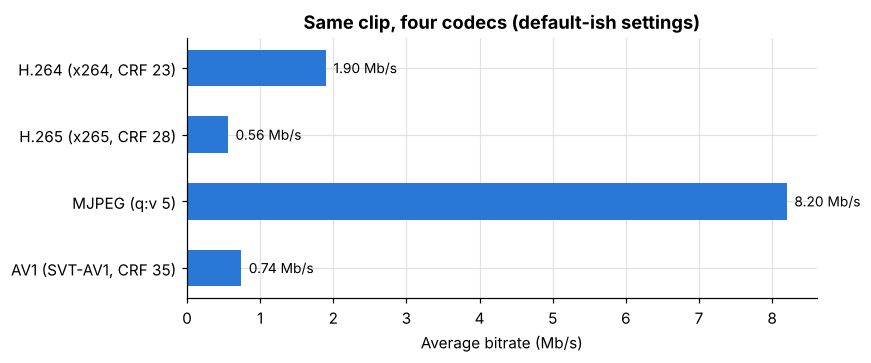

In [9]:
E2 = [
    ("H.264 (x264, CRF 23)",  "libx264",   ["-c:v", "libx264", "-preset", "medium", "-crf", "23", "-pix_fmt", "yuv420p"], "mp4"),
    ("H.265 (x265, CRF 28)",  "libx265",   ["-c:v", "libx265", "-preset", "medium", "-crf", "28", "-pix_fmt", "yuv420p",
                                             "-tag:v", "hvc1", "-x265-params", "log-level=error"], "mp4"),
    ("MJPEG (q:v 5)",         "mjpeg",     ["-c:v", "mjpeg", "-q:v", "5", "-pix_fmt", "yuvj420p"], "mkv"),
    ("AV1 (SVT-AV1, CRF 35)", "libsvtav1", ["-c:v", "libsvtav1", "-preset", "8", "-crf", "35", "-pix_fmt", "yuv420p"], "mkv"),
]
raw_bits = W * H * 12 * N_FRAMES   # 4:2:0 raw size of the clip, in bits
rows = []
for label, enc, args, ext in E2:
    if not HAS.get(enc):
        print(f"skip {label}: encoder {enc} not available in this FFmpeg build"); continue
    out = WORK / f"e2_{enc}.{ext}"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *args, "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"codec": label, "size_MB": p["size_bytes"] / 1e6, "bitrate_Mb/s": p["bitrate_mbps"],
                 "compression_ratio": raw_bits / (p["size_bytes"] * 8), "encode_fps": N_FRAMES / r["wall_s"],
                 "cores_used": r["cpu_s"] / r["wall_s"], "PSNR_dB": psnr, "SSIM": ssim})
e2 = pd.DataFrame(rows)
print(f"Raw 4:2:0 size of the clip: {raw_bits/8/1e6:.0f} MB  ({raw_mbps(W,H,FPS,12):.0f} Mb/s)")
display(e2.style.format({"size_MB": "{:.2f}", "bitrate_Mb/s": "{:.2f}", "compression_ratio": "{:,.0f}:1",
                         "encode_fps": "{:.0f}", "cores_used": "{:.1f}", "PSNR_dB": "{:.1f}", "SSIM": "{:.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(e2["codec"], e2["bitrate_Mb/s"], color=PALETTE[0], height=0.55)
for y, v in enumerate(e2["bitrate_Mb/s"]):
    ax.text(v, y, f"  {v:.2f} Mb/s", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Average bitrate (Mb/s)"); ax.set_title("Same clip, four codecs (default-ish settings)")
plt.tight_layout(); plt.show()

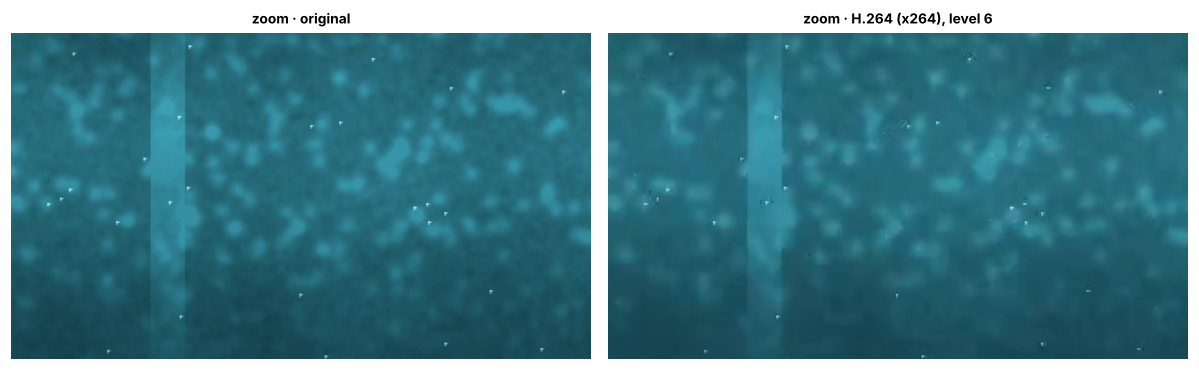

In [10]:
CODECS = {   # quality level 1..10 -> each encoder's own scale
    "H.264 (x264)": ("libx264", lambda lv: ["-c:v", "libx264", "-preset", "veryfast", "-crf", str(45 - 3 * lv)], f"CRF", "mp4", "yuv420p"),
    "H.265 (x265)": ("libx265", lambda lv: ["-c:v", "libx265", "-preset", "veryfast", "-crf", str(45 - 3 * lv), "-x265-params", "log-level=error"], "CRF", "mp4", "yuv420p"),
    "MJPEG":        ("mjpeg",   lambda lv: ["-c:v", "mjpeg", "-q:v", str(max(2, 31 - 3 * lv))], "q:v", "mkv", "yuvj420p"),
    "AV1 (SVT-AV1)": ("libsvtav1", lambda lv: ["-c:v", "libsvtav1", "-preset", "10", "-crf", str(60 - 4 * lv)], "CRF", "mkv", "yuv420p"),
}


def codec_view(codec, level):
    enc, mk, qname, ext, pix = CODECS[codec]
    if not HAS.get(enc):
        print(f"{enc} is not in this FFmpeg build."); return
    args = mk(level); res = encode_cached(args, "codec", ext=ext, pix_fmt=pix)
    cards([("setting", f"{qname} {args[args.index('-crf') + 1] if '-crf' in args else args[args.index('-q:v') + 1]}", codec),
           ("bitrate", rate(res["bitrate"]), f"{raw_bits / (res['size'] * 8):,.0f} : 1 vs raw"),
           ("SSIM", f"{res['ssim']:.3f}", "0.95+ looks good", res["ssim"] >= 0.95),
           ("encode speed", f"{N_FRAMES / res['wall']:.0f} fps", "real time needs 30", N_FRAMES / res["wall"] >= FPS)])
    y0, x0 = int(0.48 * H), int(0.40 * W)
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
    for ax, (img, cap) in zip(axs, ((frame_png(SRC, 2.0, "codec_ref"), "original"), (frame_png(res["file"], 2.0, "codec_enc"), f"{codec}, level {level}"))):
        ax.imshow(img[y0:y0 + H // 4, x0:x0 + W // 4]); ax.set_title(f"zoom · {cap}", fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()


panel("codec", "Pick a codec", "Quality 1 = smallest file, 10 = best picture",
      {"codec": ("toggle", list(CODECS), "H.264 (x264)", "codec"), "level": ("int", (1, 10, 1), 6, "quality level")}, codec_view)

**Look for**
- At the same SSIM, MJPEG needs several times the bits of H.264. On the slide: raw 332 → MJPEG 8.2 → H.264 1.5 Mb/s.
- Encode speed matters as much as size on the ROV: H.265 and AV1 buy their savings with CPU.
- Halving width and height divides the pixels by 4 and throws away detail. Switching codec saves more and keeps the detail.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 18 · WORDS THAT GET MIXED UP · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">What does one packet cost on the wire?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Bitrate, capacity, throughput, headroom: RTP adds about 5 %.</div>
</div>

**Try it.** Change the payload size and watch the overhead. Small packets waste a lot; big ones risk fragmentation (slide 78). MPEG-TS packs 7 × 188-byte packets per datagram, so its payload size is fixed.

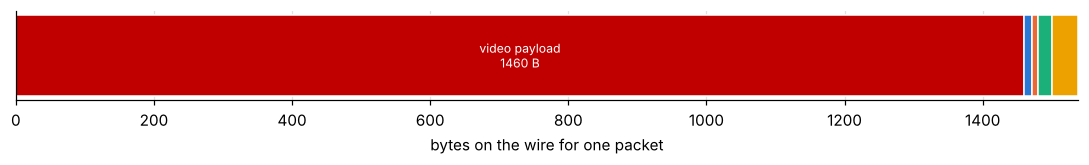

In [11]:
def packet_view(proto, payload, video_mbps):
    if proto == "RTP over UDP":
        pay, hdr = payload, {"RTP": 12, "UDP": 8, "IPv4": 20, "Ethernet + gap": 38}
    else:
        pay, hdr = 7 * 184, {"TS headers (7 × 4)": 28, "UDP": 8, "IPv4": 20, "Ethernet + gap": 38}
    wire = pay + sum(hdr.values()); over = wire / pay - 1; pps = video_mbps * 1e6 / 8 / pay
    cards([("overhead", f"{over:.1%}", "on top of the video", over < 0.08),
           ("on the wire", rate(video_mbps * (1 + over)), f"for {rate(video_mbps)} of video"),
           ("packets per second", f"{pps:,.0f}", f"{wire} bytes each"),
           ("plan with", rate(video_mbps * (1 + over) / 0.7), "link size for 70 % use")])
    fig, ax = plt.subplots(figsize=(10, 1.6)); left = 0
    for k, (name, b) in enumerate([("video payload", pay), *hdr.items()]):
        ax.barh(0, b, left=left, color=[MIA_RED, *PALETTE][k], edgecolor="white", height=0.6)
        if b > 40: ax.text(left + b / 2, 0, f"{name}\n{b} B", ha="center", va="center", fontsize=8, color="white")
        left += b
    ax.set_xlim(0, left); ax.set_yticks([]); ax.set_xlabel("bytes on the wire for one packet"); plt.tight_layout(); plt.show()


panel("packet", "Packet overhead", "Every packet carries headers; small packets pay the most",
      {"proto": ("toggle", ["RTP over UDP", "MPEG-TS over UDP"], "RTP over UDP", "transport"),
       "payload": ("int", (200, 1460, 20), 1460, "RTP payload (bytes)"),
       "video_mbps": ("options", [0.5, 1, 2, 4, 8, 20, 50], 4, "video (Mb/s)")}, packet_view, live=True)

**Look for**
- 1,460-byte RTP payloads: about 5 %. MPEG-TS: about 7 %. Below 500 bytes the headers start to matter.
- *Bitrate* is what the encoder makes, *capacity* what the link negotiates, *throughput* what `iperf3` measures, and *headroom* the 30 % you leave free on purpose.

<div style="border-radius:18px; padding:22px 26px; margin:40px 0 6px; background:#1d1d1f; color:#ffffff">
<div style="font-size:11px; letter-spacing:.3em; color:#ff8a8a">PART 03 · SLIDES 19–40</div>
<div style="font-size:26px; font-weight:800; margin-top:6px">How video encoding works</div>
<div style="font-size:14px; color:#c8c8c8; margin-top:4px">Open the encoder one step at a time, then turn its knobs.</div>
</div>

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 21–22 · DIGITAL VIDEO FUNDAMENTALS · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Colour at half resolution: can you see it?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">4:2:0 saves half the data before any compression.</div>
</div>

**Try it.** Switch between 4:4:4, 4:2:2 and 4:2:0 and compare the zoomed crops. Then tick **draw a thin red overlay before encoding**: that's the one case where colour subsampling hurts.

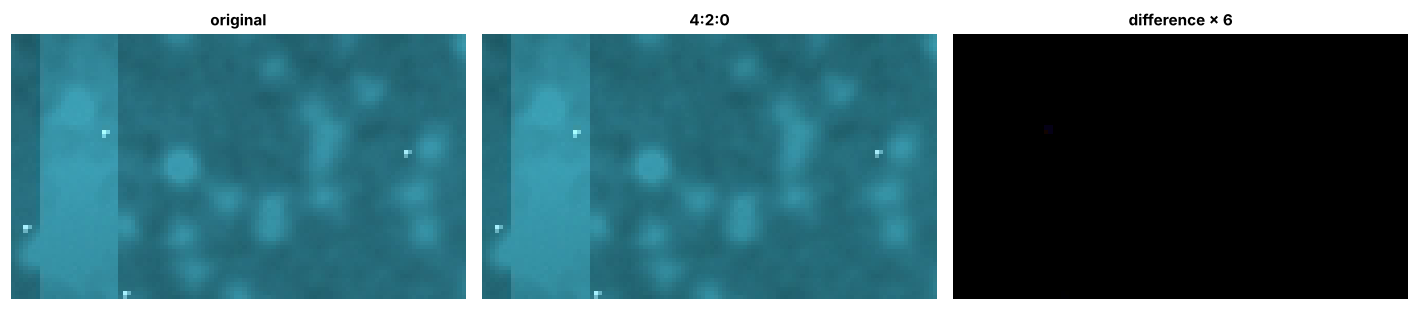

In [12]:
FRAME_RGB = frame_png(SRC, 2.0, "chroma")[..., :3].astype(float)


def to_ycc(rgb):                                    # BT.601, full range, values 0..1
    y = rgb @ np.array([0.299, 0.587, 0.114])
    return y, (rgb[..., 2] - y) * 0.564 + 0.5, (rgb[..., 0] - y) * 0.713 + 0.5


def from_ycc(y, cb, cr):
    r = y + 1.403 * (cr - 0.5); b = y + 1.773 * (cb - 0.5); g = (y - 0.299 * r - 0.114 * b) / 0.587
    return np.clip(np.stack([r, g, b], -1), 0, 1)


def subsample(c, mode):
    """Average colour over 2×1 (4:2:2) or 2×2 (4:2:0) blocks, then stretch it back."""
    if mode == "4:4:4":
        return c
    fy, fx = (1, 2) if mode == "4:2:2" else (2, 2)
    h, w = c.shape[0] // fy * fy, c.shape[1] // fx * fx
    small = c[:h, :w].reshape(h // fy, fy, w // fx, fx).mean(axis=(1, 3))
    return np.repeat(np.repeat(small, fy, 0), fx, 1)


def chroma_view(mode, overlay, zoom):
    img = FRAME_RGB.copy()
    y0, x0 = int(0.50 * H), int(0.42 * W)
    if overlay:                                     # 1-pixel red lines, like a HUD drawn into the video
        img[y0 + 40, x0:x0 + 200] = [1, 0, 0]; img[y0:y0 + 120, x0 + 100] = [1, 0, 0]
        for k in range(100): img[y0 + 10 + k, x0 + 20 + k] = [1, 0, 0]
    y, cb, cr = to_ycc(img)
    out = from_ycc(y, subsample(cb, mode), subsample(cr, mode))
    bpp = {"4:4:4": 24, "4:2:2": 16, "4:2:0": 12}[mode]
    err = np.mean((out - img) ** 2); psnr = 99 if err == 0 else 10 * np.log10(1 / err)
    cards([("bits per pixel", f"{bpp}", f"{bpp / 24:.0%} of RGB"), ("PSNR vs original", f"{psnr:.1f} dB", "higher = closer"),
           ("data saved", f"{1 - bpp / 24:.0%}", "before any compression", True)])
    cy, cx, hh, ww = y0 + 40, x0 + 100, 130 // zoom, 220 // zoom      # centred where the red lines cross
    crop = lambda a: a[cy - hh // 2:cy + hh // 2, cx - ww // 2:cx + ww // 2]
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, a, t in zip(axs, (img, out, np.clip(np.abs(out - img) * 6, 0, 1)), ("original", mode, "difference × 6")):
        ax.imshow(crop(a), interpolation="nearest"); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()


panel("chroma", "Chroma subsampling", "Brightness keeps full resolution; colour is shared between pixels",
      {"mode": ("toggle", ["4:4:4", "4:2:2", "4:2:0"], "4:2:0", "scheme"),
       "zoom": ("options", [1, 2, 4], 2, "zoom"),
       "overlay": ("check", None, False, "draw a thin red overlay before encoding")}, chroma_view, live=True)

**Look for**
- On the seabed you'll struggle to see any difference: our eyes see detail in brightness, not colour, and the water has already taken the red.
- The red lines go pink and smeared at 4:2:0. That's why overlays (depth, heading, boxes) are drawn on the pilot laptop *after* decoding.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 23–25 · PREDICTION · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Find the block in the last frame</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Send a motion vector and a small correction instead of the block.</div>
</div>

**Try it.** The cell cuts the frame into blocks and, for each block, searches the previous frame for the best match. With search range 0 there's no motion search at all (just "same as last frame"). Raise the range and watch the residual shrink. Then add sensor noise: the search can't remove it.

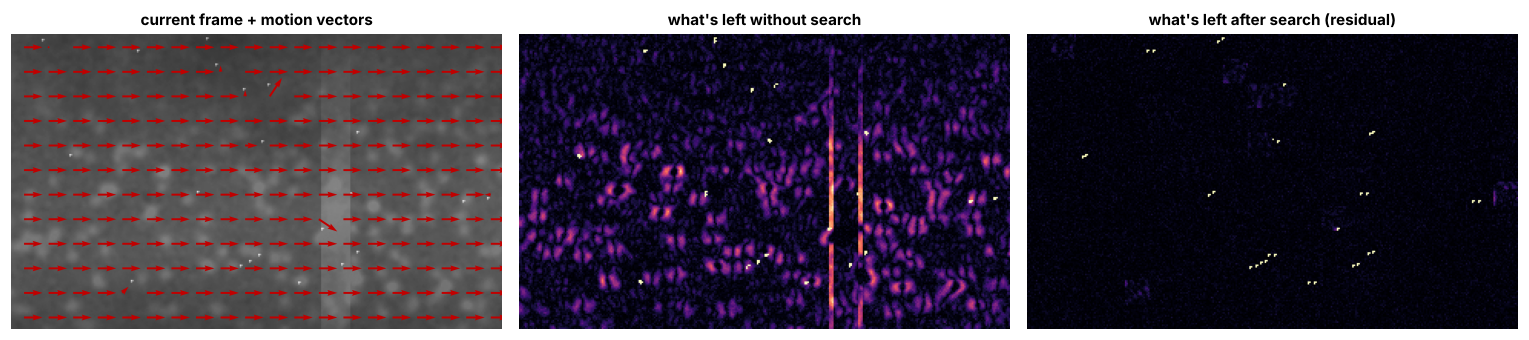

In [13]:
PREV = gray(frame_png(SRC, 2.0, "mv0")); CUR = gray(frame_png(SRC, 2.0 + 1 / FPS, "mv1"))
MV_Y, MV_X, MV_H, MV_W = int(0.40 * H), int(0.30 * W), 192, 320          # the region we search in


def motion_search(prev, cur, block, reach):
    """Exhaustive block matching: for every block, the shift (dy, dx) within ±reach with the smallest error."""
    c = cur[MV_Y:MV_Y + MV_H, MV_X:MV_X + MV_W]
    nby, nbx = MV_H // block, MV_W // block
    best = np.full((nby, nbx), np.inf); vy = np.zeros((nby, nbx), int); vx = np.zeros((nby, nbx), int)
    for dy in range(-reach, reach + 1):
        for dx in range(-reach, reach + 1):
            p = prev[MV_Y + dy:MV_Y + dy + MV_H, MV_X + dx:MV_X + dx + MV_W]
            err = np.abs(c - p).reshape(nby, block, nbx, block).sum(axis=(1, 3))
            better = err < best
            best[better], vy[better], vx[better] = err[better], dy, dx
    pred = np.zeros_like(c)
    for by in range(nby):
        for bx in range(nbx):
            y, x = MV_Y + by * block + vy[by, bx], MV_X + bx * block + vx[by, bx]
            pred[by * block:(by + 1) * block, bx * block:(bx + 1) * block] = prev[y:y + block, x:x + block]
    return c, c - pred, vx, vy


def mv_view(block, reach, noise):
    rng = np.random.default_rng(0)
    prev = PREV + rng.normal(0, noise, PREV.shape); cur = CUR + rng.normal(0, noise, CUR.shape)
    c, resid, vx, vy = motion_search(prev, cur, block, reach)
    plain = np.abs(c - prev[MV_Y:MV_Y + MV_H, MV_X:MV_X + MV_W]).mean(); left = np.abs(resid).mean()
    common = pd.Series(list(zip(vx.ravel(), vy.ravel()))).value_counts().index[0]
    cards([("error without search", f"{plain:.1f}", "per pixel, 0..255"),
           ("error after search", f"{left:.1f}", f"{1 - left / plain:.0%} smaller", left < plain),
           ("most common vector", f"({common[0]}, {common[1]})", "the camera pans 3 px per frame"),
           ("blocks", f"{vx.size}", f"{block}×{block} pixels")])
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.3))
    axs[0].imshow(c, cmap="gray", vmin=0, vmax=255)
    yy, xx = np.mgrid[0:vx.shape[0], 0:vx.shape[1]] * block + block / 2
    axs[0].quiver(xx, yy, vx, -vy, color=MIA_RED, angles="xy", scale_units="xy", scale=0.25, width=0.004)
    axs[0].set_title("current frame + motion vectors", fontsize=10)
    axs[1].imshow(np.abs(c - prev[MV_Y:MV_Y + MV_H, MV_X:MV_X + MV_W]), cmap="magma", vmin=0, vmax=40); axs[1].set_title("what's left without search", fontsize=10)
    axs[2].imshow(np.abs(resid), cmap="magma", vmin=0, vmax=40); axs[2].set_title("what's left after search (residual)", fontsize=10)
    for ax in axs: ax.axis("off")
    plt.tight_layout(); plt.show()


panel("mv", "Motion search", "Bright = what still has to be sent",
      {"block": ("options", [8, 16, 32], 16, "block size"),
       "reach": ("options", [0, 2, 4, 8, 12], 4, "search range (± px)"),
       "noise": ("options", [0, 2, 4, 8, 16], 0, "extra sensor noise (σ)")}, mv_view, live=True)

**Look for**
- The vectors line up at about (3, 0): the clip pans 3 pixels per frame, and the search finds it.
- Larger search ranges find better matches but cost time. x264 presets mostly change *how hard* this search is (slide 25 and 38).
- Noise survives any search. Random detail has no match in the last frame, so it stays in the residual and costs bits (slide 23).

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 26 · TRANSFORM + QUANTIZE · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Where the bits are thrown away</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">64 pixels become a few numbers; quantization is the only lossy step.</div>
</div>

**Try it.** Start with the 8×8 block from slide 26. Raise the **step size**: more numbers turn to zero and the rebuilt block drifts from the original. Then try blocks from our clip.

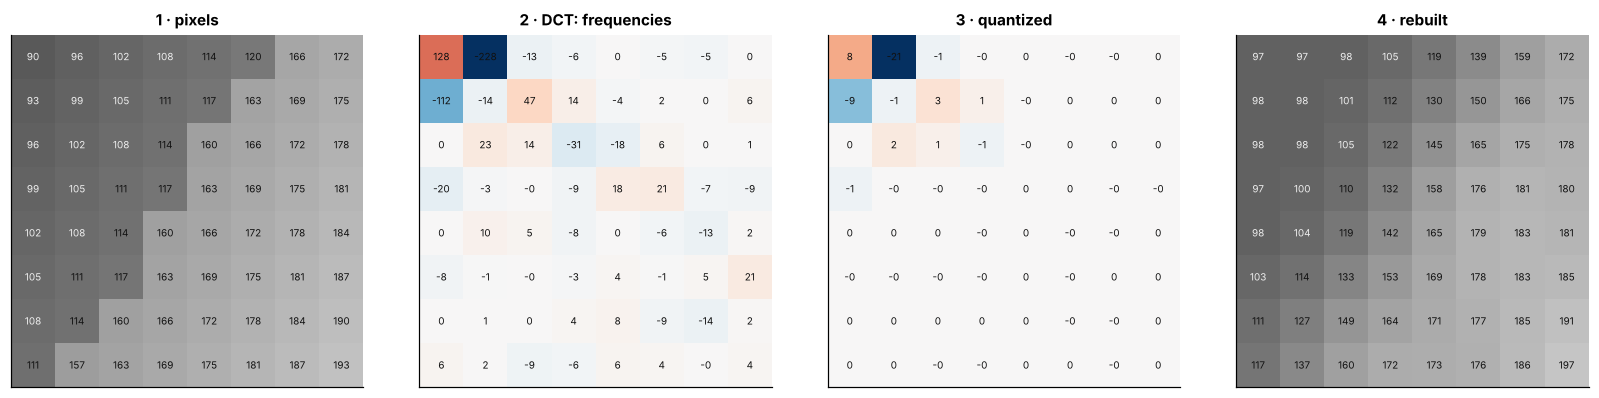

In [14]:
from scipy.fft import dctn, idctn

JPEG_Q = np.array([[16, 11, 10, 16, 24, 40, 51, 61], [12, 12, 14, 19, 26, 58, 60, 55], [14, 13, 16, 24, 40, 57, 69, 56],
                   [14, 17, 22, 29, 51, 87, 80, 62], [18, 22, 37, 56, 68, 109, 103, 77], [24, 35, 55, 64, 81, 104, 113, 92],
                   [49, 64, 78, 87, 103, 121, 120, 101], [72, 92, 95, 98, 112, 100, 103, 99]], float)
SLIDE_BLOCK = np.array([[90, 96, 102, 108, 114, 120, 166, 172], [93, 99, 105, 111, 117, 163, 169, 175],
                        [96, 102, 108, 114, 160, 166, 172, 178], [99, 105, 111, 117, 163, 169, 175, 181],
                        [102, 108, 114, 160, 166, 172, 178, 184], [105, 111, 117, 163, 169, 175, 181, 187],
                        [108, 114, 160, 166, 172, 178, 184, 190], [111, 157, 163, 169, 175, 181, 187, 193]], float)
CLIP_Y = gray(FRAME_RGB)
SPOTS = {"slide 26 (pipe edge)": None, "open water": (40, 300), "pipe edge in our clip": (int(0.58 * H) - 60, 640),
         "seabed texture": (650, 200)}


def dct_view(spot, step):
    blk = SLIDE_BLOCK if SPOTS[spot] is None else CLIP_Y[SPOTS[spot][0]:SPOTS[spot][0] + 8, SPOTS[spot][1]:SPOTS[spot][1] + 8]
    coef = dctn(blk - 128, norm="ortho")
    q = np.round(coef / (JPEG_Q * step))
    back = idctn(q * JPEG_Q * step, norm="ortho") + 128
    err = np.mean((back - blk) ** 2); psnr = 99 if err < 1e-9 else 10 * np.log10(255 ** 2 / err)
    kept = int((q != 0).sum())
    cards([("numbers kept", f"{kept} of 64", f"{64 - kept} zeros cost almost nothing"),
           ("block PSNR", f"{psnr:.1f} dB", "rebuilt vs original", psnr > 35),
           ("step size", f"× {step:g}", "of the JPEG table (+6 QP ≈ ×2)")])
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
    for ax, a, t, cm in zip(axs, (blk, coef, q, back), ("1 · pixels", "2 · DCT: frequencies", "3 · quantized", "4 · rebuilt"),
                            ("gray", "RdBu_r", "RdBu_r", "gray")):
        lim = (0, 255) if cm == "gray" else (-np.abs(a).max() - 1e-9, np.abs(a).max() + 1e-9)
        ax.imshow(a, cmap=cm, vmin=lim[0], vmax=lim[1]); ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        for (i, j), v in np.ndenumerate(a):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="#111" if cm != "gray" or v > 110 else "#eee")
    plt.tight_layout(); plt.show()


panel("dct", "DCT and quantization", "Raise the step: more zeros, fewer bits, more error",
      {"spot": ("toggle", list(SPOTS), "slide 26 (pipe edge)", "block"),
       "step": ("options", [0.25, 0.5, 1, 2, 4, 8], 1, "step size")}, dct_view, live=True)

**Look for**
- At step 1 the slide's block keeps 11 numbers and 53 zeros, the same as slide 26.
- Open water keeps almost nothing even at a small step: smooth areas are nearly free. Texture and edges keep many numbers.
- Each doubling of the step is about +6 QP in H.264, and roughly halves the bitrate.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 28 · FRAME TYPES · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">I, P and B frames, and the GOP</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">I-frames are big and standalone; B-frames wait for the future.</div>
</div>

In [15]:
GOPS = [10, 30, 60, 150]
rows, ftypes = [], {}
def gop_encode(name, extra):
    out = WORK / f"e5_{name}.mp4"
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
         "-crf", "23", *extra, "-pix_fmt", "yuv420p", "-an", str(out)])
    return out
for g in GOPS:
    out = gop_encode(f"g{g}", ["-g", str(g), "-keyint_min", str(g), "-sc_threshold", "0"])
    ft = frame_types(out); ftypes[f"GOP {g}"] = ft; p = probe(out)
    rows.append({"variant": f"GOP {g} (fixed)", "I-frames": int((ft.type == "I").sum()), "bitrate_Mb/s": p["bitrate_mbps"],
                 "avg_I_kB": ft[ft.type == "I"]["size"].mean() / 1e3, "avg_P_kB": ft[ft.type == "P"]["size"].mean() / 1e3,
                 "avg_B_kB": ft[ft.type == "B"]["size"].mean() / 1e3, "worst_join_wait_s": g / FPS})
out = gop_encode("g300_scenecut", ["-g", "300"])           # long GOP, scene-cut detection ON (default)
ft = frame_types(out); ftypes["GOP 300 + scenecut"] = ft; p = probe(out)
rows.append({"variant": "GOP 300 + scene-cut detection", "I-frames": int((ft.type == "I").sum()), "bitrate_Mb/s": p["bitrate_mbps"],
             "avg_I_kB": ft[ft.type == "I"]["size"].mean() / 1e3, "avg_P_kB": ft[ft.type == "P"]["size"].mean() / 1e3,
             "avg_B_kB": ft[ft.type == "B"]["size"].mean() / 1e3, "worst_join_wait_s": 300 / FPS})
e5 = pd.DataFrame(rows)
display(e5.style.format({"bitrate_Mb/s": "{:.2f}", "avg_I_kB": "{:.1f}", "avg_P_kB": "{:.1f}", "avg_B_kB": "{:.1f}",
                         "worst_join_wait_s": "{:.1f}"}).hide(axis="index"))
i_frames = ftypes["GOP 300 + scenecut"].index[ftypes["GOP 300 + scenecut"].type == "I"].tolist()
print("GOP 300 + scenecut — I-frames at frame numbers:", i_frames, "(the scene cut is at frame 118–120)")

variant,I-frames,bitrate_Mb/s,avg_I_kB,avg_P_kB,avg_B_kB,worst_join_wait_s
GOP 10 (fixed),18,2.95,62.2,12.2,4.0,0.3
GOP 30 (fixed),6,2.20,60.3,16.1,4.1,1.0
GOP 60 (fixed),3,1.98,56.8,17.3,4.0,2.0
GOP 150 (fixed),2,1.92,50.8,17.4,4.1,5.0
GOP 300 + scene-cut detection,2,1.90,50.6,17.0,4.0,10.0


GOP 300 + scenecut — I-frames at frame numbers: [0, 118] (the scene cut is at frame 118–120)


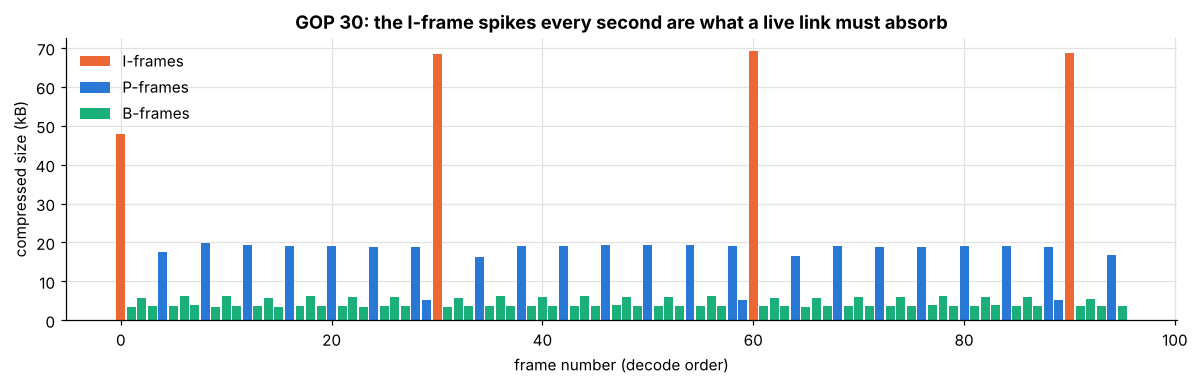

In [16]:
ft = ftypes["GOP 30"].iloc[:96]
colors = {"I": PALETTE[1], "P": PALETTE[0], "B": PALETTE[2]}
fig, ax = plt.subplots(figsize=(11, 3.6))
for t in ("I", "P", "B"):
    sel = ft[ft.type == t]
    ax.bar(sel.index, sel["size"] / 1e3, color=colors[t], width=0.85, label=f"{t}-frames")
ax.set_xlabel("frame number (decode order)"); ax.set_ylabel("compressed size (kB)")
ax.set_title("GOP 30: the I-frame spikes every second are what a live link must absorb"); ax.legend()
plt.tight_layout(); plt.show()

**Try it.** Change the keyframe interval and the number of B-frames. The bars are each frame's size, coloured by type.

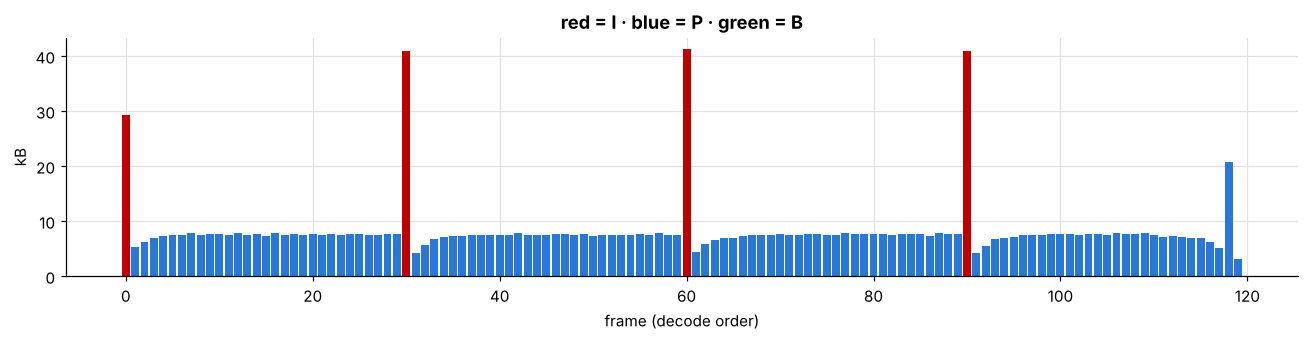

In [17]:
TYPE_COLOUR = {"I": MIA_RED, "P": PALETTE[0], "B": PALETTE[2]}


def types_view(gop_s, bframes, scenecut):
    g = max(1, round(gop_s * FPS))
    args = ["-c:v", "libx264", "-preset", "veryfast", "-crf", "23", "-g", str(g), "-keyint_min", str(g), "-bf", str(bframes),
            *([] if scenecut else ["-sc_threshold", "0"])]
    res = encode_cached(args, "types"); ft = frame_types(res["file"])
    kb = lambda t: ft[ft.type == t]["size"].mean() / 1e3 if (ft.type == t).any() else float("nan")
    cards([("I-frames", f"{int((ft.type == 'I').sum())}", f"one every {g / FPS:.2f} s"),
           ("average I", f"{kb('I'):.0f} kB", f"{kb('I') / kb('P'):.1f}× a P-frame"),
           ("average P", f"{kb('P'):.1f} kB", "predicted from the past"),
           ("average B", "none" if bframes == 0 else f"{kb('B'):.1f} kB", "waits for a future frame" if bframes else "no waiting"),
           ("bitrate", rate(res["bitrate"]), f"SSIM {res['ssim']:.3f}")])
    show = ft.iloc[:120]
    plt.figure(figsize=(12, 3.2))
    plt.bar(show.index, show["size"] / 1e3, color=[TYPE_COLOUR.get(t, GREY) for t in show.type], width=0.85)
    plt.xlabel("frame (decode order)"); plt.ylabel("kB"); plt.title("red = I · blue = P · green = B"); plt.tight_layout(); plt.show()


panel("types", "Frame types", "Keyframe interval and B-frames",
      {"gop_s": ("options", [0.25, 0.5, 1.0, 2.0, 4.0], 1.0, "keyframe every (s)"),
       "bframes": ("int", (0, 3, 1), 0, "B-frames"),
       "scenecut": ("check", None, False, "extra I-frame on a scene cut")}, types_view)

**Look for**
- An I-frame is several times a P-frame (about 4× on the slide). Those spikes are what the tether must absorb every GOP.
- B-frames make the file smaller, but each one makes the encoder wait for a future frame. Live streams use 0.
- With scene-cut detection on, x264 adds an I-frame at the camera cut (frame ~120).

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 29 · EXPERIMENTS 3 AND 6 · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Quality target or bitrate cap?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">CRF for recording, a capped bitrate for the live tether.</div>
</div>

In [18]:
CRFS = [18, 23, 28, 33, 38, 43]
TARGETS_MBPS = [0.25, 0.5, 1, 2, 4, 8]
rows = []
for crf in CRFS:
    out = WORK / f"e3_crf{crf}.mp4"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
             "-crf", str(crf), "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"mode": "CRF", "setting": f"crf {crf}", "bitrate_Mb/s": p["bitrate_mbps"], "size_MB": p["size_bytes"]/1e6,
                 "encode_s": r["wall_s"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
for tgt in TARGETS_MBPS:
    out = WORK / f"e3_vbv{tgt}.mp4"; kb = int(tgt * 1000)
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
             "-b:v", f"{kb}k", "-maxrate", f"{kb}k", "-bufsize", f"{kb // 2}k",   # 0.5 s of buffer
             "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"mode": "Target bitrate (VBV)", "setting": f"{tgt} Mb/s", "bitrate_Mb/s": p["bitrate_mbps"],
                 "size_MB": p["size_bytes"]/1e6, "encode_s": r["wall_s"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
e3 = pd.DataFrame(rows)
display(e3.drop(columns="file").style.format({"bitrate_Mb/s": "{:.2f}", "size_MB": "{:.2f}", "encode_s": "{:.1f}",
                                              "PSNR_dB": "{:.1f}", "SSIM": "{:.4f}"}).hide(axis="index"))

mode,setting,bitrate_Mb/s,size_MB,encode_s,PSNR_dB,SSIM
CRF,crf 18,4.14,3.11,1.7,48.4,0.9877
CRF,crf 23,1.90,1.42,1.6,46.6,0.9836
CRF,crf 28,1.05,0.78,1.4,44.1,0.9748
CRF,crf 33,0.53,0.40,1.4,41.1,0.9605
CRF,crf 38,0.19,0.14,1.2,37.6,0.9395
CRF,crf 43,0.06,0.05,1.0,35.0,0.9182
Target bitrate (VBV),0.25 Mb/s,0.17,0.13,2.6,38.1,0.9407
Target bitrate (VBV),0.5 Mb/s,0.40,0.30,3.1,40.0,0.9547
Target bitrate (VBV),1 Mb/s,0.78,0.59,3.8,42.9,0.9686
Target bitrate (VBV),2 Mb/s,1.50,1.12,4.7,46.2,0.9812


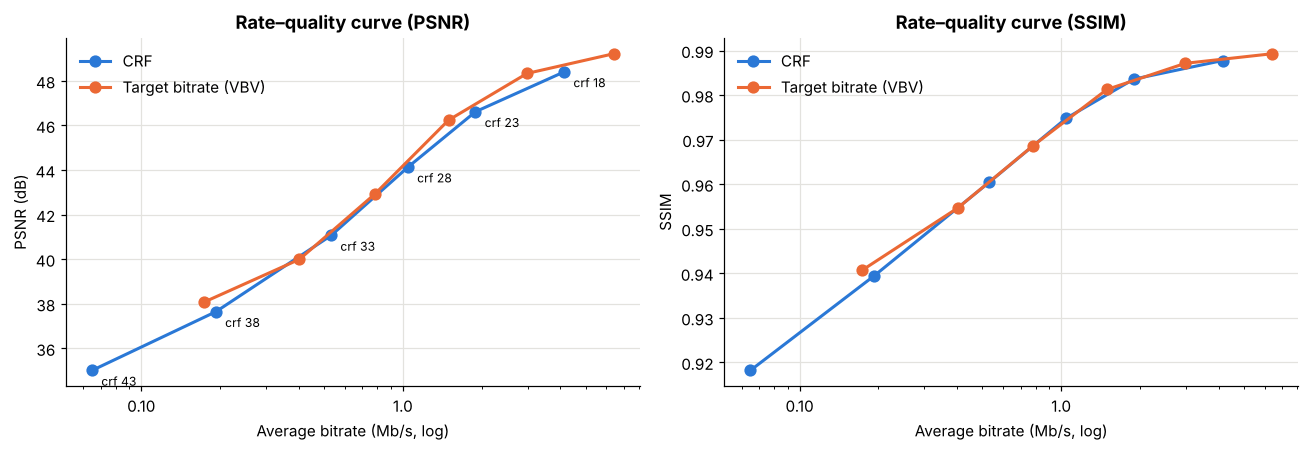

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for k, (mode, g) in enumerate(e3.groupby("mode", sort=False)):
    axs[0].plot(g["bitrate_Mb/s"], g["PSNR_dB"], "o-", label=mode, color=PALETTE[k])
    axs[1].plot(g["bitrate_Mb/s"], g["SSIM"], "o-", label=mode, color=PALETTE[k])
for _, r in e3[e3["mode"] == "CRF"].iterrows():
    axs[0].annotate(r["setting"], (r["bitrate_Mb/s"], r["PSNR_dB"]), textcoords="offset points", xytext=(6, -10), fontsize=8)
for ax, yl in zip(axs, ("PSNR (dB)", "SSIM")):
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(FuncFormatter(mbps_fmt))
    ax.set_xlabel("Average bitrate (Mb/s, log)"); ax.set_ylabel(yl); ax.legend()
axs[0].set_title("Rate–quality curve (PSNR)"); axs[1].set_title("Rate–quality curve (SSIM)")
plt.tight_layout(); plt.show()

Now the part that matters on a tether: what the bitrate does **over time**. Both encodes below have the same average.

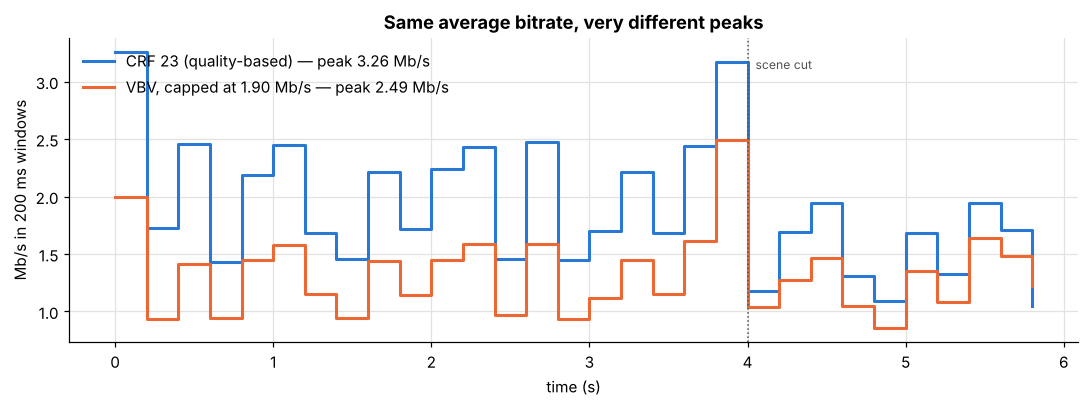

In [20]:
crf23 = e3[(e3["mode"] == "CRF") & (e3["setting"] == "crf 23")].iloc[0]
avg_kb = int(crf23["bitrate_Mb/s"] * 1000)
vbv_match = WORK / "e3_vbv_match.mp4"
run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
     "-b:v", f"{avg_kb}k", "-maxrate", f"{avg_kb}k", "-bufsize", f"{avg_kb // 3}k", "-pix_fmt", "yuv420p", "-an", str(vbv_match)])

def windowed_mbps(path, win=0.2):
    pk = packets(path); bins = np.floor(pk["pts"] / win)
    s = pk.groupby(bins)["size"].sum() * 8 / win / 1e6
    return s.index.values * win, s.values, pk

fig, ax = plt.subplots(figsize=(10, 3.8))
for k, (label, path) in enumerate((("CRF 23 (quality-based)", crf23["file"]), (f"VBV, capped at {avg_kb/1000:.2f} Mb/s", vbv_match))):
    t, mb, pk = windowed_mbps(path)
    ax.step(t, mb, where="post", label=f"{label} — peak {mb.max():.2f} Mb/s", color=PALETTE[k])
ax.axvline(4.0, color="#52514e", ls=":", lw=1); ax.text(4.05, ax.get_ylim()[1]*0.92, "scene cut", fontsize=8, color="#52514e")
ax.set_xlabel("time (s)"); ax.set_ylabel("Mb/s in 200 ms windows"); ax.set_title("Same average bitrate, very different peaks")
ax.legend(); plt.tight_layout(); plt.show()

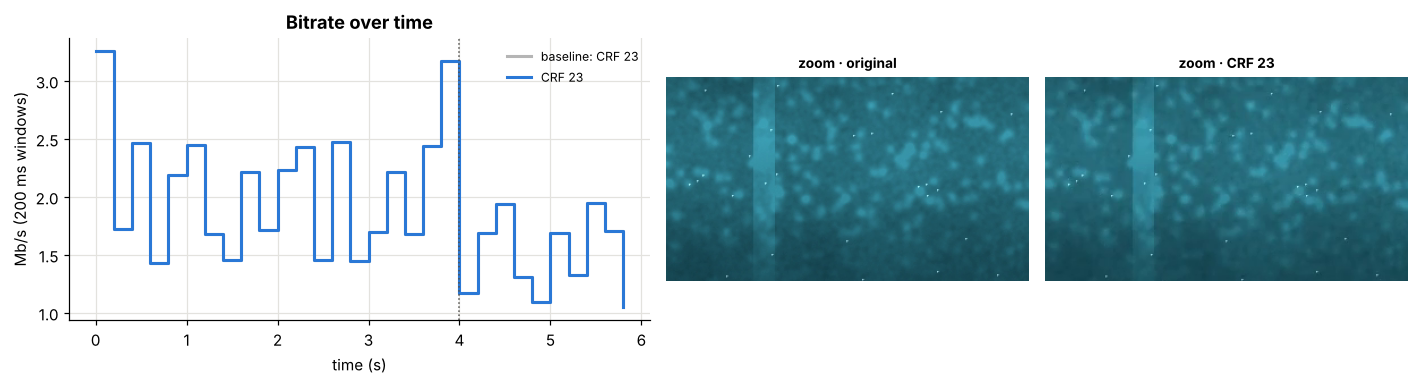

In [21]:
def tune_rate(mode, crf, target, buffer_s):
    if mode == "CRF (quality)":
        args = ["-c:v", "libx264", "-preset", "medium", "-crf", str(crf)]; label = f"CRF {crf}"
    else:
        kb = int(target * 1000)
        args = ["-c:v", "libx264", "-preset", "medium", "-b:v", f"{kb}k", "-maxrate", f"{kb}k", "-bufsize", f"{int(kb * buffer_s)}k"]
        label = f"cap {target:g} Mb/s, buffer {buffer_s:g} s"
    res = encode_cached(args, "e3")
    t, mb, _ = windowed_mbps(res["file"]); t0, mb0, _ = windowed_mbps(crf23["file"])
    cards([("bitrate", f"{res['bitrate']:.2f} Mb/s", *delta(res["bitrate"], crf23["bitrate_Mb/s"], lambda d: f"{d:+.2f}", False)),
           ("peak (200 ms)", f"{mb.max():.2f} Mb/s", *delta(mb.max(), mb0.max(), lambda d: f"{d:+.2f}", False)),
           ("compression", f"{raw_bits / (res['size'] * 8):,.0f} : 1", "vs raw 4:2:0"),
           ("PSNR", f"{res['psnr']:.1f} dB", *delta(res["psnr"], crf23["PSNR_dB"], lambda d: f"{d:+.1f} dB", True)),
           ("SSIM", f"{res['ssim']:.4f}", *delta(res["ssim"], crf23["SSIM"], lambda d: f"{d:+.4f}", True))])
    fig = plt.figure(figsize=(13, 3.6)); gs = fig.add_gridspec(1, 3, width_ratios=[1.6, 1, 1])
    ax = fig.add_subplot(gs[0])
    ax.step(t0, mb0, where="post", color="#b5b5b5", label="baseline: CRF 23")
    ax.step(t, mb, where="post", color=PALETTE[0], label=label)
    ax.axvline(4.0, color="#52514e", ls=":", lw=1); ax.set_xlabel("time (s)"); ax.set_ylabel("Mb/s (200 ms windows)")
    ax.set_title("Bitrate over time"); ax.legend(fontsize=8)
    y0, x0 = int(0.48 * H), int(0.40 * W)   # zoom on the pipeline at t = 2 s, where detail is hardest to keep
    for k, (img, cap) in enumerate(((frame_png(SRC, 2.0, "e3_ref"), "original"), (frame_png(res["file"], 2.0, "e3_enc"), label))):
        a = fig.add_subplot(gs[k + 1]); a.imshow(img[y0:y0 + H // 4, x0:x0 + W // 4]); a.set_title(f"zoom · {cap}", fontsize=9); a.axis("off")
    plt.tight_layout(); plt.show()

panel("e3", "Rate control", "Quality target or bitrate cap: watch the peaks and the detail",
             {"mode": ("toggle", ["CRF (quality)", "Target bitrate (VBV)"], "CRF (quality)", ""),
              "crf": ("int", (12, 45, 1), 23, "CRF"),
              "target": ("options", [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0], 1.0, "bitrate cap (Mb/s)"),
              "buffer_s": ("options", [0.1, 0.25, 0.5, 1.0, 2.0], 0.5, "VBV buffer (s)")}, tune_rate)

**Look for**
- CRF's peaks: the slide's run averaged 1.5 Mb/s but peaked at 2.6 Mb/s in 200 ms windows. A sediment cloud does the same thing exactly when the pilot needs the picture.
- The capped encode holds its ceiling and lets quality dip on hard frames instead. Shrink the VBV buffer: smoother bitrate, lower latency, worse hard frames.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 30 · WHY STREAMERS OBSESS OVER BITS · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">What is 1 % of Netflix's bitrate worth?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">A Fermi estimate: change any factor you don't believe.</div>
</div>

In [22]:
def netflix_view(hours_bn, gb_per_hour, usd_per_gb, saving_pct):
    eb = hours_bn * 1e9 * gb_per_hour / 1e9            # exabytes a year
    cost = hours_bn * 1e9 * gb_per_hour * usd_per_gb
    cards([("delivered", f"{eb:,.0f} EB / year", f"{hours_bn} billion hours × {gb_per_hour} GB"),
           ("delivery cost", f"${cost / 1e9:,.1f} B / year", f"at ${usd_per_gb}/GB (assumed)"),
           (f"{saving_pct} % fewer bits", f"${cost * saving_pct / 100 / 1e6:,.0f} M / year", "saved", True),
           ("our ROV", "1 viewer", "encoded once, watched once, live")])


panel("netflix", "Netflix, roughly", "191 B hours (2025) × GB per hour × cost per GB",
      {"hours_bn": ("int", (50, 300, 1), 191, "billion hours / year"),
       "gb_per_hour": ("options", [0.5, 1, 2, 3, 5, 7], 2, "GB per hour"),
       "usd_per_gb": ("options", [0.002, 0.005, 0.01, 0.02, 0.03, 0.05], 0.005, "$ per GB"),
       "saving_pct": ("int", (1, 20, 1), 1, "bitrate saved (%)")}, netflix_view, live=True)

**Look for**
- With the slide's ranges, 1 % is worth roughly \$19–115 M a year. That's why Netflix spends huge CPU per encode: it's encoded once and watched millions of times.
- Our stream is encoded once and watched once, live. We do the opposite: spend bits to save latency and CPU.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 32 · CHOOSING A CODEC · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">The fair comparison: whole rate–quality curves</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Which codec is best depends on where you sit on the curve.</div>
</div>

This cell encodes the clip at five quality levels per codec. It's the slowest cell in the notebook (a few minutes on a laptop); the results are cached. We use `-tune ssim` (metric-neutral tuning) so the encoders aren't optimising for how things look to people while we score them with SSIM.

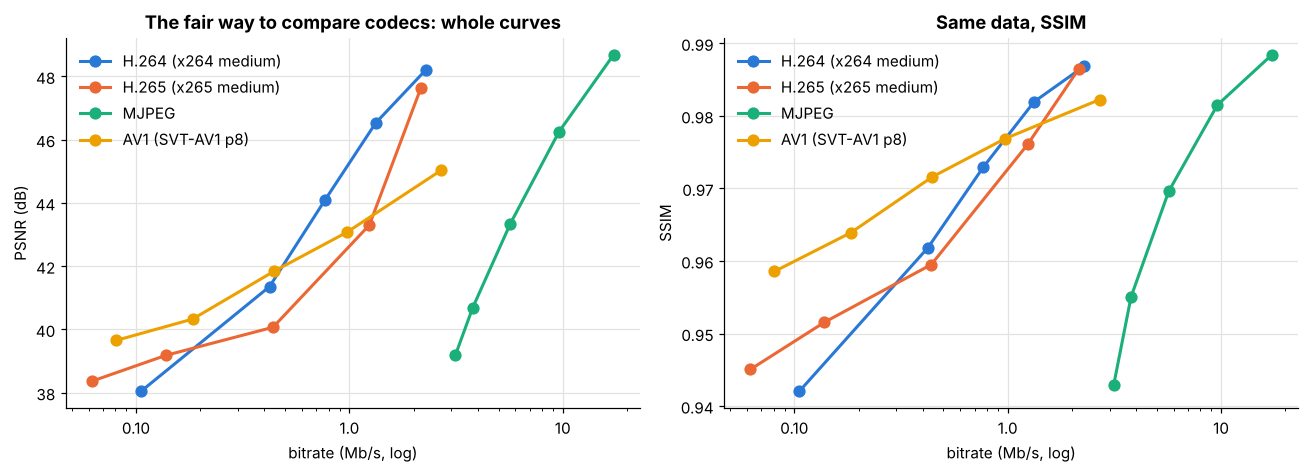

In [23]:
CURVES = {
    # Metric-neutral tuning: -tune ssim (x264/x265) and tune=1 (PSNR) for SVT-AV1 — see the note below.
    "H.264 (x264 medium)":  ("libx264",   [18, 23, 28, 33, 38], lambda q: ["-c:v", "libx264", "-preset", "medium", "-tune", "ssim", "-crf", str(q), "-pix_fmt", "yuv420p"], "mp4"),
    "H.265 (x265 medium)":  ("libx265",   [18, 23, 28, 33, 38], lambda q: ["-c:v", "libx265", "-preset", "medium", "-tune", "ssim", "-crf", str(q), "-pix_fmt", "yuv420p", "-x265-params", "log-level=error"], "mp4"),
    "MJPEG":                ("mjpeg",     [2, 4, 8, 16, 31],    lambda q: ["-c:v", "mjpeg", "-q:v", str(q), "-pix_fmt", "yuvj420p"], "mkv"),
    "AV1 (SVT-AV1 p8)":     ("libsvtav1", [24, 32, 40, 48, 56], lambda q: ["-c:v", "libsvtav1", "-preset", "8", "-crf", str(q), "-svtav1-params", "tune=1", "-pix_fmt", "yuv420p"], "mkv"),
}
rows = []
for codec, (enc, qs, mk, ext) in CURVES.items():
    if not HAS.get(enc): print("skip", codec); continue
    for q in qs:
        out = WORK / f"e6_{enc}_{q}.{ext}"
        if not out.exists():
            run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *mk(q), "-an", str(out)])
        p = probe(out); psnr, ssim = quality(out, SRC)
        rows.append({"codec": codec, "q": q, "bitrate_Mb/s": p["bitrate_mbps"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
e6 = pd.DataFrame(rows)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for k, (codec, g) in enumerate(e6.groupby("codec", sort=False)):
    for ax, m in zip(axs, ("PSNR_dB", "SSIM")):
        ax.plot(g["bitrate_Mb/s"], g[m], "o-", color=PALETTE[k], label=codec)
for ax, m in zip(axs, ("PSNR (dB)", "SSIM")):
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(FuncFormatter(mbps_fmt)); ax.set_xlabel("bitrate (Mb/s, log)"); ax.set_ylabel(m); ax.legend()
axs[0].set_title("The fair way to compare codecs: whole curves"); axs[1].set_title("Same data, SSIM")
plt.tight_layout(); plt.show()

In [24]:
def bitrate_at(g, metric, target):
    g = g.sort_values(metric)
    if not (g[metric].min() <= target <= g[metric].max()): return np.nan
    return float(np.exp(np.interp(target, g[metric], np.log(g["bitrate_Mb/s"]))))

# Two operating points: a constrained-tether point (SSIM 0.96) and the quality x264 reaches at its default CRF 23.
lo = e6.groupby("codec")["SSIM"].min().max(); hi = e6.groupby("codec")["SSIM"].max().min()
ssim_crf23 = float(e6[(e6.codec == "H.264 (x264 medium)") & (e6.q == 23)].SSIM.iloc[0])   # x264 CRF 23, tune ssim
SSIM_TARGET = round(float(np.clip(ssim_crf23, lo + 0.001, hi - 0.001)), 3)
SSIM_LOW = round(float(np.clip(0.96, lo + 0.001, hi - 0.001)), 3)
rows = []
for codec, g in e6.groupby("codec", sort=False):
    r_lo, r_hi = bitrate_at(g, "SSIM", SSIM_LOW), bitrate_at(g, "SSIM", SSIM_TARGET)
    rows.append({"codec": codec, f"Mb/s @ SSIM {SSIM_LOW}": r_lo, f"Mb/s @ SSIM {SSIM_TARGET}": r_hi,
                 "bits_per_pixel (high)": r_hi * 1e6 / (W * H * FPS)})
equal_q = pd.DataFrame(rows)
for col_ in (f"Mb/s @ SSIM {SSIM_LOW}", f"Mb/s @ SSIM {SSIM_TARGET}"):
    ref = equal_q.loc[equal_q.codec.str.startswith("H.264"), col_].iloc[0]
    equal_q["vs H.264 " + col_.split("@ ")[1]] = equal_q[col_] / ref
display(equal_q.style.format({c: ("{:.2f}×" if c.startswith("vs") else "{:.4f}" if "bits" in c else "{:.2f}") for c in equal_q.columns if c != "codec"}).hide(axis="index"))
CODEC_BPP = dict(zip(equal_q.codec.str.split(" ").str[0], equal_q["bits_per_pixel (high)"]))   # e.g. {"H.264": 0.045, ...}
print("Calibrated bits-per-pixel (used on slide 50):", {k: round(v, 4) for k, v in CODEC_BPP.items()})

codec,Mb/s @ SSIM 0.96,Mb/s @ SSIM 0.981,bits_per_pixel (high),vs H.264 SSIM 0.96,vs H.264 SSIM 0.981
H.264 (x264 medium),0.37,1.25,0.0454,1.00×,1.00×
H.265 (x265 medium),0.45,1.61,0.0583,1.22×,1.28×
MJPEG,4.35,9.40,0.3400,11.69×,7.49×
AV1 (SVT-AV1 p8),0.10,2.13,0.0770,0.27×,1.70×


Calibrated bits-per-pixel (used on slide 50): {'H.264': 0.0454, 'H.265': 0.0583, 'MJPEG': 0.34, 'AV1': 0.077}


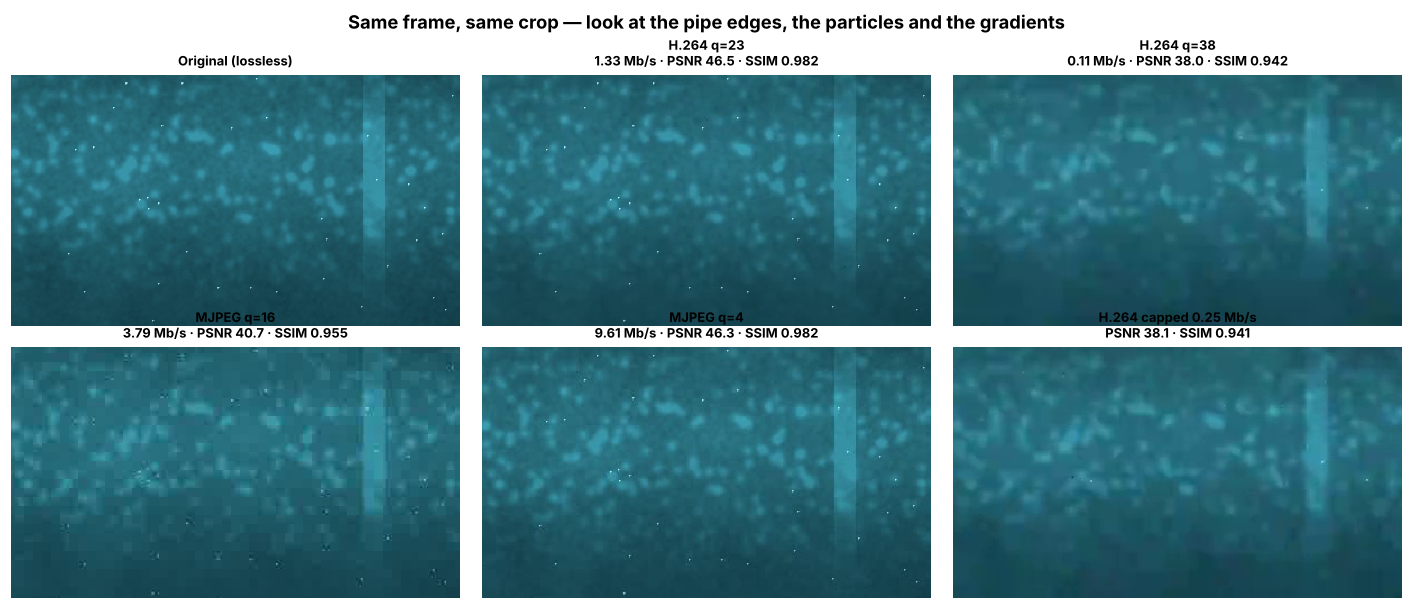

In [25]:
# Visual comparison: zoom into the pipeline area of one frame
T_SHOW, CROP = 2.0, "crop=400:225:620:330"
picks = [("Original (lossless)", SRC, None)]
def pick(codec, q):
    r = e6[(e6.codec == codec) & (e6.q == q)].iloc[0]; return (f"{codec.split(' ')[0]} q={q}\n{r['bitrate_Mb/s']:.2f} Mb/s · PSNR {r.PSNR_dB:.1f} · SSIM {r.SSIM:.3f}", r.file, r)
picks += [pick("H.264 (x264 medium)", 23), pick("H.264 (x264 medium)", 38), pick("MJPEG", 16), pick("MJPEG", 4)]
low = e3[(e3["mode"] != "CRF")].iloc[0]
picks.append((f"H.264 capped {low.setting}\nPSNR {low.PSNR_dB:.1f} · SSIM {low.SSIM:.3f}", low.file, None))
fig, axs = plt.subplots(2, 3, figsize=(13, 5.6))
for ax, (title, path, _) in zip(axs.flat, picks):
    png = WORK / f"e6_crop_{Path(str(path)).stem}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(T_SHOW), "-i", str(path), "-frames:v", "1", "-vf", CROP, str(png)])
    ax.imshow(plt.imread(png), interpolation="nearest"); ax.set_title(title, fontsize=8.5); ax.axis("off")
plt.suptitle("Same frame, same crop — look at the pipe edges, the particles and the gradients", fontweight="bold")
plt.tight_layout(); plt.show()

**Try it.** Pick a quality target. The bars show the bitrate each codec needs to reach it, read off the curves above.

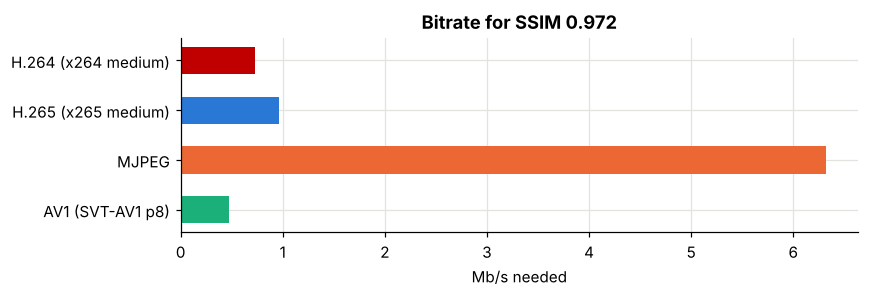

In [26]:
SSIM_OPTIONS = sorted({round(x, 3) for x in np.linspace(e6.groupby("codec")["SSIM"].min().max() + 0.002,
                                                         e6.groupby("codec")["SSIM"].max().min() - 0.002, 8)})


def equal_view(target):
    rows = [(c, bitrate_at(g, "SSIM", target)) for c, g in e6.groupby("codec", sort=False)]
    ref = dict(rows).get("H.264 (x264 medium)", np.nan)
    cards([(c.split(" ")[0], rate(b) if b == b else "out of range", f"{b / ref:.2f}× H.264" if b == b and ref == ref else "")
           for c, b in rows])
    plt.figure(figsize=(8, 2.8))
    plt.barh([c for c, _ in rows], [b for _, b in rows], color=[MIA_RED, *PALETTE][:len(rows)], height=0.55)
    plt.gca().invert_yaxis(); plt.xlabel("Mb/s needed"); plt.title(f"Bitrate for SSIM {target}"); plt.tight_layout(); plt.show()


panel("equal", "Equal quality", "Same SSIM, different codecs",
      {"target": ("options", SSIM_OPTIONS, SSIM_OPTIONS[len(SSIM_OPTIONS) // 2], "SSIM target")}, equal_view, live=True)

**Look for**
- The curves cross. At low quality AV1 needs far fewer bits than H.264; at high quality x264 holds up well on this clip.
- MJPEG needs several times more than everything else at any quality.
- On the ROV the deciding question is often not size but who can encode it in real time: the Pi 5 has no H.264 hardware encoder, the Jetson Nano does (slide 43).

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 33 · CODEC ≠ CONTAINER · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Pull the power during a recording</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Plain MP4 writes its index at the end; a power cut leaves nothing playable.</div>
</div>

**Try it.** The cell records the clip in real time into four containers and kills FFmpeg with `SIGKILL` after the time you choose, like a power cut. Then it checks what can still be played. (Ctrl-C would *not* be a fair test: it lets FFmpeg close the file cleanly.)

In [27]:
import signal

CONTAINERS = {"MP4": ("mp4", []),
              "Fragmented MP4": ("mp4", ["-movflags", "+frag_keyframe+empty_moov+default_base_moof"]),
              "Matroska (MKV)": ("mkv", []),
              "MPEG-TS": ("ts", [])}


def power_cut_view(cut_after):
    rows = []
    for name, (ext, flags) in CONTAINERS.items():
        out = WORK / f"cut_{name.split()[0].lower()}.{ext}"
        out.unlink(missing_ok=True)
        p = subprocess.Popen([FFMPEG, "-y", "-loglevel", "error", "-re", *SRC_IN, "-c:v", "libx264", "-preset", "ultrafast",
                              "-g", "30", "-pix_fmt", "yuv420p", *flags, str(out)])
        time.sleep(cut_after); p.send_signal(signal.SIGKILL); p.wait()
        r = run([FFPROBE, "-v", "error", "-count_frames", "-select_streams", "v:0", "-show_entries", "stream=nb_read_frames",
                 "-of", "csv=p=0", str(out)], check=False)
        frames = int(r["stdout"].strip()) if r["rc"] == 0 and r["stdout"].strip().isdigit() else 0
        rows.append({"container": name, "file size": f"{out.stat().st_size / 1e3:.0f} kB" if out.exists() else "none",
                     "plays?": "yes" if frames else "NO", "seconds you get back": round(frames / FPS, 1)})
    cards([(r["container"], r["plays?"], f"{r['seconds you get back']} s of {cut_after} s", r["plays?"] == "yes") for r in rows])
    display(pd.DataFrame(rows).style.hide(axis="index"))


panel("cut", "Power cut", "Real time recording, killed without warning",
      {"cut_after": ("options", [1.0, 2.0, 3.0, 4.0], 2.0, "cut the power after (s)")}, power_cut_view)

container,file size,plays?,seconds you get back
MP4,786 kB,NO,0.000000
Fragmented MP4,786 kB,yes,1.900000
Matroska (MKV),786 kB,yes,1.900000
MPEG-TS,786 kB,NO,0.000000


**Look for**
- The plain MP4 has data in it but doesn't play: its index (the `moov` atom) was never written. "moov atom not found" is the error you'd see.
- Fragmented MP4, MKV and MPEG-TS play up to about the last second. Record in one of those during the dive, then remux to MP4 if you need it: `ffmpeg -i dive.mkv -c copy dive.mp4` (seconds, no quality loss). Experiment E15 does this on the ROV.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 34–35 · MJPEG ON THE ROV · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">The resolution trap</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Shrinking MJPEG is free if the camera does it, and expensive if we do.</div>
</div>

We pretend `work/camera_720p.mkv` is what a USB camera sends in its 720p MJPEG mode. **Try it:** pick the size the pilot needs, then compare three ways to get it:

1. **Ask the camera** for that size and just copy it (`-c:v copy`).
2. **Resize on the ROV**: decode the 720p JPEGs, scale, encode JPEG again (what an OpenCV resize or the Python `mjpeg-streamer` does).
3. **Resize once, but encode H.264** instead of a smaller MJPEG.

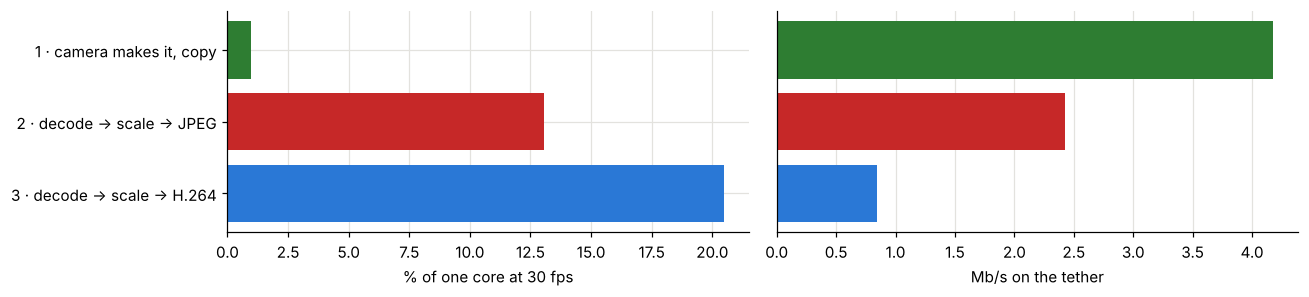

In [28]:
CAMERA = WORK / "camera_720p.mkv"
if not CAMERA.exists():
    run([FFMPEG, "-y", "-loglevel", "error", *SRC_IN, "-c:v", "mjpeg", "-q:v", "3", "-pix_fmt", "yuvj420p", str(CAMERA)])
TRAP_SIZES = {"1280×720": (1280, 720), "640×360": (640, 360), "320×180": (320, 180)}


def core_pct(r):
    """Share of one CPU core needed to keep up at 30 fps."""
    return r["cpu_s"] / N_FRAMES * FPS * 100


def trap_view(size, mjpeg_q):
    w, h = TRAP_SIZES[size]
    native = WORK / f"camera_{w}x{h}.mkv"        # what the camera would send if we asked it for this size
    if not native.exists():
        run([FFMPEG, "-y", "-loglevel", "error", *SRC_IN, "-vf", f"scale={w}:{h}", "-c:v", "mjpeg", "-q:v", "3",
             "-pix_fmt", "yuvj420p", str(native)])
    a = run([FFMPEG, "-y", "-loglevel", "error", "-i", str(native), "-c:v", "copy", str(WORK / "trap_copy.mkv")])
    b_out, c_out = WORK / f"trap_mjpeg_{w}_{mjpeg_q}.mkv", WORK / f"trap_h264_{w}.mp4"
    b = run([FFMPEG, "-y", "-loglevel", "error", "-i", str(CAMERA), "-vf", f"scale={w}:{h}", "-c:v", "mjpeg",
             "-q:v", str(mjpeg_q), "-pix_fmt", "yuvj420p", str(b_out)])
    c = run([FFMPEG, "-y", "-loglevel", "error", "-i", str(CAMERA), "-vf", f"scale={w}:{h}", "-c:v", "libx264",
             "-preset", "veryfast", "-tune", "zerolatency", "-crf", "23", "-pix_fmt", "yuv420p", str(c_out)])
    paths = {"1 · camera makes it, copy": (a, native), "2 · decode → scale → JPEG": (b, b_out), "3 · decode → scale → H.264": (c, c_out)}
    rows = {k: (core_pct(r), probe(p)["bitrate_mbps"]) for k, (r, p) in paths.items()}
    cards([(k.split(" · ")[1], f"{cpu:.1f} % of a core", rate(mb), cpu < 5) for k, (cpu, mb) in rows.items()])
    fig, axs = plt.subplots(1, 2, figsize=(12, 2.8))
    names = list(rows)
    axs[0].barh(names, [v[0] for v in rows.values()], color=[GOOD, BAD, PALETTE[0]]); axs[0].set_xlabel("% of one core at 30 fps")
    axs[1].barh(names, [v[1] for v in rows.values()], color=[GOOD, BAD, PALETTE[0]]); axs[1].set_xlabel("Mb/s on the tether")
    for ax in axs: ax.invert_yaxis()
    axs[1].set_yticks([]); plt.tight_layout(); plt.show()


panel("trap", "The resolution trap", "Where you shrink the picture decides what it costs",
      {"size": ("toggle", list(TRAP_SIZES), "640×360", "size the pilot needs"),
       "mjpeg_q": ("int", (2, 15, 1), 5, "JPEG quality for path 2 (q:v)")}, trap_view)

**Look for**
- Path 1 costs about 1 % of a core: nothing is decoded or encoded. Check which sizes your camera makes itself: `v4l2-ctl -d /dev/video0 --list-formats-ext`.
- Path 2 costs many times more, per camera, and the Python library repeats the encode for every viewer.
- If the camera can't make the size you need, path 3 is the better transcode: one H.264 encode, several times fewer bits than a smaller MJPEG.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 38 · EXPERIMENT 4 · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Encoder presets: CPU against bits</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Slower presets search harder; after veryfast the savings get small.</div>
</div>

preset,encode_fps,cores_used,cpu_ms_per_frame,bitrate_Mb/s,PSNR_dB,SSIM
ultrafast,274,1.6,5.8,2.77,45.00,0.9749
superfast,152,1.7,11.4,2.31,46.65,0.9835
veryfast,123,1.8,14.3,1.32,45.15,0.9789
faster,61,1.8,29.2,1.44,46.30,0.9818
fast,106,1.7,16.4,1.90,46.62,0.9836
medium,111,1.8,16.0,1.90,46.62,0.9836
slow,114,1.8,15.5,1.90,46.62,0.9836
slower,16,1.8,110.4,1.31,46.34,0.9815
veryslow,9,1.8,194.7,1.17,46.36,0.9820


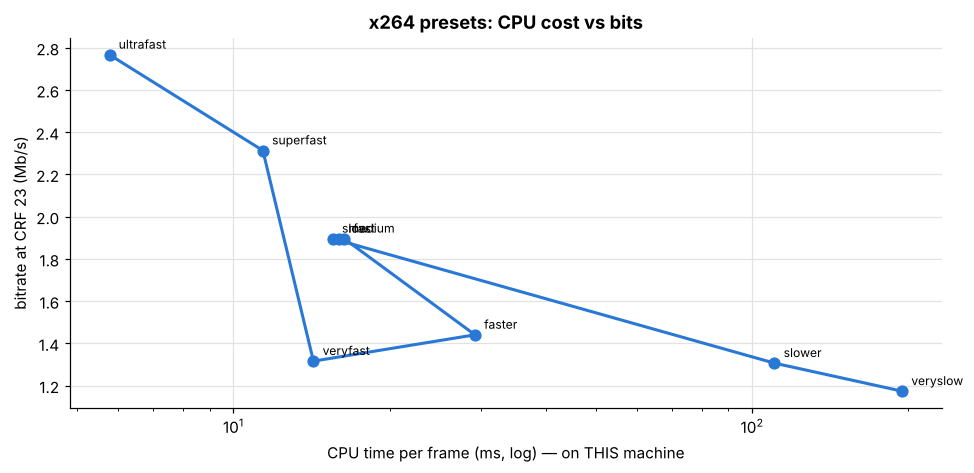

In [29]:
PRESETS = ["ultrafast", "superfast", "veryfast", "faster", "fast", "medium", "slow", "slower", "veryslow"]
rows = []
for pr in PRESETS:
    out = WORK / f"e4_{pr}.mp4"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", pr,
             "-crf", "23", "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"preset": pr, "encode_fps": N_FRAMES / r["wall_s"], "cores_used": r["cpu_s"] / r["wall_s"],
                 "cpu_ms_per_frame": 1000 * r["cpu_s"] / N_FRAMES, "bitrate_Mb/s": p["bitrate_mbps"], "PSNR_dB": psnr, "SSIM": ssim})
e4 = pd.DataFrame(rows)
display(e4.style.format({"encode_fps": "{:.0f}", "cores_used": "{:.1f}", "cpu_ms_per_frame": "{:.1f}",
                         "bitrate_Mb/s": "{:.2f}", "PSNR_dB": "{:.2f}", "SSIM": "{:.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(e4["cpu_ms_per_frame"], e4["bitrate_Mb/s"], "o-", color=PALETTE[0])
for _, r in e4.iterrows():
    ax.annotate(r["preset"], (r["cpu_ms_per_frame"], r["bitrate_Mb/s"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("CPU time per frame (ms, log) — on THIS machine")
ax.set_ylabel("bitrate at CRF 23 (Mb/s)"); ax.set_title("x264 presets: CPU cost vs bits")
plt.tight_layout(); plt.show()

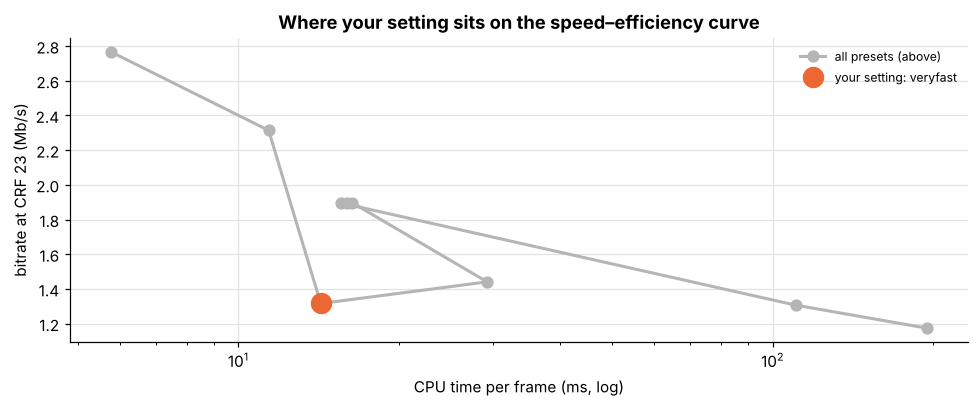

In [30]:
def tune_preset(preset, zerolatency):
    args = ["-c:v", "libx264", "-preset", preset, "-crf", "23", *(["-tune", "zerolatency"] if zerolatency else [])]
    res = encode_cached(args, "e4")
    base = e4[e4["preset"] == "medium"].iloc[0]
    fps_ = N_FRAMES / res["wall"]; cores = res["cpu"] / res["wall"]; ms = 1000 * res["cpu"] / N_FRAMES
    cards([("encode speed", f"{fps_:.0f} fps", f"{fps_ / FPS:.1f}× real time", fps_ >= FPS),
           ("CPU per frame", f"{ms:.1f} ms", *delta(ms, base["cpu_ms_per_frame"], lambda d: f"{d:+.1f} ms", False)),
           ("cores used", f"{cores:.1f}", f"of {CPU_CORES} on this machine"),
           ("bitrate", f"{res['bitrate']:.2f} Mb/s", *delta(res["bitrate"], base["bitrate_Mb/s"], lambda d: f"{d:+.2f}", False)),
           ("PSNR", f"{res['psnr']:.2f} dB", *delta(res["psnr"], base["PSNR_dB"], lambda d: f"{d:+.2f} dB", True))])
    need = ms * FPS * 8 / 1000
    display(HTML(f'<p style="text-align:center">Eight 720p30 cameras with these settings would need <b>{need:.1f} cores</b> '
                 f'of <i>this</i> computer. Repeat on the SBC before you believe it.</p>'))
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(e4["cpu_ms_per_frame"], e4["bitrate_Mb/s"], "o-", color="#b5b5b5", label="all presets (above)")
    ax.plot([ms], [res["bitrate"]], "o", ms=13, color=PALETTE[1], label=f"your setting: {preset}{' + zerolatency' if zerolatency else ''}")
    ax.set_xscale("log"); ax.set_xlabel("CPU time per frame (ms, log)"); ax.set_ylabel("bitrate at CRF 23 (Mb/s)")
    ax.set_title("Where your setting sits on the speed–efficiency curve"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

panel("e4", "Encoder speed", "Same CRF, different preset: CPU cost versus bits",
             {"preset": ("options", PRESETS, "veryfast", "preset"),
              "zerolatency": ("check", None, False, "-tune zerolatency (no B-frames, no lookahead)")}, tune_preset)

**Look for**
- CPU time per frame is the number that transfers between machines: measure it on the SBC, multiply by fps and streams, compare with the free cores.
- `zerolatency` changes more than speed: it removes look-ahead and B-frames, which is up to a second of delay (slide 49).

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 39 · EXPERIMENT 5 · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Packet loss and the keyframe interval</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Damage lasts until the next I-frame; intra refresh heals without the spike.</div>
</div>

We delete a few kB from an MPEG-TS stream (as a lost burst of UDP packets would), decode it, and measure how long the picture stays broken. First at three loss positions for three settings, then in a panel where you choose.

variant,loss at 1.4s,loss at 2.5s,loss at 3.3s,mean damaged (s),worst (s)
GOP 30 (I-frame every 1 s),0.57,0.47,0.67,0.57,0.67
GOP 150 (I-frame every 5 s),3.57,1.40,1.67,2.21,3.57
Intra refresh over 30 frames,0.47,0.67,0.67,0.60,0.67


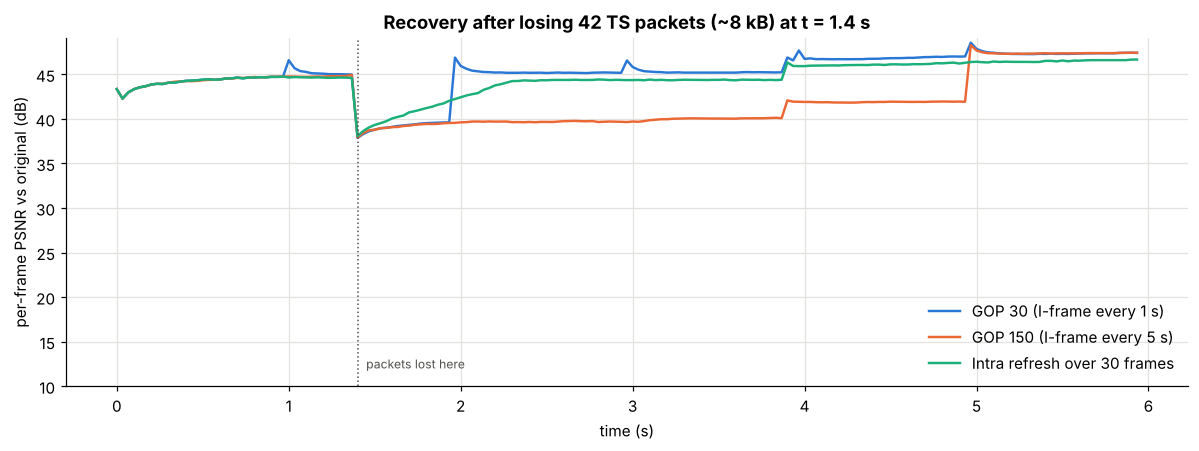

In [31]:
LOSS_T = 1.4                       # the loss we plot and look at
LOSS_TIMES = [1.4, 2.5, 3.3]       # repeat at three positions — one loss point is an anecdote, not a measurement
DROP_TS_PACKETS = 42               # 6 UDP datagrams × 7 TS packets
VARIANTS = {
    "GOP 30 (I-frame every 1 s)":   ["-g", "30", "-keyint_min", "30", "-sc_threshold", "0"],
    "GOP 150 (I-frame every 5 s)":  ["-g", "150", "-keyint_min", "150", "-sc_threshold", "0"],
    "Intra refresh over 30 frames": ["-g", "30", "-sc_threshold", "0", "-x264-params", "intra-refresh=1"],
}

def damage_seconds(clean, damaged):
    """Duration between the first and last frame that is > 3 dB worse than the undamaged encode."""
    n = min(len(clean), len(damaged)); bad = np.where(clean[:n] - damaged[:n] > 3)[0]
    return (bad.max() - bad.min() + 1) / FPS if len(bad) else 0.0

loss, rows = {}, []
for label, extra in VARIANTS.items():
    tag = re.sub(r"\W+", "_", label)[:20]
    ts = WORK / f"e5_{tag}.ts"
    # -threads 1: multi-threaded x264 with a capped bitrate is not bit-exact between runs; one thread makes this reproducible
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "veryfast",
         "-tune", "zerolatency", "-threads", "1", "-b:v", "2000k", "-maxrate", "2000k", "-bufsize", "700k", *extra,
         "-pix_fmt", "yuv420p", "-an", "-f", "mpegts", str(ts)])
    pk = packets(ts); start_pts = pk["pts"].min(); data = ts.read_bytes()
    _, _, pf_clean = quality(ts, SRC, per_frame=True)
    durations = []
    for k, t_loss in enumerate(LOSS_TIMES):
        pos = int(pk.loc[(pk["pts"] - start_pts - t_loss).abs().idxmin(), "pos"]); pos -= pos % 188   # TS packet boundary
        damaged = WORK / f"e5_{tag}_damaged{k}.ts"
        damaged.write_bytes(data[:pos] + data[pos + 188 * DROP_TS_PACKETS:])
        dec = WORK / (f"e5_{tag}_decoded.mkv" if k == 0 else f"e5_{tag}_decoded{k}.mkv")
        run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(damaged), "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(dec)])
        _, _, pf_dam = quality(dec, SRC, per_frame=True)
        durations.append(damage_seconds(pf_clean, pf_dam))
        if k == 0: loss[label] = {"clean": pf_clean, "damaged": pf_dam, "ts": ts}
    rows.append({"variant": label, **{f"loss at {t}s": d for t, d in zip(LOSS_TIMES, durations)},
                 "mean damaged (s)": np.mean(durations), "worst (s)": np.max(durations)})
e5_loss = pd.DataFrame(rows)
display(e5_loss.style.format({c: "{:.2f}" for c in e5_loss.columns if c != "variant"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4.2))
for k, (label, d) in enumerate(loss.items()):
    ax.plot(np.arange(len(d["damaged"])) / FPS, d["damaged"], label=label, color=PALETTE[k], lw=1.6)
ax.axvline(LOSS_T, color="#52514e", ls=":", lw=1); ax.text(LOSS_T + 0.05, 12, "packets lost here", fontsize=8, color="#52514e")
ax.set_ylim(10, None); ax.set_xlabel("time (s)"); ax.set_ylabel("per-frame PSNR vs original (dB)")
ax.set_title(f"Recovery after losing {DROP_TS_PACKETS} TS packets (~{DROP_TS_PACKETS*188/1000:.0f} kB) at t = {LOSS_T} s"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

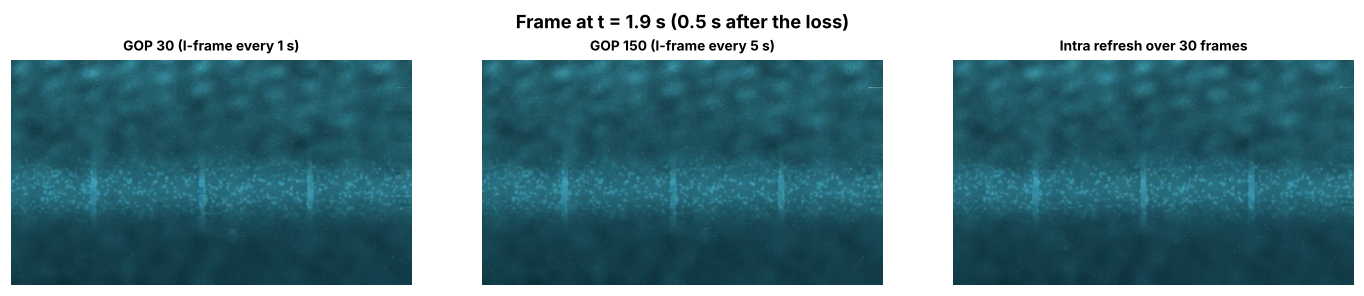

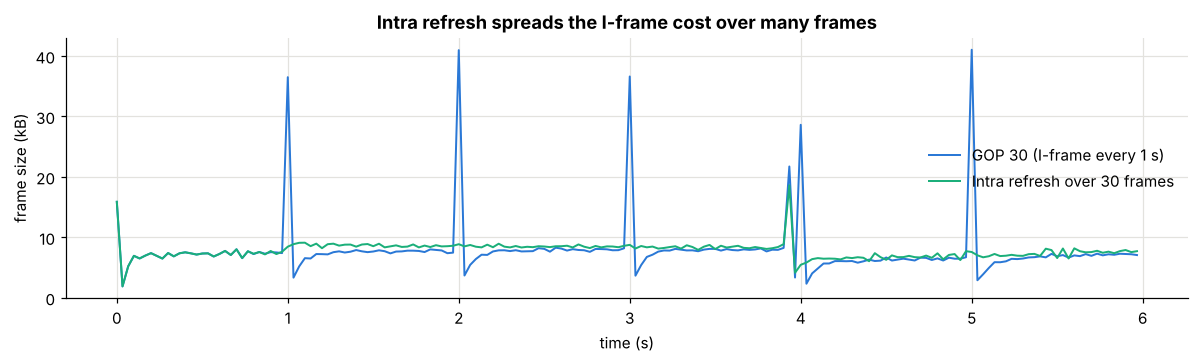

In [32]:
# What the pilot sees 0.5 s after the loss, and the bitrate smoothness of intra refresh
fig, axs = plt.subplots(1, 3, figsize=(13, 2.7))
for ax, (label, d) in zip(axs, loss.items()):
    tag = re.sub(r"\W+", "_", label)[:20]; png = WORK / f"e5_{tag}_after.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(LOSS_T + 0.5), "-i", str(WORK / f"e5_{tag}_decoded.mkv"), "-frames:v", "1", str(png)])
    ax.imshow(plt.imread(png)); ax.set_title(label, fontsize=9); ax.axis("off")
plt.suptitle(f"Frame at t = {LOSS_T + 0.5:.1f} s (0.5 s after the loss)", fontweight="bold"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.4))
for k, label in enumerate(["GOP 30 (I-frame every 1 s)", "Intra refresh over 30 frames"]):
    pk = packets(loss[label]["ts"]); ax.plot(np.arange(len(pk)) / FPS, pk["size"] / 1e3, label=label, color=PALETTE[[0, 2][k]], lw=1.3)
ax.set_xlabel("time (s)"); ax.set_ylabel("frame size (kB)"); ax.set_title("Intra refresh spreads the I-frame cost over many frames")
ax.legend(); plt.tight_layout(); plt.show()

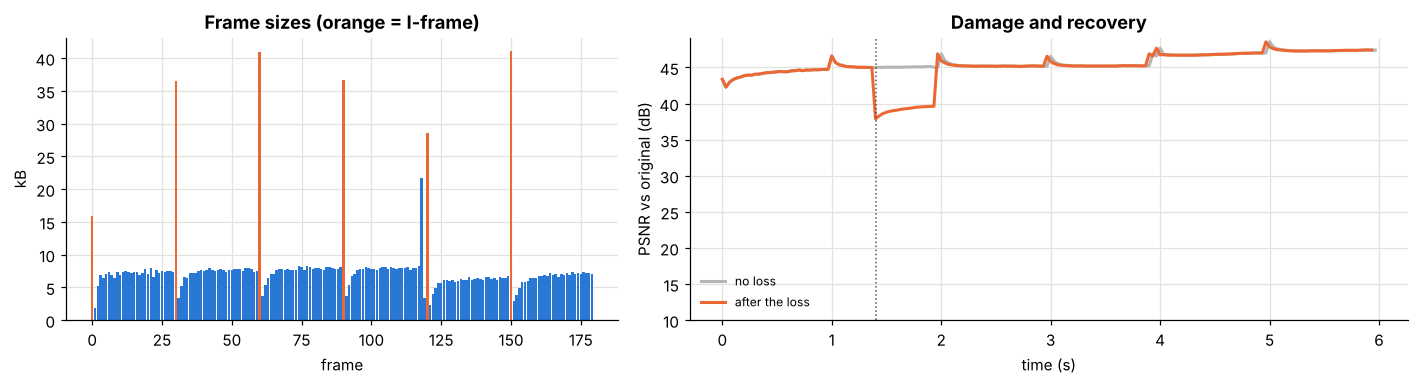

In [33]:
def tune_gop(gop_s, intra_refresh, loss_kb, loss_at):
    g = max(1, int(round(gop_s * FPS)))
    extra = (["-g", str(g), "-sc_threshold", "0", "-x264-params", "intra-refresh=1"] if intra_refresh
             else ["-g", str(g), "-keyint_min", str(g), "-sc_threshold", "0"])
    args = ["-c:v", "libx264", "-preset", "veryfast", "-tune", "zerolatency", "-threads", "1",
            "-b:v", "2000k", "-maxrate", "2000k", "-bufsize", "700k", *extra]
    key = hashlib.sha1(json.dumps(args).encode()).hexdigest()[:12]
    ts = WORK / f"tune_e5_{key}.ts"
    if not ts.exists():
        run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *args, "-pix_fmt", "yuv420p", "-an", "-f", "mpegts", str(ts)])
    pk = packets(ts); data = ts.read_bytes()
    _, _, clean = quality(ts, SRC, per_frame=True)
    pos = int(pk.loc[(pk["pts"] - pk["pts"].min() - loss_at).abs().idxmin(), "pos"]); pos -= pos % 188
    n_drop = max(1, int(loss_kb * 1000 / 188))
    dam = WORK / "tune_e5_damaged.ts"; dam.write_bytes(data[:pos] + data[pos + 188 * n_drop:])
    dec = WORK / "tune_e5_decoded.mkv"
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(dam), "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(dec)])
    _, _, broken = quality(dec, SRC, per_frame=True)
    mbps = len(data) * 8 / (N_FRAMES / FPS) / 1e6
    cards([("I-frames", f"{int(pk['key'].sum())}", "intra refresh: only the first" if intra_refresh else f"one every {g / FPS:.2f} s"),
           ("stream bitrate", f"{mbps:.2f} Mb/s", "incl. MPEG-TS overhead"),
           ("biggest frame", f"{pk['size'].max() / 1e3:.0f} kB", f"average {pk['size'].mean() / 1e3:.1f} kB"),
           ("broken picture", f"{damage_seconds(clean, broken):.2f} s", f"after losing {n_drop * 188 / 1000:.0f} kB",
            damage_seconds(clean, broken) <= 1.0),
           ("worst join wait", f"{g / FPS:.2f} s", "camera switch / new viewer")])
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
    axs[0].bar(np.arange(len(pk)), pk["size"] / 1e3, width=0.9, color=[PALETTE[1] if k else PALETTE[0] for k in pk["key"]])
    axs[0].set_xlabel("frame"); axs[0].set_ylabel("kB"); axs[0].set_title("Frame sizes (orange = I-frame)")
    tt = np.arange(len(broken)) / FPS
    axs[1].plot(np.arange(len(clean)) / FPS, clean, color="#b5b5b5", label="no loss")
    axs[1].plot(tt, broken, color=PALETTE[1], label="after the loss")
    axs[1].axvline(loss_at, color="#52514e", ls=":", lw=1); axs[1].set_ylim(10, None)
    axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("PSNR vs original (dB)"); axs[1].set_title("Damage and recovery"); axs[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

panel("e5", "Keyframes and packet loss", "Shorter GOP or intra refresh: how fast does the picture heal?",
             {"gop_s": ("options", [0.25, 0.5, 1.0, 2.0, 3.0, 5.0], 1.0, "keyframe every (s)"),
              "loss_kb": ("int", (1, 40, 1), 8, "data lost (kB)"),
              "loss_at": ("float", (0.5, 4.5, 0.1), 1.4, "loss at (s)"),
              "intra_refresh": ("check", None, False, "intra refresh instead of I-frames")}, tune_gop)

**Look for**
- GOP 150 can stay broken for seconds; GOP 30 and intra refresh recover in well under a second. Slide 39: 0.6 s vs 2.2 s on average, 3.6 s worst.
- Intra refresh has no I-frame spikes: the biggest frame is much smaller.
- "Camera switching takes two seconds" is often a two-second GOP: a new viewer waits for the next I-frame.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 40 · EXPERIMENT 6 · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">PSNR, SSIM, and your own eyes</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Metrics compare settings. Pilots decide what's good enough.</div>
</div>

**Try it.** Damage the frame in different ways and compare what the two metrics say with what you see. A small brightness shift is harmless to a pilot; a blur that wipes out the detail is not.

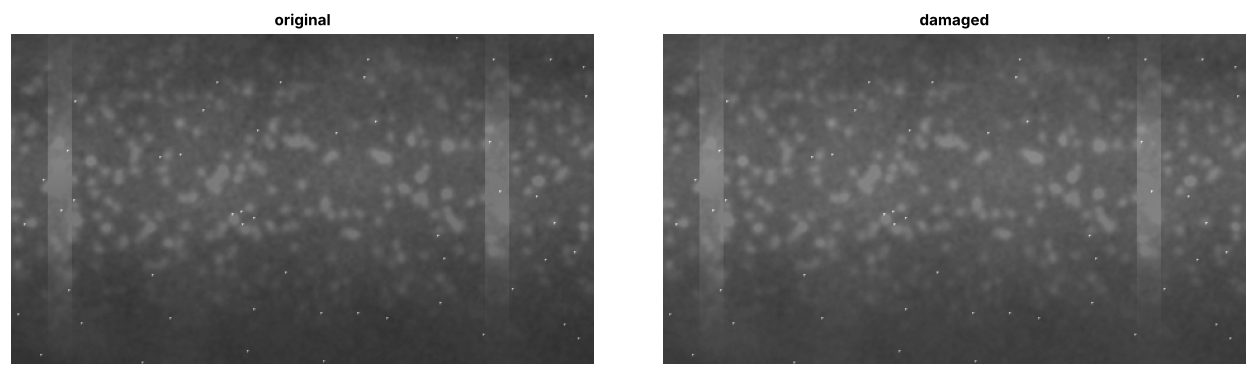

In [34]:
from scipy.ndimage import gaussian_filter

REF_Y = CLIP_Y.copy()


def psnr_np(a, b):
    mse = np.mean((a - b) ** 2); return 99.0 if mse == 0 else 10 * np.log10(255 ** 2 / mse)


def ssim_np(a, b, sigma=1.5):
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, mu_b = gaussian_filter(a, sigma), gaussian_filter(b, sigma)
    s_a = gaussian_filter(a * a, sigma) - mu_a ** 2; s_b = gaussian_filter(b * b, sigma) - mu_b ** 2
    s_ab = gaussian_filter(a * b, sigma) - mu_a * mu_b
    return float((((2 * mu_a * mu_b + c1) * (2 * s_ab + c2)) / ((mu_a ** 2 + mu_b ** 2 + c1) * (s_a + s_b + c2))).mean())


def metric_view(brightness, blur, noise, blocks):
    img = REF_Y.copy()
    if blocks > 1:
        h, w = img.shape[0] // blocks * blocks, img.shape[1] // blocks * blocks
        small = img[:h, :w].reshape(h // blocks, blocks, w // blocks, blocks).mean(axis=(1, 3))
        img[:h, :w] = np.repeat(np.repeat(small, blocks, 0), blocks, 1)
    if blur:
        img = gaussian_filter(img, blur)
    if noise:
        img = img + np.random.default_rng(0).normal(0, noise, img.shape)
    img = np.clip(img + brightness, 0, 255)
    cards([("PSNR", f"{psnr_np(REF_Y, img):.1f} dB", "pixel by pixel"), ("SSIM", f"{ssim_np(REF_Y, img):.3f}", "local structure"),
           ("your eyes", "?", "does the detail survive?")])
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
    for ax, a, t in zip(axs, (REF_Y, img), ("original", "damaged")):
        ax.imshow(a[300:560, 560:1020], cmap="gray", vmin=0, vmax=255); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()


panel("metric", "Fool the metrics", "Brightness, blur, noise and blocks",
      {"brightness": ("int", (-30, 30, 2), 8, "brightness shift"), "blur": ("options", [0, 0.5, 1.0, 1.5, 2.5], 0, "blur (σ px)"),
       "noise": ("options", [0, 3, 6, 12], 0, "noise (σ)"), "blocks": ("options", [1, 4, 8, 16], 1, "blockiness (px)")}, metric_view, live=True)

In [35]:
if HAS["libvmaf"]:
    for q in (23, 38):
        f = e6[(e6.codec == "H.264 (x264 medium)") & (e6.q == q)].iloc[0].file
        r = run([FFMPEG, "-hide_banner", "-i", str(f), "-i", str(SRC), "-lavfi", "[0:v][1:v]libvmaf", "-f", "null", "-"])
        print(f"x264 CRF {q}: VMAF =", re.search(r"VMAF score: ([\d.]+)", r["stderr"]).group(1))
else:
    print("VMAF is not available in this FFmpeg build (no 'libvmaf' filter).")
    print("To try it: install an FFmpeg build with --enable-libvmaf (e.g. the static builds linked from ffmpeg.org),")
    print("then run:  ffmpeg -i distorted.mp4 -i reference.mkv -lavfi \"[0:v][1:v]libvmaf\" -f null -")

VMAF is not available in this FFmpeg build (no 'libvmaf' filter).
To try it: install an FFmpeg build with --enable-libvmaf (e.g. the static builds linked from ffmpeg.org),
then run:  ffmpeg -i distorted.mp4 -i reference.mkv -lavfi "[0:v][1:v]libvmaf" -f null -


**Look for**
- A brightness shift of 8 drops PSNR a lot while SSIM hardly moves. A blur of 1.5 px does the opposite damage to the detail.
- VMAF is the best match to viewers for TV and film, but nobody trained it on ROV tasks. For us the final test is the pilot (experiments E24 and E25).

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 40 · ACTIVITY 3 · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">The blind test</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Rank five clips by quality, guess the bitrates, then reveal.</div>
</div>

**Try it.** Press **Encode**: you get five crops of the same frame at five hidden bitrates, labelled A to E in random order. Rank them and guess each bitrate. Then tick **reveal** and press Encode again (it's cached, so it's instant). Change the round number for a new set.

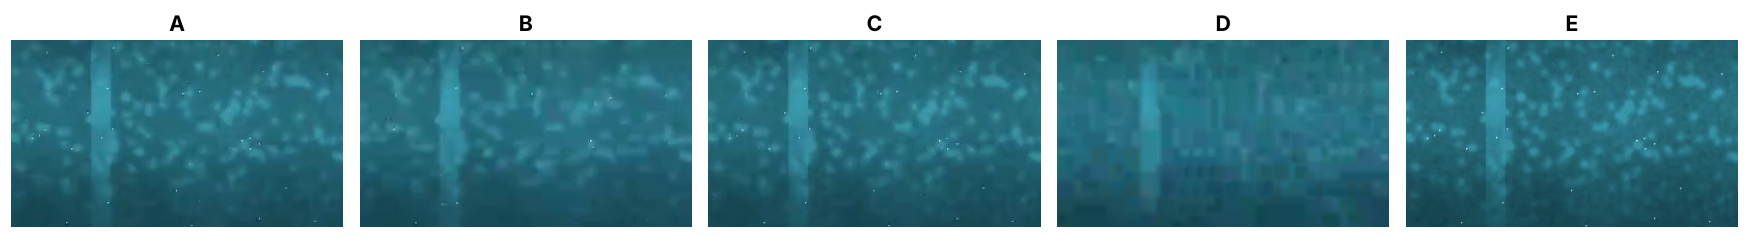

In [36]:
def blind_view(round_no, reveal):
    rng = np.random.default_rng(round_no)
    crfs = sorted(rng.choice(np.arange(18, 47, 2), 5, replace=False).tolist())
    clips = [(crf, encode_cached(["-c:v", "libx264", "-preset", "veryfast", "-crf", str(crf)], "blind")) for crf in crfs]
    order = rng.permutation(5)
    y0, x0 = int(0.48 * H), int(0.40 * W)
    fig, axs = plt.subplots(1, 5, figsize=(16, 3))
    for ax, letter, k in zip(axs, "ABCDE", order):
        ax.imshow(frame_png(clips[k][1]["file"], 2.0, f"blind_{letter}")[y0:y0 + 180, x0:x0 + 320]); ax.set_title(letter, fontsize=14, fontweight="bold"); ax.axis("off")
    plt.tight_layout(); plt.show()
    if reveal:
        rows = [{"clip": letter, "CRF": clips[k][0], "bitrate": rate(clips[k][1]["bitrate"]),
                 "PSNR (dB)": round(clips[k][1]["psnr"], 1), "SSIM": round(clips[k][1]["ssim"], 3)} for letter, k in zip("ABCDE", order)]
        display(pd.DataFrame(rows).sort_values("SSIM", ascending=False).style.hide(axis="index"))
    else:
        note("Rank A–E from best to worst and write a bitrate guess under each. Then tick reveal.")


panel("blind", "Blind test", "Five hidden bitrates, one frame",
      {"round_no": ("int", (1, 20, 1), 1, "round"), "reveal": ("check", None, False, "reveal the answers")}, blind_view)

<div style="border-radius:18px; padding:22px 26px; margin:40px 0 6px; background:#1d1d1f; color:#ffffff">
<div style="font-size:11px; letter-spacing:.3em; color:#ff8a8a">PART 04 · SLIDES 41–53</div>
<div style="font-size:26px; font-weight:800; margin-top:6px">Hardware, protocols and latency</div>
<div style="font-size:14px; color:#c8c8c8; margin-top:4px">Who does the work, how the bits travel, and where the milliseconds go.</div>
</div>

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 42 · WHO DOES THE WORK? · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Is the hardware encoder really there?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Listed is not working: always try a one-second encode.</div>
</div>

In [37]:
def board_model():
    for f in ("/proc/device-tree/model", "/sys/firmware/devicetree/base/model"):
        try: return Path(f).read_text(errors="ignore").strip("\x00\n ")
        except Exception: pass
    return platform.processor() or platform.machine()
IS_JETSON = Path("/etc/nv_tegra_release").exists()
MODEL = board_model(); IS_PI5 = "Raspberry Pi 5" in MODEL
print(f"Machine: {MODEL} | Jetson: {IS_JETSON} | Raspberry Pi 5: {IS_PI5} | cores: {CPU_CORES}")
if IS_JETSON: print(Path("/etc/nv_tegra_release").read_text().strip())

# Try each hardware encoder FFmpeg knows about with a 1-second test pattern. Being listed ≠ working!
TRY = {"h264_nvenc (NVIDIA desktop GPU)": ["-c:v", "h264_nvenc"],
       "h264_qsv (Intel Quick Sync)": ["-c:v", "h264_qsv"],
       "h264_vaapi (Intel/AMD via VA-API)": ["-vaapi_device", "/dev/dri/renderD128", "-vf", "format=nv12,hwupload", "-c:v", "h264_vaapi"],
       "h264_v4l2m2m (V4L2 mem2mem, e.g. Raspberry Pi 4)": ["-c:v", "h264_v4l2m2m"]}
rows = []
for name, args in TRY.items():
    pre = args[:2] if args[0] == "-vaapi_device" else []; post = args[2:] if pre else args
    r = run([FFMPEG, "-hide_banner", "-loglevel", "error", *pre, "-f", "lavfi", "-i", "testsrc2=size=1280x720:rate=30",
             "-t", "1", *post, "-f", "null", "-"], check=False)
    rows.append({"encoder": name, "listed in ffmpeg -encoders": HAS.get(name.split()[0], False),
                 "works on this machine": r["rc"] == 0, "error (first line)": "" if r["rc"] == 0 else (r["stderr"].strip().splitlines() or ["?"])[0][:90]})
display(pd.DataFrame(rows).style.hide(axis="index"))
print("→ An encoder appearing in `ffmpeg -encoders` only means FFmpeg was COMPILED with it. Always run a test encode.")

Machine: x86_64 | Jetson: False | Raspberry Pi 5: False | cores: 2


encoder,listed in ffmpeg -encoders,works on this machine,error (first line)
h264_nvenc (NVIDIA desktop GPU),True,False,[h264_nvenc @ 0x5573f049d880] Cannot load libcuda.so.1
h264_qsv (Intel Quick Sync),True,False,[h264_qsv @ 0x563ff4712880] Error creating a MFX session: -9.
h264_vaapi (Intel/AMD via VA-API),True,False,[AVHWDeviceContext @ 0x55f76ef79040] No VA display found for device /dev/dri/renderD128.
"h264_v4l2m2m (V4L2 mem2mem, e.g. Raspberry Pi 4)",True,False,[h264_v4l2m2m @ 0x55aa08e2b880] Could not find a valid device


→ An encoder appearing in `ffmpeg -encoders` only means FFmpeg was COMPILED with it. Always run a test encode.


**Look for**
- An encoder in `ffmpeg -encoders` only means FFmpeg was built with it. On a laptop without the GPU, every hardware encoder above fails.
- On a Jetson Nano the encoder is used through GStreamer (`nvv4l2h264enc`), not upstream FFmpeg. On a Raspberry Pi 5 there is no H.264 hardware encoder at all.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 43–45 · JETSON NANO VS RASPBERRY PI 5 · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">How many streams can the ROV computer encode?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Measure one core here, then compare with the boards.</div>
</div>

First we measure how many frames per second **one core of this computer** encodes with x264 (PyAV if installed, otherwise FFmpeg with one thread).

In [38]:
from fractions import Fraction
try:
    import av
    HAVE_AV = True
except ImportError:
    HAVE_AV = False
    print("PyAV is not installed (pip install av): using FFmpeg with one thread instead.")

src_frames = []
if HAVE_AV:
    with av.open(str(SRC)) as cont:
        for i, fr in enumerate(cont.decode(video=0)):
            src_frames.append(fr.reformat(format="yuv420p"))
            if i >= 89:
                break

In [39]:
def one_core_fps(w, h, preset="ultrafast", n=60):
    """Frames per second that ONE thread of x264 sustains at w×h (encode time only)."""
    if HAVE_AV:
        frames = [f.reformat(width=w, height=h, format="yuv420p") for f in src_frames[:n]]
        ctx = av.CodecContext.create("libx264", "w"); ctx.width, ctx.height, ctx.pix_fmt = w, h, "yuv420p"
        ctx.time_base = Fraction(1, FPS); ctx.framerate = Fraction(FPS, 1); ctx.thread_count = 1
        ctx.options = {"preset": preset, "tune": "zerolatency", "b": "2500k"}
        t0 = time.perf_counter()
        for i, fr in enumerate(frames):
            fr.pts = i; ctx.encode(fr)
        ctx.encode(None); return n / (time.perf_counter() - t0)
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-vf", f"scale={w}:{h}", "-c:v", "libx264",
             "-preset", preset, "-tune", "zerolatency", "-threads", "1", "-b:v", "2500k", "-f", "null", "-"])
    return N_FRAMES / r["wall_s"]          # fallback: includes scaling cost
cap = []
for (w, h) in ((640, 360), (1280, 720), (1920, 1080)):
    for pr in ("ultrafast", "veryfast"):
        fps1 = one_core_fps(w, h, pr)
        cap.append({"resolution": f"{w}×{h}", "preset": pr, "fps on ONE core": fps1, "30-FPS streams per core (upper bound)": fps1 / 30,
                    f"streams on {max(CPU_CORES-1,1)} spare cores": fps1 / 30 * max(CPU_CORES - 1, 1)})
display(pd.DataFrame(cap).style.format({"fps on ONE core": "{:.0f}", "30-FPS streams per core (upper bound)": "{:.1f}",
                                         f"streams on {max(CPU_CORES-1,1)} spare cores": "{:.1f}"}).hide(axis="index"))

resolution,preset,fps on ONE core,30-FPS streams per core (upper bound),streams on 1 spare cores
640×360,ultrafast,912,30.4,30.4
640×360,veryfast,236,7.9,7.9
1280×720,ultrafast,403,13.4,13.4
1280×720,veryfast,81,2.7,2.7
1920×1080,ultrafast,206,6.9,6.9
1920×1080,veryfast,43,1.4,1.4


**Try it.** Now plan the ROV computer. The Jetson Nano's encoder is rated 4 × 1080p30 (NVIDIA). The Pi 5 has no encoder; Raspberry Pi's April 2026 white paper measured 0.62–0.9 of one Cortex-A76 core per 1080p30 low-latency stream. These are vendor numbers, not ours: soak-test before you buy (slide 45).

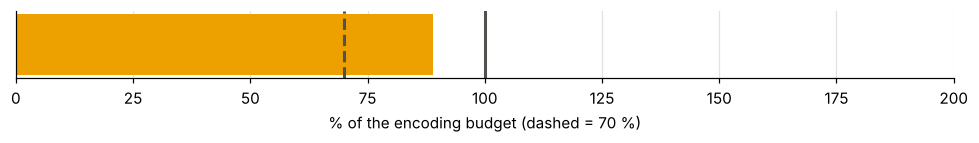

In [40]:
BOARD_RES = {"640×360": (640, 360), "1280×720": (1280, 720), "1920×1080": (1920, 1080)}
P1080 = 1920 * 1080 * 30


def board_view(board, streams, res, fps, pi_core_cost, free_cores):
    w, h = BOARD_RES[res]; px = streams * w * h * fps
    if board == "Jetson Nano":
        load = px / (4 * P1080); fit = int(4 * P1080 // (w * h * fps)); detail = "share of the hardware encoder"
    elif board == "Raspberry Pi 5":
        need = px / P1080 * pi_core_cost; load = need / free_cores
        fit = int(free_cores / (w * h * fps / P1080 * pi_core_cost)); detail = f"{need:.1f} of {free_cores} free cores"
    else:
        load, fit, detail = 0.0, 99, "the computer only forwards packets"
    cards([("load", f"{load:.0%}", detail, load <= 0.7),
           ("streams that fit", "any" if fit >= 99 else f"{fit}", f"{res} @ {fps} fps"),
           ("verdict", "OK" if load <= 0.7 else ("tight" if load <= 1 else "over"), "plan for 70 % or less", load <= 0.7)])
    plt.figure(figsize=(9, 1.4)); plt.barh([0], [min(load, 2) * 100], color=GOOD if load <= 0.7 else (PALETTE[3] if load <= 1 else BAD), height=0.5)
    plt.axvline(70, ls="--", color="#52514e"); plt.axvline(100, color="#52514e"); plt.xlim(0, 200); plt.yticks([])
    plt.xlabel("% of the encoding budget (dashed = 70 %)"); plt.tight_layout(); plt.show()


panel("board", "Encoder budget", "Who encodes decides which board wins",
      {"board": ("toggle", ["Jetson Nano", "Raspberry Pi 5", "Cameras encode themselves"], "Jetson Nano", "who encodes"),
       "streams": ("int", (1, 8, 1), 8, "streams"), "res": ("options", list(BOARD_RES), "1280×720", "resolution"),
       "fps": ("options", [10, 15, 30], 30, "fps"), "pi_core_cost": ("options", [0.62, 0.76, 0.9], 0.76, "Pi 5 cores per 1080p30"),
       "free_cores": ("options", [1.0, 2.0, 2.5, 3.0, 3.5], 2.5, "Pi 5 cores free for video")}, board_view, live=True)

**Look for**
- Eight 720p30 streams fit the Nano's encoder (9 × 720p30 is its limit). On a Pi 5 the same job needs far more cores than it has.
- If the cameras encode themselves, the board only forwards packets, and the Pi 5's faster CPU becomes the better choice.
- Also watch out for the Jetson **Orin** Nano: no hardware video encoder at all.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 46 · RELIABILITY LESSON FROM 2023 · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Read the throttle flags</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">The stream died from heat; the Pi tells you if it has throttled.</div>
</div>

**Try it.** On a Raspberry Pi run `vcgencmd get_throttled` and paste the value here (for example `0x50005`). `0x0` means nothing ever happened. To log it every second during a soak test:

```bash
while true; do echo "$(date +%T) $(vcgencmd measure_temp) $(vcgencmd get_throttled)"; sleep 1; done | tee soak.log
```

In [41]:
THROTTLE_BITS = {0: "under-voltage now", 1: "CPU frequency capped now", 2: "throttled now", 3: "soft temperature limit now",
                 16: "under-voltage has happened since boot", 17: "frequency capping has happened", 18: "throttling has happened",
                 19: "soft temperature limit has happened"}


def throttle_view(value):
    try:
        v = int(value.strip().split("=")[-1], 0)
    except ValueError:
        print("Type a value like 0x50005."); return
    rows = [{"bit": b, "meaning": m, "set?": "YES" if v >> b & 1 else "no"} for b, m in THROTTLE_BITS.items()]
    power, heat = v & 0x10001, v & 0xE000E
    cards([("value", hex(v), "0x0 = nothing ever happened", v == 0),
           ("power", "problem" if power else "OK", "supply sagged below 4.63 V" if power else "no under-voltage", not power),
           ("heat / clocks", "problem" if heat else "OK", "the CPU slowed itself down" if heat else "never throttled", not heat)])
    display(pd.DataFrame(rows).style.hide(axis="index"))
    if power:
        note("Fix the power first: a separate regulated 5 V for the computer and cameras, thicker and shorter wires.")
    elif heat:
        note("Heat path to the hull (thermal pad → aluminium plate → hull → water), less software encoding, soak-test 30 min.")


panel("throttle", "Throttle flags", "Decode vcgencmd get_throttled",
      {"value": ("text", None, "0x50005", "get_throttled value")}, throttle_view, live=True)

bit,meaning,set?
0,under-voltage now,YES
1,CPU frequency capped now,no
2,throttled now,YES
3,soft temperature limit now,no
16,under-voltage has happened since boot,YES
17,frequency capping has happened,no
18,throttling has happened,YES
19,soft temperature limit has happened,no


<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 47 · GETTING BITS TO THE BROWSER · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">TCP or UDP when packets get lost?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">UDP loses a little and never waits. TCP never loses and waits.</div>
</div>

**Try it.** This is a **simulation**, not a measurement. Video flows at a fixed rate over a link. With UDP, a lost packet damages the picture until the next keyframe, but the delay never changes. With TCP, a lost packet holds everything behind it until it's resent; the queue then drains with whatever spare capacity the link has. Push the stream close to the link speed and watch what TCP does.

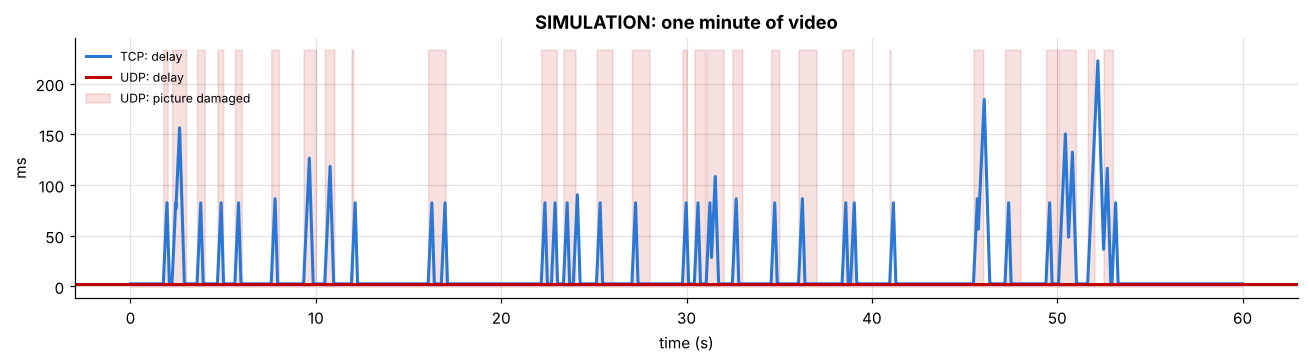

In [42]:
def transport_view(link, stream, loss_pct, rtt_ms, retransmit, gop_s):
    dt, seconds = 0.01, 60
    n = int(seconds / dt); rng = np.random.default_rng(4)
    pkts = stream * 1e6 / 8 / 1316 * dt                          # packets per step
    losses = rng.poisson(pkts * loss_pct / 100, n)
    stall = 3 * rtt_ms / 1000 if retransmit.startswith("fast") else 0.2
    backlog, blocked_until, tcp = 0.0, -1.0, np.empty(n)
    damaged = np.zeros(n, bool); next_key = np.ceil(np.arange(n) * dt / gop_s) * gop_s
    for i in range(n):
        t = i * dt
        if losses[i]:
            blocked_until = max(blocked_until, t + stall)
            damaged[i:int(next_key[i] / dt) + 1] = True             # UDP: broken until the next keyframe
        arrive = stream * 1e6 * dt
        sent = 0.0 if t < blocked_until else min(link * 1e6 * dt, backlog + arrive)
        backlog += arrive - sent
        tcp[i] = rtt_ms / 2 + backlog / (link * 1e6) * 1000
    t = np.arange(n) * dt
    if stream >= link:
        note("The video is bigger than the link. UDP would drop the excess every second; TCP queues it and the delay never stops growing.")
    cards([("UDP delay", f"{rtt_ms / 2:.1f} ms", "constant"),
           ("UDP picture damaged", f"{damaged.mean():.1%}", "of the time, until each next keyframe", damaged.mean() < 0.02),
           ("TCP delay, median", f"{np.median(tcp):,.0f} ms", "queue behind lost packets"),
           ("TCP delay, worst", f"{tcp.max():,.0f} ms", "in this minute", tcp.max() < 150)])
    fig, ax = plt.subplots(figsize=(12, 3.4))
    ax.plot(t, tcp, color=PALETTE[0], label="TCP: delay"); ax.axhline(rtt_ms / 2, color=MIA_RED, label="UDP: delay")
    ax.fill_between(t, 0, np.where(damaged, ax.get_ylim()[1] if tcp.max() > 1 else 1, 0), color=MIA_RED, alpha=0.12, step="mid", label="UDP: picture damaged")
    ax.set_xlabel("time (s)"); ax.set_ylabel("ms"); ax.set_title("SIMULATION: one minute of video"); ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()


panel("transport", "TCP vs UDP", "Same link, same loss, two transports",
      {"link": ("options", [10, 20, 50, 100], 20, "link (Mb/s)"), "stream": ("float", (1, 19, 0.5), 8, "video (Mb/s)"),
       "loss_pct": ("options", [0, 0.01, 0.05, 0.1, 0.5, 1.0], 0.1, "packet loss (%)"),
       "rtt_ms": ("options", [1, 5, 20, 50], 5, "round trip (ms)"),
       "gop_s": ("options", [0.5, 1.0, 2.0, 5.0], 1.0, "keyframe every (s)"),
       "retransmit": ("toggle", ["fast retransmit (3 × RTT)", "timeout (200 ms)"], "timeout (200 ms)", "TCP resends after")}, transport_view, live=True)

**Look for**
- With UDP the delay is flat; loss shows up as damaged moments that end at the next keyframe (so a short GOP matters, slide 39).
- With TCP nothing is damaged, but every loss adds a pause. When the video uses most of the link, the queue never catches up: that's the "latency that grows during the dive".
- That's why the pilot stream uses RTP over UDP or WebRTC, and never HLS.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 48 · EXPERIMENT 9 ESTIMATE · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Build your own latency budget</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">FPS is not latency: a perfect 30 fps stream can be two seconds late.</div>
</div>

**Try it.** Pick each stage the way our system is set up today, then fix the biggest bar first. These are **estimates** built from typical values and our one measured number (x264 defaults hold 41 frames). Measure the real total with the ms-clock photo (slide 57, experiment E1).

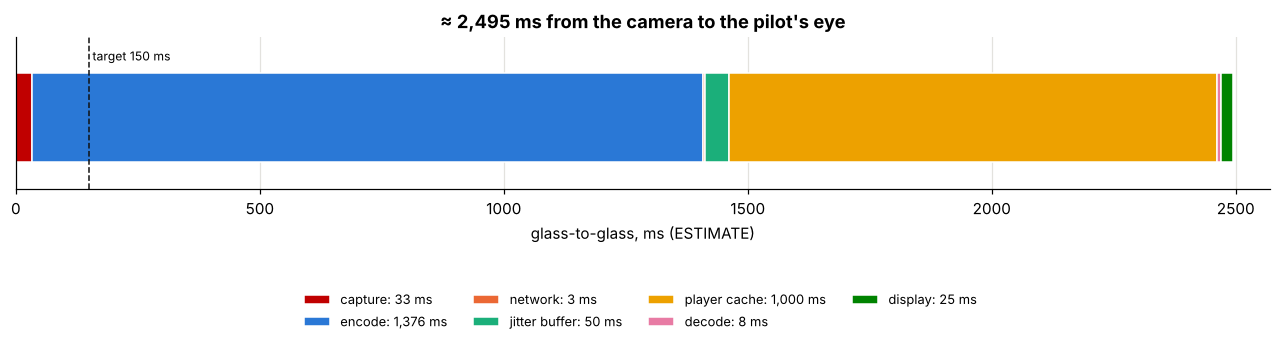

In [43]:
ENCODER_HOLD = {"x264 zerolatency (0 frames)": 0, "MJPEG (0 frames)": 0, "x264 defaults (41 frames)": 41}
PLAYER = {"low-delay player (0 ms)": 0, "VLC default cache (1,000 ms)": 1000, "HLS in a browser (≈ 6,000 ms)": 6000}
SCREEN = {"monitor 60 Hz (≈ 17 ms)": 17, "TV in game mode (≈ 25 ms)": 25, "TV, normal mode (≈ 100 ms)": 100}


def budget_view(fps, encoder, encode_ms, network_ms, jitter_ms, player, decode_ms, screen):
    stages = {"capture": 1000 / fps, "encode": ENCODER_HOLD[encoder] * 1000 / fps + encode_ms, "network": network_ms,
              "jitter buffer": jitter_ms, "player cache": PLAYER[player], "decode": decode_ms, "display": SCREEN[screen]}
    total = sum(stages.values()); worst = max(stages, key=stages.get)
    cards([("glass-to-glass", f"{total:,.0f} ms", "target ≤ 150 ms", total <= 150),
           ("biggest stage", worst, f"{stages[worst]:,.0f} ms: fix this first"),
           ("network share", f"{network_ms / total:.0%}", "the cable is rarely the problem")])
    fig, ax = plt.subplots(figsize=(12, 3.2)); left = 0
    for k, (name, v) in enumerate(stages.items()):
        ax.barh(0, v, left=left, color=[MIA_RED, *PALETTE][k % 9], edgecolor="white", height=0.5, label=f"{name}: {v:,.0f} ms")
        left += v
    ax.axvline(150, color="#111", ls="--", lw=1); ax.text(150, 0.32, " target 150 ms", fontsize=8)
    ax.set_ylim(-0.4, 0.45); ax.set_xlim(0, max(left, 160) * 1.03); ax.set_yticks([])
    ax.set_xlabel("glass-to-glass, ms (ESTIMATE)"); ax.set_title(f"≈ {left:,.0f} ms from the camera to the pilot's eye")
    fig.legend(ncol=4, fontsize=8.5, loc="lower center", frameon=False); fig.subplots_adjust(left=0.03, right=0.98, top=0.85, bottom=0.42)
    plt.show()


panel("budget", "Latency budget", "Where the milliseconds go",
      {"encoder": ("toggle", list(ENCODER_HOLD), "x264 defaults (41 frames)", "encoder"),
       "player": ("toggle", list(PLAYER), "VLC default cache (1,000 ms)", "player"),
       "screen": ("toggle", list(SCREEN), "TV in game mode (≈ 25 ms)", "screen"),
       "fps": ("options", [15, 25, 30, 60], 30, "camera fps"), "encode_ms": ("int", (1, 40, 1), 9, "encode time (ms)"),
       "network_ms": ("options", [1, 3, 10, 30], 3, "network (ms)"), "jitter_ms": ("options", [0, 15, 30, 50, 100, 200], 50, "jitter buffer (ms)"),
       "decode_ms": ("int", (1, 30, 1), 8, "decode (ms)")}, budget_view, live=True)

**Look for**
- The default setup on the slide is about 2.4 s; zerolatency + a low-delay player + game mode gets it near 130 ms. The cable is a few ms either way.
- Check the pipeline in this order: player buffer, encoder hold, screen, then everything else.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 49 · EXPERIMENT 9 MEASURED · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">How many frames does the encoder hold?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">x264 defaults hold about a second; zerolatency holds none.</div>
</div>

In [44]:
ENC_CONFIGS = {
    "x264 medium (defaults)":                 {"preset": "medium"},
    "x264 medium, no B-frames":               {"preset": "medium", "bf": "0"},
    "x264 medium, no B-frames, no lookahead": {"preset": "medium", "bf": "0", "x264-params": "rc-lookahead=0:sync-lookahead=0"},
    "x264 ultrafast":                         {"preset": "ultrafast"},
    "x264 veryfast + tune zerolatency":       {"preset": "veryfast", "tune": "zerolatency"},
}
enc_delay = {}
if HAVE_AV:
    for label, opts in ENC_CONFIGS.items():
        ctx = av.CodecContext.create("libx264", "w")
        ctx.width, ctx.height, ctx.pix_fmt = W, H, "yuv420p"
        ctx.time_base = Fraction(1, FPS); ctx.framerate = Fraction(FPS, 1); ctx.options = dict(opts)
        first_out, times = None, []
        for i, fr in enumerate(src_frames):
            fr.pts = i
            t0 = time.perf_counter(); pkts = ctx.encode(fr); times.append(time.perf_counter() - t0)
            if pkts and first_out is None:
                first_out = i
        ctx.encode(None)
        held = first_out if first_out is not None else len(src_frames)
        enc_delay[label] = {"frames held before first output": held, "delay from holding (ms)": held * 1000 / FPS,
                            "time per encode() call (ms)": 1000 * np.mean(times[10:])}
    display(pd.DataFrame(enc_delay).T.style.format("{:.0f}", subset=["frames held before first output", "delay from holding (ms)"])
            .format("{:.1f}", subset=["time per encode() call (ms)"]))
else:
    print("Needs PyAV (pip install av). The slide's numbers: defaults held 41 frames (≈ 1,367 ms), zerolatency 0.")

,frames held before first output,delay from holding (ms),time per encode() call (ms)
x264 medium (defaults),41,1367,13.6
"x264 medium, no B-frames",41,1367,13.1
"x264 medium, no B-frames, no lookahead",1,33,14.7
x264 ultrafast,1,33,2.2
x264 veryfast + tune zerolatency,0,0,9.1


The other half of latency is on the receiver: the **jitter buffer**. **Try it:** a bigger buffer means fewer late frames and more delay.

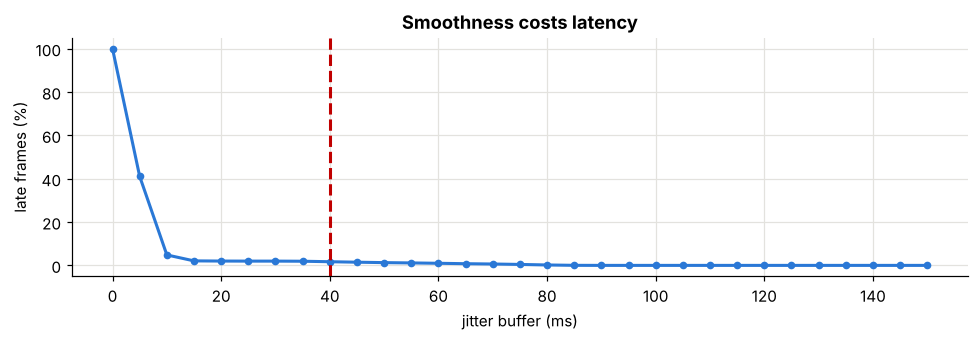

In [45]:
def jitter_view(jitter_ms, spike_pct, buffer_ms):
    rng = np.random.default_rng(1); n = 30 * 120
    delay = 2 + rng.gamma(2.0, jitter_ms / 2, n) + np.where(rng.random(n) < spike_pct / 100, rng.uniform(30, 80, n), 0)
    buffers = np.arange(0, 151, 5); late = [(delay > b).mean() * 100 for b in buffers]
    cards([("late frames", f"{(delay > buffer_ms).mean():.1%}", "arrive after the buffer gave up", (delay > buffer_ms).mean() < 0.01),
           ("latency added", f"{buffer_ms} ms", "every frame waits this long"),
           ("p95 network delay", f"{np.percentile(delay, 95):.0f} ms", "size the buffer near this")])
    plt.figure(figsize=(9, 3.2)); plt.plot(buffers, late, "o-", color=PALETTE[0], ms=4)
    plt.axvline(buffer_ms, color=MIA_RED, ls="--"); plt.xlabel("jitter buffer (ms)"); plt.ylabel("late frames (%)")
    plt.title("Smoothness costs latency"); plt.tight_layout(); plt.show()


panel("jitter", "Jitter buffer", "Two minutes of simulated frame arrivals",
      {"jitter_ms": ("options", [1, 3, 6, 10, 20], 3, "everyday jitter (ms)"), "spike_pct": ("options", [0, 0.5, 1, 2, 5], 2, "frames hit by a spike (%)"),
       "buffer_ms": ("int", (0, 150, 5), 40, "buffer (ms)")}, jitter_view, live=True)

**Look for**
- Each preset holds a different number of frames; `zerolatency` holds 0. That one flag is worth about a second.
- On a clean tether a 30–60 ms buffer is usually enough. Wi-Fi hops and congested switches push it up.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 50 · EXPERIMENT 8 · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Eight cameras on one tether</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Main streams for what the pilot watches, substreams for the rest.</div>
</div>

First the budget for whole configurations (bits per pixel calibrated from the codec curves above), then a panel to try your own.

In [46]:
P_REF = W * H
OVERHEAD = {"RTP/UDP": 1538 / 1460 - 1, "MPEG-TS/UDP": (1382 / 1316) * (188 / 184) - 1,
            "WebRTC (SRTP/UDP)": 0.07, "MJPEG over HTTP (TCP)": 0.06}
RES = {"320×180": (320, 180), "640×360": (640, 360), "640×480": (640, 480), "1280×720": (1280, 720), "1920×1080": (1920, 1080)}

def cam_mbps(codec, res, fps):
    w, h = RES[res]
    return CODEC_BPP[codec] * w * h * fps * (P_REF / (w * h)) ** 0.25 / 1e6

def simulate(name, cams, transport="RTP/UDP"):
    """cams: list of (count, codec, resolution, fps). Returns total on-the-wire Mb/s."""
    total = sum(n * cam_mbps(c, r, f) for n, c, r, f in cams)
    return {"scenario": name, "video_Mb/s": total, "wire_Mb/s": total * (1 + OVERHEAD[transport]), "transport": transport}

SCENARIOS = [
    simulate("8 × MJPEG 640×480@30 (a common student setup)", [(8, "MJPEG", "640×480", 30)], "MJPEG over HTTP (TCP)"),
    simulate("8 × MJPEG 1280×720@30", [(8, "MJPEG", "1280×720", 30)], "MJPEG over HTTP (TCP)"),
    simulate("8 × MJPEG 1920×1080@30", [(8, "MJPEG", "1920×1080", 30)], "MJPEG over HTTP (TCP)"),
    simulate("8 × H.264 1280×720@30", [(8, "H.264", "1280×720", 30)]),
    simulate("8 × H.264 1920×1080@30", [(8, "H.264", "1920×1080", 30)]),
    simulate("1 main H.264 1080p30 + 7 subs 640×360@15", [(1, "H.264", "1920×1080", 30), (7, "H.264", "640×360", 15)]),
    simulate("2 main 1080p30 + 2 subs + 4 thumbnails 320×180@5", [(2, "H.264", "1920×1080", 30), (2, "H.264", "640×360", 15), (4, "H.264", "320×180", 5)]),
]
if "H.265" in CODEC_BPP:
    SCENARIOS.append(simulate("8 × H.265 1920×1080@30", [(8, "H.265", "1920×1080", 30)]))
sim = pd.DataFrame(SCENARIOS)
LINK = 100; HEADROOM = 0.70
def verdict(x, link=LINK):
    return "OVER capacity" if x > link else ("Above 70 % — tight" if x > HEADROOM * link else "OK")
sim["on 100 Mb/s"] = sim["wire_Mb/s"].apply(lambda x: verdict(x, 100))
sim["on 1 Gb/s"] = sim["wire_Mb/s"].apply(lambda x: verdict(x, 1000))
display(sim.style.format({"video_Mb/s": "{:.1f}", "wire_Mb/s": "{:.1f}"}).hide(axis="index"))

scenario,video_Mb/s,wire_Mb/s,transport,on 100 Mb/s,on 1 Gb/s
8 × MJPEG 640×480@30 (a common student setup),33.0,35.0,MJPEG over HTTP (TCP),OK,OK
8 × MJPEG 1280×720@30,75.2,79.7,MJPEG over HTTP (TCP),Above 70 % — tight,OK
8 × MJPEG 1920×1080@30,138.2,146.5,MJPEG over HTTP (TCP),OVER capacity,OK
8 × H.264 1280×720@30,10.0,10.6,RTP/UDP,OK,OK
8 × H.264 1920×1080@30,18.4,19.4,RTP/UDP,OK,OK
1 main H.264 1080p30 + 7 subs 640×360@15,3.9,4.1,RTP/UDP,OK,OK
2 main 1080p30 + 2 subs + 4 thumbnails 320×180@5,5.2,5.4,RTP/UDP,OK,OK
8 × H.265 1920×1080@30,23.7,24.9,RTP/UDP,OK,OK


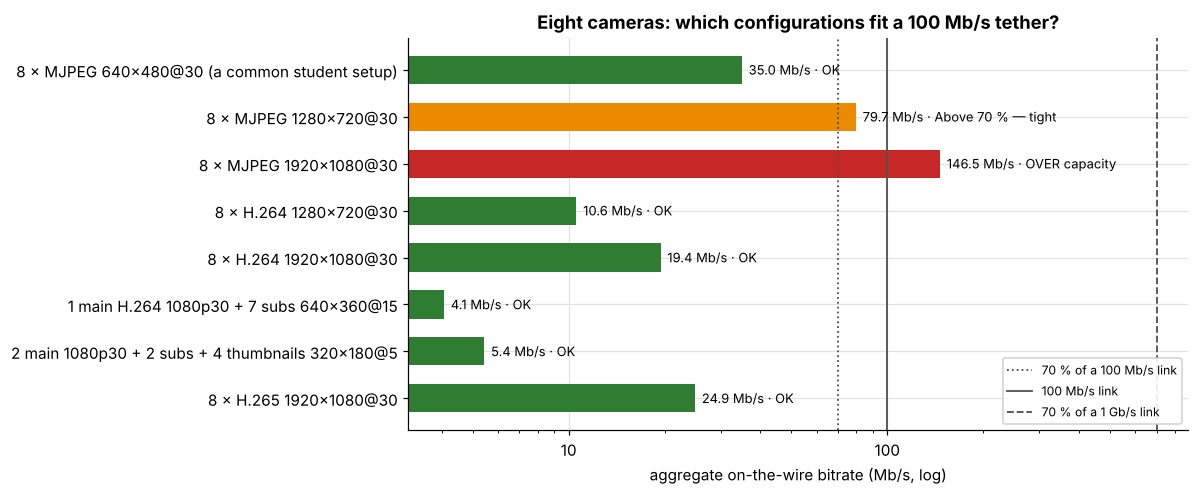

In [47]:
STATUS = {"OK": "#2e7d32", "Above 70 % — tight": "#ed8b00", "OVER capacity": CRITICAL}
fig, ax = plt.subplots(figsize=(11, 4.6))
y = np.arange(len(sim))
ax.barh(y, sim["wire_Mb/s"], color=[STATUS[v] for v in sim["on 100 Mb/s"]], height=0.6)
for yi, (v, s) in enumerate(zip(sim["wire_Mb/s"], sim["on 100 Mb/s"])):
    ax.text(v * 1.05, yi, f"{v:.1f} Mb/s · {s}", va="center", fontsize=8.5)
for x_, lab, ls in ((LINK * HEADROOM, "70 % of a 100 Mb/s link", ":"), (LINK, "100 Mb/s link", "-"), (1000 * HEADROOM, "70 % of a 1 Gb/s link", "--")):
    ax.axvline(x_, color="#52514e", ls=ls, lw=1.2, label=lab)
ax.legend(loc="lower right", fontsize=8, frameon=True, framealpha=0.9)
ax.set_yticks(y, sim["scenario"]); ax.invert_yaxis(); ax.set_xscale("log"); ax.xaxis.set_major_formatter(FuncFormatter(mbps_fmt))
ax.set_xlabel("aggregate on-the-wire bitrate (Mb/s, log)"); ax.set_title("Eight cameras: which configurations fit a 100 Mb/s tether?")
ax.set_xlim(right=sim["wire_Mb/s"].max() * 6); plt.tight_layout(); plt.show()

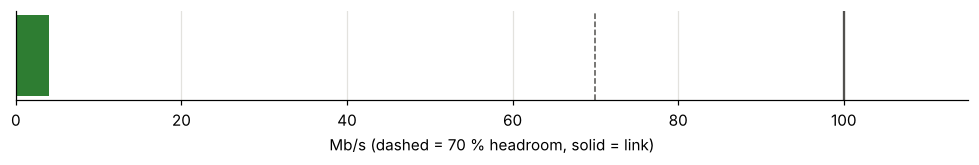

In [48]:
def explore(n_main=1, main_res="1920×1080", main_fps=30, n_sub=7, sub_res="640×360", sub_fps=15,
            codec="H.264", link_mbps=100, transport="RTP/UDP"):
    s = simulate("custom", [(n_main, codec, main_res, main_fps), (n_sub, codec, sub_res, sub_fps)], transport)
    u = s["wire_Mb/s"] / link_mbps; v = verdict(s["wire_Mb/s"], link_mbps)
    cards([("on the wire", f"{s['wire_Mb/s']:.1f} Mb/s", f"{transport}"), ("link use", f"{u:.0%}", v, v == "OK"),
           ("cameras", f"{n_main + n_sub}", f"{n_main} main + {n_sub} sub")])
    fig, ax = plt.subplots(figsize=(9, 1.6))
    ax.barh([0], [s["wire_Mb/s"]], color=STATUS[v], height=0.5)
    ax.axvline(link_mbps * HEADROOM, ls="--", color="#52514e", lw=1); ax.axvline(link_mbps, color="#52514e", lw=1.5)
    ax.set_xlim(0, max(link_mbps, s["wire_Mb/s"]) * 1.15); ax.set_yticks([]); ax.set_xlabel("Mb/s (dashed = 70 % headroom, solid = link)")
    plt.tight_layout(); plt.show()

panel("e7", "Eight-camera budget", "Instant calculation: change anything and the verdict updates",
             {"n_main": ("int", (0, 8, 1), 1, "main streams"), "main_res": ("options", list(RES), "1920×1080", "main resolution"),
              "main_fps": ("int", (5, 60, 5), 30, "main fps"), "n_sub": ("int", (0, 8, 1), 7, "substreams"),
              "sub_res": ("options", list(RES), "640×360", "sub resolution"), "sub_fps": ("int", (1, 30, 1), 15, "sub fps"),
              "codec": ("options", list(CODEC_BPP), "H.264", "codec"), "link_mbps": ("options", [100, 1000], 100, "link (Mb/s)"),
              "transport": ("options", list(OVERHEAD), "RTP/UDP", "transport")}, explore, live=True)

In [49]:
# EXERCISE: describe YOUR vehicle here (count, codec, resolution, fps) and run the cell.
my_design = [(1, "H.264", "1280×720", 30), (3, "H.264", "640×360", 15), (4, "MJPEG", "320×180", 5)]
r = simulate("my design", my_design); print(r, "→", verdict(r["wire_Mb/s"], 100), "on 100 Mb/s")

{'scenario': 'my design', 'video_Mb/s': 2.7038842891060604, 'wire_Mb/s': 2.8483383812637815, 'transport': 'RTP/UDP'} → OK on 100 Mb/s


Now real substreams: we encode a main stream, a substream and a thumbnail and look at them at the size of a tile on the pilot's screen.

,bitrate_Mb/s,SSIM (upscaled to 720p)
"main 1280×720@30, 2.5 Mb/s",2.475,0.983
"sub 640×360@15, 0.4 Mb/s",0.417,0.955
"thumb 320×180@10, 0.12 Mb/s",0.125,0.939


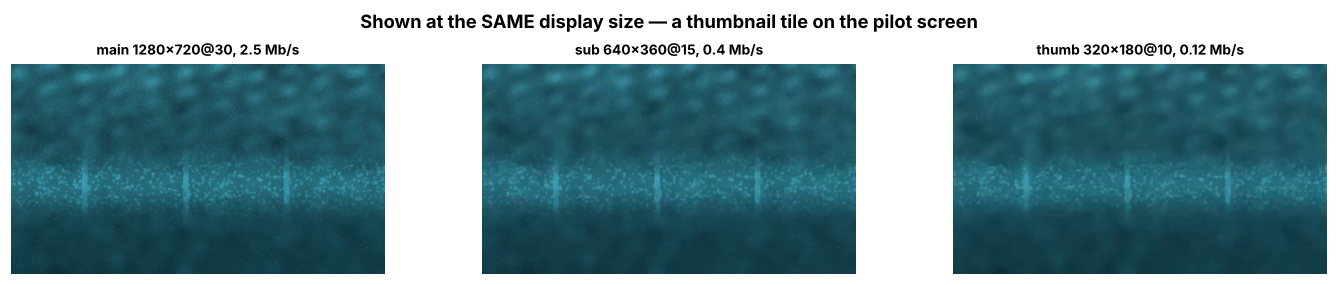

In [50]:
STREAMS = {
    "main 1280×720@30, 2.5 Mb/s":  (1280, 720, 30, 2500),
    "sub 640×360@15, 0.4 Mb/s":    (640, 360, 15, 400),
    "thumb 320×180@10, 0.12 Mb/s": (320, 180, 10, 120),
}
rows = {}
for label, (w, h, fps, kb) in STREAMS.items():
    out = WORK / f"e8_{w}x{h}.mp4"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-vf", f"scale={w}:{h}:flags=area,fps={fps}",
             "-c:v", "libx264", "-preset", "veryfast", "-tune", "zerolatency", "-b:v", f"{kb}k", "-maxrate", f"{kb}k",
             "-bufsize", f"{kb // 2}k", "-g", str(fps), "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)   # scored after upscaling back to 1280×720
    rows[label] = {"bitrate_Mb/s": p["bitrate_mbps"], "SSIM (upscaled to 720p)": ssim, "file": out}
e8 = pd.DataFrame(rows).T
display(e8.drop(columns="file").astype(float).style.format("{:.3f}"))

fig, axs = plt.subplots(1, 3, figsize=(13, 2.6))
for ax, (label, row) in zip(axs, rows.items()):
    png = WORK / f"e8_{Path(str(row['file'])).stem}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", "2.0", "-i", str(row["file"]), "-frames:v", "1", str(png)])
    ax.imshow(plt.imread(png)); ax.set_title(label, fontsize=9); ax.axis("off")
plt.suptitle("Shown at the SAME display size — a thumbnail tile on the pilot screen", fontweight="bold"); plt.tight_layout(); plt.show()

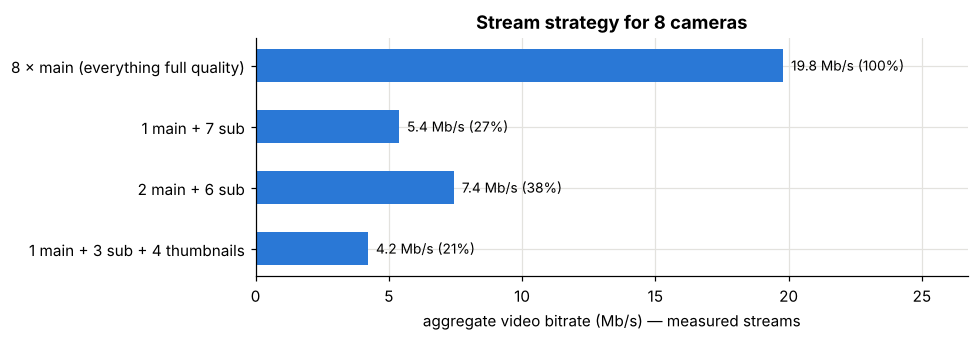

In [51]:
m, s, t = (float(e8.iloc[i]["bitrate_Mb/s"]) for i in range(3))
strategies = {"8 × main (everything full quality)": 8 * m, "1 main + 7 sub": m + 7 * s, "2 main + 6 sub": 2 * m + 6 * s,
              "1 main + 3 sub + 4 thumbnails": m + 3 * s + 4 * t}
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(list(strategies), list(strategies.values()), color=PALETTE[0], height=0.55)
for yi, v in enumerate(strategies.values()):
    ax.text(v, yi, f"  {v:.1f} Mb/s ({v / strategies['8 × main (everything full quality)']:.0%})", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("aggregate video bitrate (Mb/s) — measured streams"); ax.set_title("Stream strategy for 8 cameras")
ax.set_xlim(right=max(strategies.values()) * 1.35); plt.tight_layout(); plt.show()

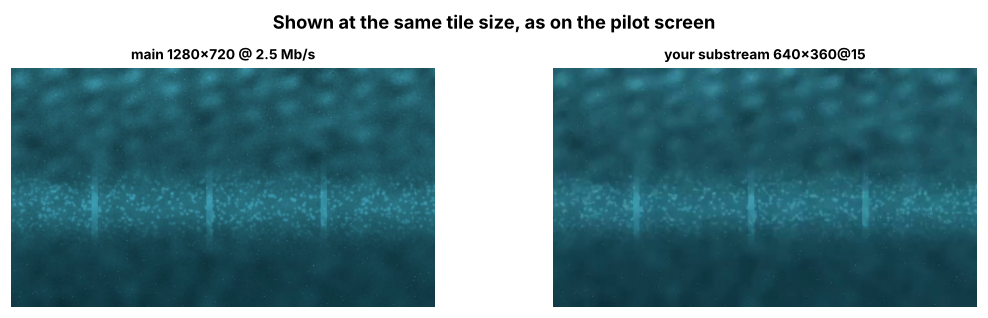

In [52]:
def tune_substream(width, fps, kbps):
    w = int(width); h = int(round(w * 9 / 16 / 2) * 2)
    args = ["-c:v", "libx264", "-preset", "veryfast", "-tune", "zerolatency", "-b:v", f"{kbps}k", "-maxrate", f"{kbps}k",
            "-bufsize", f"{kbps // 2}k", "-g", str(fps)]
    res = encode_cached(args, "e8", vf=f"scale={w}:{h}:flags=area,fps={fps}")
    main = float(e8.iloc[0]["bitrate_Mb/s"]); total = main + 7 * res["bitrate"]
    cards([("substream", f"{res['bitrate']:.2f} Mb/s", f"{w}×{h} @ {fps} fps"),
           ("SSIM (upscaled)", f"{res['ssim']:.3f}", "0.95+ is fine for a thumbnail", res["ssim"] >= 0.95),
           ("1 main + 7 of these", f"{total:.1f} Mb/s", f"{total / (8 * main):.0%} of eight main streams", True),
           ("saving", f"{8 * main - total:.1f} Mb/s", "free for the pilot view or headroom")])
    fig, axs = plt.subplots(1, 2, figsize=(10, 2.9))
    for ax, (path, cap) in zip(axs, ((e8.iloc[0]["file"], "main 1280×720 @ 2.5 Mb/s"), (res["file"], f"your substream {w}×{h}@{fps}"))):
        ax.imshow(frame_png(path, 2.0, "e8_" + str(abs(hash(cap)))), extent=(0, 16, 0, 9)); ax.set_title(cap, fontsize=9); ax.axis("off")
    plt.suptitle("Shown at the same tile size, as on the pilot screen", fontweight="bold"); plt.tight_layout(); plt.show()

panel("e8", "Design a substream", "How small can a thumbnail stream be before it stops being useful?",
             {"width": ("options", [256, 320, 426, 512, 640, 854, 960], 640, "width (16:9)"),
              "fps": ("int", (2, 30, 1), 15, "fps"),
              "kbps": ("options", [60, 100, 150, 250, 400, 600, 1000], 400, "bitrate (kb/s)")}, tune_substream)

**Look for**
- 1 main + 7 substreams needs roughly a quarter of "everything at full quality" (slide 50: 5.4 vs 19.8 Mb/s).
- A substream only has to answer "is something happening there?" When the pilot makes a camera big, switch it to the main stream.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 51 · CAMERA SELECTION · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Share a shrinking tether</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Give every camera its minimum by priority, then top up.</div>
</div>

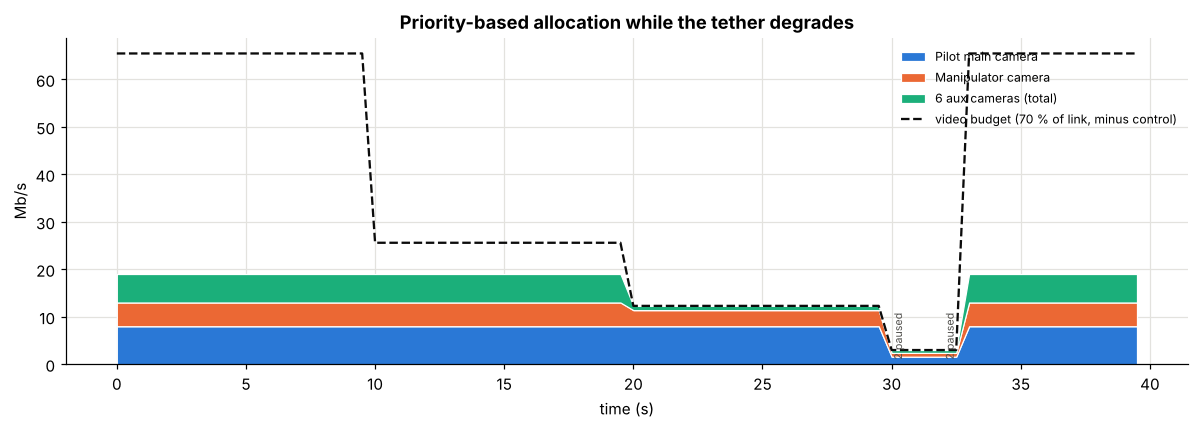

In [53]:
def allocate(budget, cams):
    """cams: list of dicts with name, priority (1 = highest), min, max (Mb/s). Returns {name: Mb/s} (0 = paused)."""
    alloc = {c["name"]: 0.0 for c in cams}; order = sorted(cams, key=lambda c: c["priority"]); left = budget
    for c in order:                                    # pass 1: minimums, highest priority first
        if left >= c["min"]: alloc[c["name"]] = c["min"]; left -= c["min"]
    for c in order:                                    # pass 2: top up to max, highest priority first
        if alloc[c["name"]] > 0:
            add = min(c["max"] - alloc[c["name"]], left); alloc[c["name"]] += add; left -= add
    return alloc

CAMS = ([{"name": "Pilot main camera", "priority": 1, "min": 1.5, "max": 8.0},
         {"name": "Manipulator camera", "priority": 2, "min": 0.8, "max": 5.0}] +
        [{"name": f"Aux camera {i}", "priority": 3 + i, "min": 0.15, "max": 1.0} for i in range(1, 7)])
t = np.arange(0, 40, 0.5)
capacity = np.where(t < 10, 100, np.where(t < 20, 40, np.where(t < 30, 20, np.where(t < 33, 6, 100))))
budget = capacity * HEADROOM / (1 + OVERHEAD["RTP/UDP"]) - 1.0     # 1 Mb/s reserved for control + telemetry
series = pd.DataFrame([allocate(b, CAMS) for b in budget], index=t)
groups = {"Pilot main camera": series["Pilot main camera"], "Manipulator camera": series["Manipulator camera"],
          "6 aux cameras (total)": series.filter(like="Aux").sum(axis=1)}
fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(t, *groups.values(), labels=groups.keys(), colors=PALETTE[:3], edgecolor="white", linewidth=0.8)
ax.plot(t, budget, color="#0b0b0b", lw=1.5, ls="--", label="video budget (70 % of link, minus control)")
paused = series.filter(like="Aux").eq(0).sum(axis=1)
for tt, n in zip(t[::4], paused.values[::4]):
    if n: ax.text(tt, 1.5, f"{n} paused", fontsize=7, rotation=90, color="#52514e")
ax.set_xlabel("time (s)"); ax.set_ylabel("Mb/s"); ax.set_title("Priority-based allocation while the tether degrades")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

**Try it.** Shrink the link and see who keeps their bits. Tick **gripping** to make the manipulator camera priority 1.

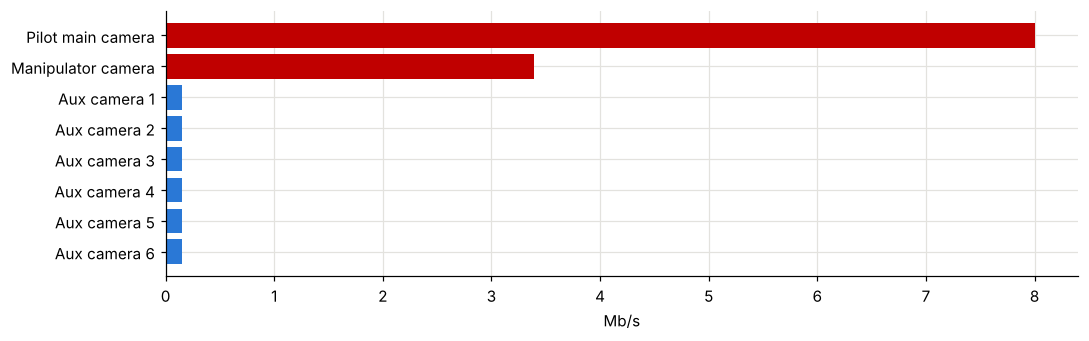

In [54]:
def share_view(link_mbps, gripping):
    cams = [dict(c) for c in CAMS]
    if gripping:
        cams[1]["priority"] = 0.5
    budget = max(link_mbps * HEADROOM / (1 + OVERHEAD["RTP/UDP"]) - 1.0, 0)
    alloc = allocate(budget, cams)
    paused = [k for k, v in alloc.items() if v == 0]
    cards([("video budget", rate(budget), "70 % of the link, minus 1 Mb/s for control"),
           ("pilot camera", rate(alloc["Pilot main camera"]), "min 1.5 · max 8", alloc["Pilot main camera"] > 0),
           ("manipulator", rate(alloc["Manipulator camera"]), "priority 1 while gripping" if gripping else "priority 2"),
           ("paused", f"{len(paused)}", "shown as PAUSED on the pilot screen", len(paused) == 0)])
    names = list(alloc)
    plt.figure(figsize=(10, 3.2))
    plt.barh(names, [alloc[k] for k in names], color=[GREY if alloc[k] == 0 else (MIA_RED if i < 2 else PALETTE[0]) for i, k in enumerate(names)])
    for i, k in enumerate(names):
        if alloc[k] == 0: plt.text(0.05, i, "PAUSED", va="center", fontsize=8, color=GREY)
    plt.gca().invert_yaxis(); plt.xlabel("Mb/s"); plt.tight_layout(); plt.show()


panel("share", "Priority allocator", "The tether degrades; the pilot camera stays sharp",
      {"link_mbps": ("options", [2, 4, 6, 10, 20, 40, 100], 20, "link (Mb/s)"), "gripping": ("check", None, False, "manipulator is gripping")}, share_view, live=True)

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 52 · STREAMING FOR COMPUTER VISION · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">What compression does to corners</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Feature trackers (SLAM, photogrammetry) need the corners the encoder throws away.</div>
</div>

**Try it.** We find the 200 strongest corners in the original frame (Shi–Tomasi, the kind ORB and SLAM use), then look for them again after encoding. Raise the CRF and watch them disappear.

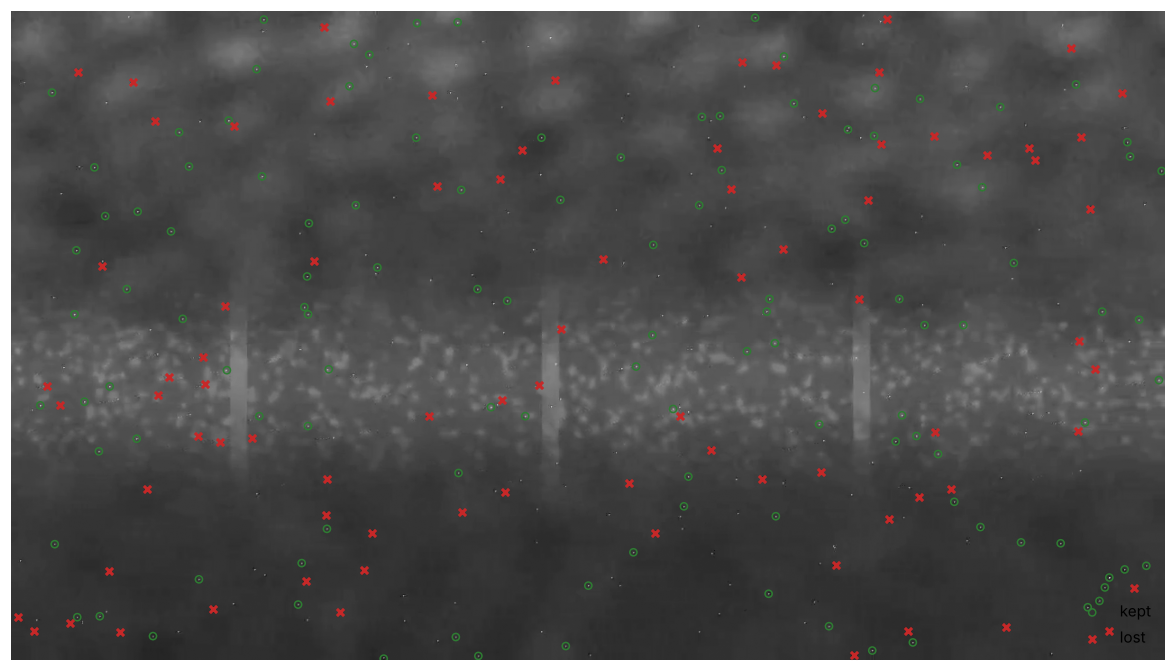

In [55]:
from scipy.ndimage import sobel, maximum_filter
from scipy.spatial import cKDTree


def corners(g, n=200):
    """The n strongest Shi–Tomasi corners: points where the image changes in two directions."""
    ix, iy = sobel(g, 1), sobel(g, 0)
    a, b, c = gaussian_filter(ix * ix, 1.5), gaussian_filter(iy * iy, 1.5), gaussian_filter(ix * iy, 1.5)
    resp = (a + b) / 2 - np.sqrt(((a - b) / 2) ** 2 + c * c)
    ys, xs = np.nonzero((resp == maximum_filter(resp, 9)) & (resp > 0))
    top = np.argsort(resp[ys, xs])[::-1][:n]
    return np.stack([ys[top], xs[top]], 1)


REF_CORNERS = corners(REF_Y)


def cv_view(crf):
    res = encode_cached(["-c:v", "libx264", "-preset", "veryfast", "-tune", "zerolatency", "-crf", str(crf)], "cv")
    dec = gray(frame_png(res["file"], 2.0, "cv"))
    found = corners(dec)
    d, _ = cKDTree(found).query(REF_CORNERS)
    kept = d <= 2
    cards([("bitrate", rate(res["bitrate"]), f"CRF {crf}"), ("SSIM", f"{res['ssim']:.3f}", "looks fine to a viewer?"),
           ("corners kept", f"{kept.mean():.0%}", "within 2 px of the original", kept.mean() >= 0.8)])
    plt.figure(figsize=(11, 6.2)); plt.imshow(dec, cmap="gray", vmin=0, vmax=255)
    plt.scatter(REF_CORNERS[kept, 1], REF_CORNERS[kept, 0], s=22, facecolors="none", edgecolors=GOOD, label="kept")
    plt.scatter(REF_CORNERS[~kept, 1], REF_CORNERS[~kept, 0], s=22, marker="x", color=BAD, label="lost")
    plt.legend(loc="lower right"); plt.axis("off"); plt.tight_layout(); plt.show()


panel("cv", "Corners after compression", "Green = still found · red = lost",
      {"crf": ("int", (16, 46, 2), 30, "CRF")}, cv_view)

**Look for**
- SSIM can still look respectable while a large share of the corners is gone. A metric for viewers isn't a metric for algorithms.
- Rules from slide 52: run CV next to the raw frames when you can; otherwise give CV its own stream with more bits, no B-frames and timestamps.

<div style="border-radius:18px; padding:22px 26px; margin:40px 0 6px; background:#1d1d1f; color:#ffffff">
<div style="font-size:11px; letter-spacing:.3em; color:#ff8a8a">PART 05 · SLIDES 54–61</div>
<div style="font-size:26px; font-weight:800; margin-top:6px">Diagnostics</div>
<div style="font-size:14px; color:#c8c8c8; margin-top:4px">One cause, one stage. Measure before you change anything.</div>
</div>

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 54 · 72 · WHERE IS THE PROBLEM? · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Latency drift: a queue that only grows</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">30 fps in, 29.7 fps out: 10 ms more delay every second.</div>
</div>

**Try it.** Frames arrive at the camera's rate and leave at the display's rate. If they arrive even slightly faster, a queue grows and nobody notices until the pilot is seconds behind. Then put a limit on the queue.

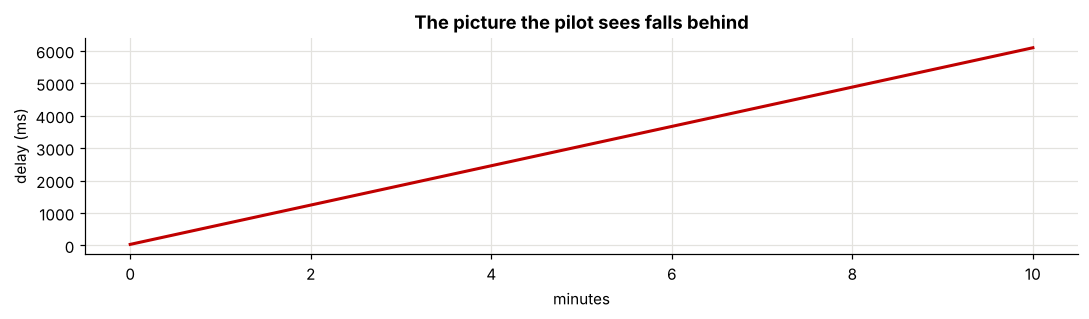

In [56]:
def drift_view(camera_fps, display_fps, queue_limit, minutes):
    t = np.linspace(0, minutes * 60, 600)
    surplus = max(camera_fps - display_fps, 0)                   # frames per second that pile up
    waiting = surplus * t
    if queue_limit != "no limit":
        waiting = np.minimum(waiting, queue_limit)
    latency = 33 + waiting * 1000 / display_fps
    dropped = surplus * minutes * 60 - waiting[-1]
    cards([("delay after", f"{latency[-1] / 1000:.2f} s", f"{minutes} min into the dive", latency[-1] < 150),
           ("growth", f"{surplus * 1000 / display_fps:.0f} ms / s" if queue_limit == "no limit" else "capped",
            "while the queue is unlimited"),
           ("frames dropped", f"{dropped:,.0f}", "the cure: drop old frames, keep new ones")])
    plt.figure(figsize=(10, 3)); plt.plot(t / 60, latency, color=MIA_RED)
    plt.xlabel("minutes"); plt.ylabel("delay (ms)"); plt.title("The picture the pilot sees falls behind"); plt.tight_layout(); plt.show()


panel("drift", "Latency drift", "A rate mismatch you can't see until it's seconds long",
      {"camera_fps": ("options", [25, 29.97, 30, 30.3], 30, "frames in (fps)"), "display_fps": ("options", [25, 29.7, 29.97, 30, 60], 29.7, "frames shown (fps)"),
       "queue_limit": ("options", ["no limit", 1, 2, 5], "no limit", "queue limit (frames)"), "minutes": ("int", (1, 30, 1), 10, "dive length (min)")}, drift_view, live=True)

**Look for**
- 0.3 frames per second of surplus is invisible on any fps counter, and it's still 6 seconds of delay after 10 minutes.
- A queue of 1–2 frames that drops the oldest frame keeps the delay flat. Every queue in the pipeline needs a limit.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 73 · FIELD GUIDE · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">A frozen picture that looks live</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">The fps counter keeps saying 30 while the frame on screen gets older.</div>
</div>

**Try it.** The stream stops for a moment (a crashed encoder, a camera dropping off USB). The renderer keeps redrawing the last frame, so the fps counter never moves. Only the **age of the frame** shows the freeze. Choose when the STALE badge should appear.

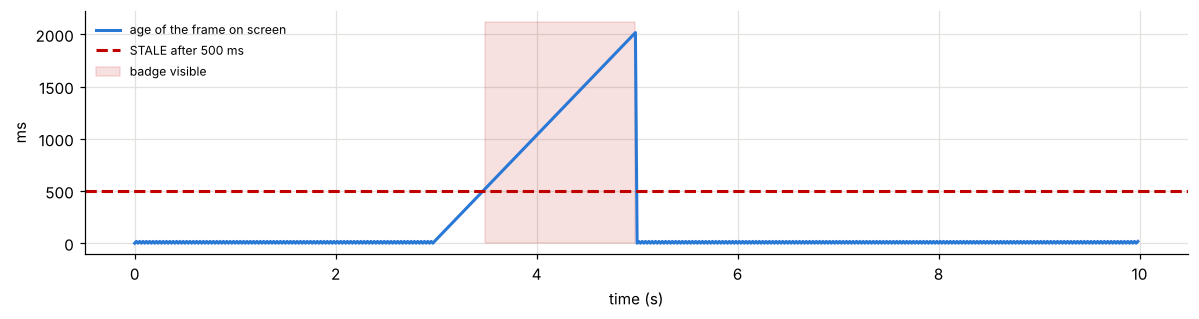

In [57]:
def stale_view(freeze_at, freeze_len, threshold_ms):
    t = np.arange(0, 10, 1 / 60)                                  # the screen refreshes at 60 Hz
    captures = np.arange(0, 10, 1 / 30)
    captures = captures[(captures < freeze_at) | (captures >= freeze_at + freeze_len)]
    last = captures[np.searchsorted(captures, t, side="right") - 1]
    age = (t - last) * 1000
    warned = age > threshold_ms
    blind = (age[(t >= freeze_at) & (t < freeze_at + freeze_len)] <= threshold_ms).sum() / 60
    cards([("fps counter", "30.0", "during the whole freeze", False),
           ("worst frame age", f"{age.max():,.0f} ms", "what the pilot actually saw"),
           ("STALE shown", "never" if not warned.any() else f"after {threshold_ms} ms", "", warned.any()),
           ("driving on an old picture, unwarned", f"{blind:.2f} s", "", blind < 0.6)])
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(t, age, color=PALETTE[0], label="age of the frame on screen")
    ax.axhline(threshold_ms, color=MIA_RED, ls="--", label=f"STALE after {threshold_ms} ms")
    ax.fill_between(t, 0, age.max() * 1.05, where=warned, color=MIA_RED, alpha=0.12, label="badge visible")
    ax.set_xlabel("time (s)"); ax.set_ylabel("ms"); ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()


panel("stale", "Stale frame", "Show the frame's age, not just the fps",
      {"freeze_at": ("float", (1, 7, 0.5), 3, "freeze starts (s)"), "freeze_len": ("options", [0.2, 0.5, 1, 2, 3], 2, "freeze lasts (s)"),
       "threshold_ms": ("options", [100, 250, 500, 1000, 3000], 500, "STALE after (ms)")}, stale_view, live=True)

**Look for**
- The field guide's rule: STALE after 500 ms without a new frame, LOST after a few seconds. Experiment E14 (`kill -STOP` on the encoder) checks whether our GUI does it.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 57 · MEASURE LATENCY THREE WAYS · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Your glass-to-glass readings</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Ten photos of the ms clock: report the median and the worst.</div>
</div>

**Try it.** Type your ten readings from experiment E1 (clock on the screen minus clock in the video, in ms), separated by commas.

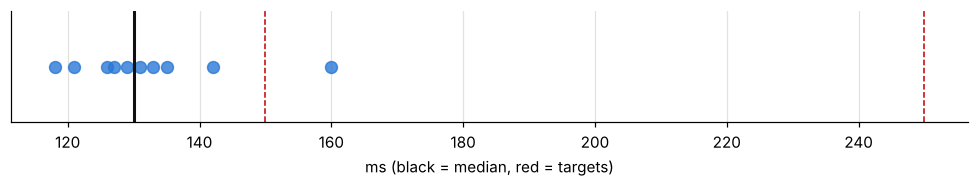

In [58]:
def g2g_view(readings):
    try:
        v = np.array([float(x) for x in readings.replace(";", ",").replace(" ", ",").split(",") if x.strip()])
    except ValueError:
        print("Numbers only, separated by commas."); return
    if len(v) < 3:
        print("Type at least three readings."); return
    med, p95, worst = np.median(v), np.percentile(v, 95), v.max()
    cards([("readings", f"{len(v)}", "10 is the minimum for a report"),
           ("median", f"{med:.0f} ms", "target ≤ 150", med <= 150), ("p95", f"{p95:.0f} ms", "1 in 20 is worse"),
           ("worst", f"{worst:.0f} ms", "target ≤ 250", worst <= 250)])
    plt.figure(figsize=(9, 1.8)); plt.scatter(v, np.zeros_like(v), s=60, color=PALETTE[0], alpha=0.8)
    for x_, lab in ((150, "150"), (250, "250")): plt.axvline(x_, color=MIA_RED, ls="--", lw=1)
    plt.axvline(med, color="#111", lw=2); plt.yticks([]); plt.xlabel("ms (black = median, red = targets)"); plt.tight_layout(); plt.show()


panel("g2g", "Glass-to-glass readings", "Median and worst, never one number",
      {"readings": ("text", None, "126, 131, 118, 142, 129, 135, 121, 160, 127, 133", "readings (ms)")}, g2g_view, live=True)

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 61 · THE CHECKLIST · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Run the health check</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Check in pipeline order. The first ❌ is usually the cause.</div>
</div>

`docs/debug/rov_healthcheck.sh` runs 25 of the debug checklist's 45 checks on the ROV computer in about ten seconds. It only makes sense on the ROV, so this cell prints the command unless you start Jupyter there with `RUN_ON_ROV=1` (add `TOPSIDE=<ip>` and `CAMS=<n>`).

In [59]:
HEALTH = Path("../../docs/debug/rov_healthcheck.sh").resolve()
if os.environ.get("RUN_ON_ROV") == "1" and HEALTH.exists():
    args = ["--md", *(["--top", os.environ["TOPSIDE"]] if os.environ.get("TOPSIDE") else []),
            *(["--cams", os.environ["CAMS"]] if os.environ.get("CAMS") else [])]
    display(Markdown(run(["bash", str(HEALTH), *args], check=False)["stdout"]))
else:
    print("On the ROV computer:\n")
    print(f"    sudo bash {HEALTH.relative_to(HEALTH.parents[2]) if HEALTH.exists() else 'docs/debug/rov_healthcheck.sh'} --top <topside IP> --cams <N>\n")
    print("Paste the --md output into the bug report. Full checklist: docs/debug/ROV_Debug_Checklist.md")

On the ROV computer:

    sudo bash docs/debug/rov_healthcheck.sh --top <topside IP> --cams <N>

Paste the --md output into the bug report. Full checklist: docs/debug/ROV_Debug_Checklist.md


<div style="border-radius:18px; padding:22px 26px; margin:40px 0 6px; background:#1d1d1f; color:#ffffff">
<div style="font-size:11px; letter-spacing:.3em; color:#ff8a8a">PART 06 · SLIDES 62</div>
<div style="font-size:26px; font-weight:800; margin-top:6px">Putting it together</div>
<div style="font-size:14px; color:#c8c8c8; margin-top:4px">Measure → stop wasting bits → stream smart → design latency → design failure → verify.</div>
</div>

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 62 · A PRACTICAL OPTIMIZATION STRATEGY · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Design the eight-camera system</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Every requirement is checked against the numbers measured above.</div>
</div>

In [60]:
ENCODER_BUDGETS = {   # pixel-rate budgets (pixels/s). Jetson Nano: 4×1080p30 ≈ 9×720p30 ≈ 249 Mpx/s (NVIDIA spec).
    "Jetson Nano hardware encoder": 4 * 1920 * 1080 * 30,
    # Raspberry Pi 5: ~0.65–0.9 core per 1080p30 ultrafast (RPi white paper). Assume 2.5 cores free for video, 0.8 core/1080p30:
    "Raspberry Pi 5 software (2.5 cores, ultrafast)": 2.5 / 0.8 * 1920 * 1080 * 30,
    "Cameras encode themselves (IP cameras)": float("inf"),
}

def evaluate(design, throughput_mbps=94, budget_name="Jetson Nano hardware encoder"):
    rows, ok = [], True
    total = sum(cam_mbps(c["codec"], c["res"], c["fps"]) for c in design["cameras"]) * (1 + OVERHEAD[design["transport"]])
    px_rate = sum(RES[c["res"]][0] * RES[c["res"]][1] * c["fps"] for c in design["cameras"] if c.get("encoded_on_sbc", True))
    pilot = next(c for c in design["cameras"] if c["role"] == "pilot"); manip = next(c for c in design["cameras"] if c["role"] == "manipulator")
    def check(rid, cond, detail):
        nonlocal ok; ok &= bool(cond); rows.append({"req": rid, "pass": "✅" if cond else "❌", "detail": detail})
    check("R1", RES[pilot["res"]][1] >= 720 and pilot["fps"] >= 25, f"pilot {pilot['res']}@{pilot['fps']}")
    check("R2", RES[manip["res"]][1] >= 720 and manip["fps"] >= 20, f"manipulator {manip['res']}@{manip['fps']}")
    check("R3", len(design["cameras"]) == 8 and all(c["fps"] >= 5 for c in design["cameras"]), f"{len(design['cameras'])} cameras, min fps {min(c['fps'] for c in design['cameras'])}")
    check("R4", total <= 0.7 * throughput_mbps and throughput_mbps - total >= 2, f"{total:.1f} Mb/s on the wire = {total/throughput_mbps:.0%} of {throughput_mbps}")
    check("R5", px_rate <= ENCODER_BUDGETS[budget_name], f"{px_rate/1e6:.0f} Mpx/s vs budget {ENCODER_BUDGETS[budget_name]/1e6:.0f} Mpx/s ({budget_name})")
    lat = 33 + design["encoder_delay_frames"] * 1000 / pilot["fps"] + 3 + design["jitter_buffer_ms"] + 8 + 25
    check("R6", lat <= 200, f"≈ {lat:.0f} ms (ESTIMATE: capture 33 + encoder hold + network 3 + buffer + decode 8 + display 25)")
    check("R7", design["gop_s"] <= 1.0 or design.get("intra_refresh", False), f"GOP {design['gop_s']} s, intra refresh: {design.get('intra_refresh', False)}")
    display(pd.DataFrame(rows).style.hide(axis="index"))
    print("ALL CHECKS PASS — now write the justification!" if ok else "Not yet — iterate.")
    return ok

# A deliberately naive starting design (it fails). Improve it.
design = {
    "transport": "RTP/UDP", "gop_s": 2.0, "intra_refresh": False, "encoder_delay_frames": 40, "jitter_buffer_ms": 200,
    "cameras": [{"role": "pilot", "codec": "H.264", "res": "1920×1080", "fps": 30},
                {"role": "manipulator", "codec": "H.264", "res": "1920×1080", "fps": 30}] +
               [{"role": "aux", "codec": "H.264", "res": "1920×1080", "fps": 30} for _ in range(6)],
}
evaluate(design)

req,pass,detail
R1,✅,pilot 1920×1080@30
R2,✅,manipulator 1920×1080@30
R3,✅,"8 cameras, min fps 30"
R4,✅,19.4 Mb/s on the wire = 21% of 94
R5,❌,498 Mpx/s vs budget 249 Mpx/s (Jetson Nano hardware encoder)
R6,❌,≈ 1602 ms (ESTIMATE: capture 33 + encoder hold + network 3 + buffer + decode 8 + display 25)
R7,❌,"GOP 2.0 s, intra refresh: False"


Not yet — iterate.


False

The design above fails on purpose. **Try it:** fix it with the panel. Resolution is the last lever you should reach for, not the first.

In [61]:
def design_view(pilot, manip, aux, gop_s, intra_refresh, zerolatency, jitter_ms, board, throughput):
    res_fps = lambda s: (s.split(" @ ")[0], int(s.split(" @ ")[1]))
    (pr, pf), (mr, mf), (ar, af) = res_fps(pilot), res_fps(manip), res_fps(aux)
    design = {"transport": "RTP/UDP", "gop_s": gop_s, "intra_refresh": intra_refresh,
              "encoder_delay_frames": 0 if zerolatency else 40, "jitter_buffer_ms": jitter_ms,
              "cameras": [{"role": "pilot", "codec": "H.264", "res": pr, "fps": pf},
                          {"role": "manipulator", "codec": "H.264", "res": mr, "fps": mf}] +
                         [{"role": "aux", "codec": "H.264", "res": ar, "fps": af} for _ in range(6)]}
    evaluate(design, throughput_mbps=throughput, budget_name=board)


STREAM_CHOICES = [f"{r} @ {f}" for r in RES for f in (5, 10, 15, 20, 25, 30)]
panel("design", "Your design", "Seven requirements, checked live",
      {"pilot": ("dropdown", STREAM_CHOICES, "1920×1080 @ 30", "pilot camera"), "manip": ("dropdown", STREAM_CHOICES, "1920×1080 @ 30", "manipulator"),
       "aux": ("dropdown", STREAM_CHOICES, "1920×1080 @ 30", "each aux camera (6)"),
       "gop_s": ("options", [0.5, 1.0, 2.0, 5.0], 2.0, "keyframe every (s)"), "jitter_ms": ("options", [20, 40, 60, 100, 200], 200, "jitter buffer (ms)"),
       "board": ("dropdown", list(ENCODER_BUDGETS), "Jetson Nano hardware encoder", "who encodes"),
       "throughput": ("options", [94, 940], 94, "measured throughput (Mb/s)"),
       "intra_refresh": ("check", None, False, "intra refresh"), "zerolatency": ("check", None, False, "-tune zerolatency")}, design_view, live=True)

req,pass,detail
R1,✅,pilot 1920×1080@30
R2,✅,manipulator 1920×1080@30
R3,✅,"8 cameras, min fps 30"
R4,✅,19.4 Mb/s on the wire = 21% of 94
R5,❌,498 Mpx/s vs budget 249 Mpx/s (Jetson Nano hardware encoder)
R6,❌,≈ 1602 ms (ESTIMATE: capture 33 + encoder hold + network 3 + buffer + decode 8 + display 25)
R7,❌,"GOP 2.0 s, intra refresh: False"


Not yet — iterate.


**Your deliverable (one page):** the design that passes, why each choice, the numbers it rests on, and which of them you still have to measure on the real ROV. The ROV experiments (`docs/experiments/ROV_Experiments.md`) are where those numbers come from.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 62 · ENGINEERING LOG · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">What this run measured</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Paste these into your team's log.</div>
</div>

In [62]:
# Summary of key numbers measured in this run (paste into your team's engineering log)
summary = {
    "machine": MODEL, "ffmpeg": run([FFMPEG, "-hide_banner", "-version"])["stdout"].splitlines()[0],
    "raw 1080p30 RGB24 (Mb/s)": round(raw_mbps(1920, 1080, 30, 24)),
    "H.264 CRF23 clip bitrate (Mb/s)": round(float(e3[(e3['mode']=='CRF') & (e3['setting']=='crf 23')]['bitrate_Mb/s'].iloc[0]), 2),
    f"SSIM target used": SSIM_TARGET,
    "bits/pixel at target": {k: round(v, 4) for k, v in CODEC_BPP.items()},
    "x264 default encoder hold (frames)": enc_delay.get("x264 medium (defaults)", {}).get("frames held before first output"),
    "x264 zerolatency hold (frames)": enc_delay.get("x264 veryfast + tune zerolatency", {}).get("frames held before first output"),
}
(WORK / "summary.json").write_text(json.dumps(summary, indent=2, default=str)); print(json.dumps(summary, indent=2, default=str))

{
  "machine": "x86_64",
  "ffmpeg": "ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers",
  "raw 1080p30 RGB24 (Mb/s)": 1493,
  "H.264 CRF23 clip bitrate (Mb/s)": 1.9,
  "SSIM target used": 0.981,
  "bits/pixel at target": {
    "H.264": 0.0454,
    "H.265": 0.0583,
    "MJPEG": 0.34,
    "AV1": 0.077
  },
  "x264 default encoder hold (frames)": 41,
  "x264 zerolatency hold (frames)": 0
}
